# 01b - Pilot selection and Hyperion download

**Project:** Computationally Efficient Multimodal Deep Learning for Thermal and Hyperspectral Remote Sensing-Based Urban Heat Analysis and Scenario Prediction  
**Role:** Member 1 - Satellite Data & Preprocessing

**Input:** `handover_pairs.csv` (from Notebook 01, Part E7).  
**Output:** `pilot_pairs.csv`, `pilot_download_options.csv`, then the downloaded Hyperion scenes in `raw/hyperion/`.

Hyperion + Landsat 8 is the primary direction. EMIT and EnMAP are secondary and are not downloaded here.

**Run the cells one at a time. Do not use "Run all".** Download cells are resumable.

## Step 0 - Setup (run first in every session)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, json, requests, getpass
import pandas as pd

ROOT = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
RAW  = f"{ROOT}/raw/hyperion"
os.makedirs(RAW, exist_ok=True)
print("project folder:", ROOT)
print("handover file exists:", os.path.exists(f"{ROOT}/handover_pairs.csv"))

Mounted at /content/drive
project folder: /content/drive/MyDrive/MEMBER1___PREPROCESSING
handover file exists: True


## Step P1 - Choose the pilot pairs

All 4 humid-coastal Hyperion pairs, plus the 3 best semi-arid and 3 best dense-city pairs, each from a different location. About 10 scenes are enough to build and test the whole preprocessing chain before scaling to the full 120.

In [ ]:
h = pd.read_csv(f"{ROOT}/handover_pairs.csv")
hy = h[h.sensor == "HYPERION"].copy()
hy["abs_dt"] = hy["ls_dt"].astype(float).abs()

humid = hy[hy.profile == "humid_coastal"]
semi  = hy[hy.profile == "semi_arid_city"].sort_values(["fit", "abs_dt"], ascending=[False, True]).drop_duplicates("cell_id").head(3)
dens  = hy[hy.profile == "dense_city"].sort_values(["fit", "abs_dt"], ascending=[False, True]).drop_duplicates("cell_id").head(3)
pilot = pd.concat([humid, semi, dens]).reset_index(drop=True)
pilot.to_csv(f"{ROOT}/pilot_pairs.csv", index=False)

print(len(pilot), "pilot pairs")
print(pilot[["scene_id", "acq_datetime", "profile", "lat", "lon", "cloud_pct", "landsat", "ls_ids", "ls_dt"]].to_string(index=False))

10 pilot pairs
                     scene_id              acq_datetime        profile    lat     lon  cloud_pct  landsat                 ls_ids     ls_dt
EO1H1160662016170110PF_AK3_01 2016-06-18 05:00:00+00:00  humid_coastal -8.385 115.365        0.0      NaN 1_LC08_116066_20160620  1.891347
EO1H1160662014200110PF_PF1_01 2014-07-19 05:00:00+00:00  humid_coastal -8.385 115.365       30.0      NaN 1_LC08_116066_20140717 -2.108558
EO1H1160662015098110PF_PF2_01 2015-04-08 05:00:00+00:00  humid_coastal -8.385 115.365       10.0      NaN 1_LC08_116066_20150415  6.891103
EO1H1210652014233110KF_PF1_01 2014-08-21 05:00:00+00:00  humid_coastal -7.125 109.205       10.0      NaN 1_LC08_120065_20140830  8.908478
EO1H1490432016293110Kl_AK3_01 2016-10-19 05:00:00+00:00 semi_arid_city 23.605  72.385       10.0      NaN 1_LC08_149044_20161017 -1.972694
EO1H1510372015364110KF_AK3_01 2015-12-30 06:00:00+00:00 semi_arid_city 32.565  71.545        0.0      NaN 1_LC08_151037_20160101  1.992128
EO1H17703920

## Step P2 - Ask USGS which Hyperion products exist for the pilot scenes

Needs your **ERS username** and an **application token** (ERS -> Profile -> Application Tokens), not your password. Nothing is downloaded here.  
If this step fails with an authorisation or permission error, the account has search rights but not M2M download rights; request download access from USGS support before continuing.

In [ ]:
M2M = "https://m2m.cr.usgs.gov/api/api/json/stable/"
user  = input("USGS ERS username: ")
token = getpass.getpass("USGS application token: ")

def call(ep, payload, key=None):
    hdr = {"X-Auth-Token": key} if key else {}
    r = requests.post(M2M + ep, json=payload, headers=hdr, timeout=120)
    r.raise_for_status()
    j = r.json()
    if j.get("errorCode"):
        raise RuntimeError(f"{ep}: {j['errorCode']} {j['errorMessage']}")
    return j["data"]

KEY = call("login-token", {"username": user, "token": token})
pilot = pd.read_csv(f"{ROOT}/pilot_pairs.csv")
ids = pilot["scene_id"].tolist()

opts = call("download-options", {"datasetName": "eo1_hyp_pub", "entityIds": ids}, KEY)
od = pd.DataFrame([{"entityId": o["entityId"], "productId": o["id"], "product": o["productName"],
                    "available": o["available"], "downloadSystem": o.get("downloadSystem"),
                    "sizeMB": round((o.get("filesize") or 0) / 1e6, 1)} for o in opts])
print(od.groupby(["product", "available"]).size())
print(od.head(12).to_string(index=False))
od.to_csv(f"{ROOT}/pilot_download_options.csv", index=False)

USGS ERS username: <your-username>
USGS application token: ··········
product                                       available
EO-1 HYPERION L1GST BAND CLOUD DOWNLOADS      True         10
EO-1 HYPERION L1T BAND CLOUD DOWNLOADS        True         10
Full Resolution Browse in JPEG format         True         10
GIS Ready Bundle in JPEG format + world file  True         10
L1Gst Product in GeoTiff format               True         10
L1R Product in HDF format                     True         10
L1T Product in GeoTiff format                 False         2
                                              True          8
dtype: int64
                     entityId        productId                                      product  available downloadSystem  sizeMB
EO1H1160662014200110PF_PF1_01 5e83a12ec0086948                    L1R Product in HDF format       True            dds   224.4
EO1H1160662014200110PF_PF1_01 5e83a12e30ce5a85              L1Gst Product in GeoTiff format       True           

## Step P3 - Download the pilot (to be added)

Paste the output of P2 first. The product to download (and the resumable download cell) will be added here after checking the product names.

## Next
Notebook 02: per-sensor preprocessing. Hyperion public products are not surface reflectance, so Notebook 02 needs its own Hyperion branch (bad-band removal, atmospheric correction, clipping to the cell).

In [ ]:
# P3 (fixed): download the pilot scenes (L1T where available, else L1Gst). Resumable.
import re, glob, time

od = pd.read_csv(f"{ROOT}/pilot_download_options.csv")
PREF = [("L1T Product in GeoTiff format", "L1T"), ("L1Gst Product in GeoTiff format", "L1Gst")]

choice = []
for eid, g in od.groupby("entityId"):
    for name, tag in PREF:
        m = g[(g["product"] == name) & (g["available"])]
        if len(m):
            choice.append({"entityId": eid, "productId": m.iloc[0]["productId"], "tag": tag}); break
    else:
        print("NO usable product for", eid)
choice = pd.DataFrame(choice)
todo = choice[[not glob.glob(f"{RAW}/{e}_*") for e in choice["entityId"]]]
print(len(choice) - len(todo), "already downloaded;", len(todo), "to do")

urls = {}
def collect(d):
    for k in ("availableDownloads", "available"):
        for x in (d.get(k) or []):
            if x.get("url") and x.get("entityId"):
                urls[x["entityId"]] = x["url"]

if len(todo):
    # 1) reuse links from earlier pilot_ requests (the failed run already created one)
    labels = call("download-labels", {}, KEY)
    for L in labels:
        if str(L.get("label", "")).startswith("pilot_"):
            collect(call("download-retrieve", {"label": L["label"]}, KEY))
    # 2) request anything still missing
    missing = todo[~todo["entityId"].isin(urls)]
    if len(missing):
        label = "pilot_" + time.strftime("%Y%m%d%H%M%S")
        req = call("download-request", {"downloads": [{"entityId": r.entityId, "productId": r.productId}
                                                      for r in missing.itertuples()],
                                        "label": label, "returnAvailable": True}, KEY)
        collect(req)
        t0 = time.time()
        while not set(missing["entityId"]) <= set(urls) and time.time() - t0 < 600:
            time.sleep(20)
            collect(call("download-retrieve", {"label": label}, KEY))
            print(f"  ready {len(urls)}/{len(todo)}")
    print(f"links ready for {len(urls)}/{len(todo)} scenes")

    tags = dict(zip(choice["entityId"], choice["tag"]))
    for eid in todo["entityId"]:
        if eid not in urls:
            print("no link yet for", eid); continue
        r = requests.get(urls[eid], stream=True, timeout=300)
        r.raise_for_status()
        m = re.search(r'filename="?([^";]+)"?', r.headers.get("Content-Disposition", ""))
        ext = os.path.splitext(m.group(1))[1] if m else ".zip"
        dest = f"{RAW}/{eid}_{tags[eid]}{ext}"
        with open(dest + ".part", "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
        os.rename(dest + ".part", dest)
        print("saved", os.path.basename(dest), round(os.path.getsize(dest) / 1e6, 1), "MB")

print("\nfiles in raw/hyperion:", len(glob.glob(f"{RAW}/*")))

0 already downloaded; 10 to do
links ready for 10/10 scenes
saved EO1H1160662014200110PF_PF1_01_L1Gst.ZIP 197.2 MB
saved EO1H1160662015098110PF_PF2_01_L1Gst.ZIP 221.0 MB
saved EO1H1160662016170110PF_AK3_01_L1T.ZIP 163.6 MB
saved EO1H1190382013102110PF_PF1_01_L1T.ZIP 248.1 MB
saved EO1H1210652014233110KF_PF1_01_L1T.ZIP 238.6 MB
saved EO1H1470392014168110KF_TR2_01_L1T.ZIP 258.6 MB
saved EO1H1490432016293110Kl_AK3_01_L1T.ZIP 555.7 MB
saved EO1H1510372015364110KF_AK3_01_L1T.ZIP 211.8 MB
saved EO1H1770392013283110KF_SG1_01_L1T.ZIP 249.3 MB
saved EO1H1950262015114110K4_SG1_01_L1T.ZIP 534.7 MB

files in raw/hyperion: 10


In [ ]:
# 02-A: unpack ONE scene and inspect what is inside
import os, glob, zipfile, collections
from google.colab import drive
drive.mount("/content/drive")

ROOT = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
RAW  = f"{ROOT}/raw/hyperion"
WORK = "/content/hyp_work"; os.makedirs(WORK, exist_ok=True)

z = sorted(glob.glob(f"{RAW}/*.ZIP"))[2]                  # an L1T scene (the 2016 Bali scene)
name = os.path.basename(z)[:-4]
dest = f"{WORK}/{name}"
if not os.path.exists(dest):
    with zipfile.ZipFile(z) as zf: zf.extractall(dest)

files = sorted(glob.glob(f"{dest}/**/*", recursive=True))
files = [f for f in files if os.path.isfile(f)]
print("scene:", name)
print("files:", len(files), "| total MB:", round(sum(os.path.getsize(f) for f in files) / 1e6, 1))
print("by extension:", dict(collections.Counter(os.path.splitext(f)[1].upper() for f in files)))
print("\nfirst 6 and last 4 files:")
for f in files[:6] + files[-4:]:
    print(" ", os.path.basename(f), round(os.path.getsize(f) / 1e6, 2), "MB")

txt = [f for f in files if f.lower().endswith((".txt", ".met", ".xml", ".hdr"))]
print("\nmetadata files:", [os.path.basename(f) for f in txt])
if txt:
    print("\n--- head of", os.path.basename(txt[0]), "---")
    print(open(txt[0], errors="ignore").read()[:1500])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
scene: EO1H1160662016170110PF_AK3_01_L1T
files: 244 | total MB: 1460.1
by extension: {'.TIF': 242, '.TXT': 2}

first 6 and last 4 files:
  EO1H1160662016170110PF_B001_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_B002_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_B003_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_B004_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_B005_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_B006_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_B241_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_B242_L1T.TIF 6.03 MB
  EO1H1160662016170110PF_MTL_L1T.TXT 0.02 MB
  README.txt 0.01 MB

metadata files: ['EO1H1160662016170110PF_MTL_L1T.TXT', 'README.txt']

--- head of EO1H1160662016170110PF_MTL_L1T.TXT ---
GROUP = L1_METADATA_FILE
  GROUP = METADATA_FILE_INFO
    REQUEST_ID = "1160662016170_20001"
    PRODUCT_CREATION_TIME = 2016-06-25T12:45:33Z
    EO1_XBAND = "1"
    GROUND_STATI

Cell 02-B reads three things from that scene: the scale factors, which bands are empty, and where the data actually sits in the file. It reads every band at reduced size, so it takes about a minute.

In [ ]:
# 02-B: scale factors, empty (uncalibrated) bands, and valid-data footprint of ONE scene
import re, numpy as np
try:
    import rasterio
except ImportError:
    !pip install -q rasterio
    import rasterio

scene_dir = dest
mtl = [f for f in files if f.endswith("_MTL_L1T.TXT")][0]
txt = open(mtl, errors="ignore").read()

print("--- metadata lines about scaling / geometry / cloud ---")
for ln in txt.splitlines():
    if re.search(r"SCAL|GAIN|BIAS|SUN_|ELEV|AZIM|CLOUD|RESAMP|PROJECTION|UTM|DATUM|PIXEL_SIZE|ORIENT|NUMBER_OF|BAND_COUNT|LINES|SAMPLES|FILL|MAP", ln.upper()):
        print(ln.rstrip())

print("\n--- README ---")
print(open(f"{scene_dir}/README.txt", errors="ignore").read()[:2500])

# ---- read every band at 1/4 size: which are empty, valid fraction, mean DN ----
tifs = sorted(f for f in files if f.upper().endswith(".TIF"))
stats = []
with rasterio.open(tifs[49]) as src:                       # B050 as reference
    print("\nB050:", src.shape, src.dtypes[0], "| CRS:", src.crs, "| res:", src.res, "| nodata:", src.nodata)
    ref = src.read(1)
    ref_transform = src.transform
for i, t in enumerate(tifs, start=1):
    with rasterio.open(t) as s:
        a = s.read(1, out_shape=(s.height // 4, s.width // 4))
    nz = a != 0
    stats.append({"band": i, "valid_frac": nz.mean(), "mean_dn": a[nz].mean() if nz.any() else 0.0})
st = pd.DataFrame(stats)

def ranges(v):
    v = sorted(v); out = []; s = p = None
    for x in v:
        if s is None: s = p = x
        elif x == p + 1: p = x
        else: out.append((s, p)); s = p = x
    if s is not None: out.append((s, p))
    return ", ".join(f"{a}-{b}" if a != b else str(a) for a, b in out)

empty = st[st.valid_frac == 0]["band"].tolist()
print("\nbands that are completely empty:", len(empty))
print(ranges(empty))
print("bands with data:", 242 - len(empty), "->", ranges(st[st.valid_frac > 0]["band"].tolist()))

# ---- where is the real data inside the 27.6 km frame? (B050, full resolution) ----
nz = ref != 0
rows = np.where(nz.any(axis=1))[0]; cols = np.where(nz.any(axis=0))[0]
print("\nB050 valid-data pixel box: rows", rows.min(), "-", rows.max(), "| cols", cols.min(), "-", cols.max())
print("valid pixels:", int(nz.sum()), "=", round(nz.sum() * 0.0009, 1), "km2 (30 m pixels)")
print("valid fraction of file:", round(nz.mean(), 3))

--- metadata lines about scaling / geometry / cloud ---
    PRODUCT_UL_CORNER_MAPX = 310500.000000
    PRODUCT_UL_CORNER_MAPY = 9151800.000000
    PRODUCT_UR_CORNER_MAPX = 338100.000000
    PRODUCT_UR_CORNER_MAPY = 9151800.000000
    PRODUCT_LL_CORNER_MAPX = 310500.000000
    PRODUCT_LL_CORNER_MAPY = 9054000.000000
    PRODUCT_LR_CORNER_MAPX = 338100.000000
    PRODUCT_LR_CORNER_MAPY = 9054000.000000
    PRODUCT_SAMPLES = 921
    PRODUCT_LINES = 3261
  GROUP = RADIANCE_SCALING
    SCALING_FACTOR_VNIR = 40
    SCALING_FACTOR_SWIR = 80
  END_GROUP = RADIANCE_SCALING
    CORRECTION_METHOD_GAIN = "NONE"
    CORRECTION_METHOD_BIAS = "NONE"
    SUN_AZIMUTH = 59.667579
    SUN_ELEVATION = 24.265231
    ELEVATION_SOURCE = "SRTM-2"
  GROUP = PROJECTION_PARAMETERS
    REFERENCE_DATUM = "WGS84"
    ORIENTATION = "NUP"
    RESAMPLING_OPTION = "CC"
    MAP_PROJECTION = "UTM"
  END_GROUP = PROJECTION_PARAMETERS
  GROUP = UTM_PARAMETERS
  END_GROUP = UTM_PARAMETERS

--- README ---
USGS EARTH OBSERVIN

In [ ]:
# 02-C: band-quality check + clip ONE scene to its Landsat cell + real coverage
import numpy as np, pandas as pd, rasterio
from rasterio.windows import from_bounds, Window
from rasterio.warp import transform_bounds

# 1) mean DN and valid fraction by band group (uses `st` from 02-B)
groups = {"1-7 (VNIR, uncalibrated)": (1, 7), "8-57 (VNIR, calibrated)": (8, 57),
          "58-76 (gap/overlap, uncalibrated)": (58, 76), "77-224 (SWIR, calibrated)": (77, 224),
          "225-242 (SWIR, uncalibrated)": (225, 242)}
print("band group                               valid_frac   mean_DN   (median over bands)")
for k, (a, b) in groups.items():
    g = st[(st.band >= a) & (st.band <= b)]
    print(f"{k:40s} {g.valid_frac.median():8.3f} {g.mean_dn.median():10.1f}")

# 2) cell of this scene from the pilot table
sid = name.split("_")[0] + "_" + name.split("_")[1] + "_" + name.split("_")[2]   # EO1H..._AK3_01
p = pd.read_csv(f"{ROOT}/pilot_pairs.csv")
row = p[p["scene_id"].str.startswith(name[:22])].iloc[0]
HALF = 0.035
lon0, lat0 = row.lon - HALF, row.lat - HALF
lon1, lat1 = row.lon + HALF, row.lat + HALF
print("\nscene:", row.scene_id, "| cell centre:", row.lon, row.lat, "| profile:", row.profile)

# 3) clip all 242 bands to the cell (bounds converted lon/lat -> UTM)
with rasterio.open(tifs[0]) as s0:
    ub = transform_bounds("EPSG:4326", s0.crs, lon0, lat0, lon1, lat1)
    win = from_bounds(*ub, transform=s0.transform).round_offsets().round_lengths()
    win = win.intersection(Window(0, 0, s0.width, s0.height))
    cell_transform = s0.window_transform(win); crs = s0.crs
cube = np.stack([rasterio.open(t).read(1, window=win) for t in tifs]).astype("int16")
print("clipped cube (bands, rows, cols):", cube.shape)

valid = cube[49] != 0                                   # B050 as the validity mask
print("REAL coverage of the cell by valid Hyperion pixels:", round(float(valid.mean()), 3))

# 4) radiance for a few calibrated bands (DN/40 for bands 1-70, DN/80 for 71-242)
scale = np.where(np.arange(1, 243) <= 70, 40.0, 80.0)[:, None, None]
rad = cube / scale
for b in (20, 40, 50, 100, 150, 200):
    v = rad[b - 1][valid]
    print(f"band {b:3d}: mean radiance over valid pixels = {v.mean():7.2f}  (min {v.min():.1f}, max {v.max():.1f})")

np.save(f"{WORK}/{name}_cell_cube.npy", cube)
print("\nsaved clipped cube to", f"{WORK}/{name}_cell_cube.npy")

band group                               valid_frac   mean_DN   (median over bands)
1-7 (VNIR, uncalibrated)                    0.245        1.0
8-57 (VNIR, calibrated)                     0.246      676.5
58-76 (gap/overlap, uncalibrated)           0.245        1.0
77-224 (SWIR, calibrated)                   0.236       19.9
225-242 (SWIR, uncalibrated)                0.245        1.0

scene: EO1H1160662016170110PF_AK3_01 | cell centre: 115.365 -8.385000000000005 | profile: humid_coastal
clipped cube (bands, rows, cols): (242, 259, 258)
REAL coverage of the cell by valid Hyperion pixels: 0.829
band  20: mean radiance over valid pixels =   20.89  (min 0.0, max 52.0)
band  40: mean radiance over valid pixels =   38.19  (min 0.0, max 98.2)
band  50: mean radiance over valid pixels =   37.30  (min 0.0, max 98.4)
band 100: mean radiance over valid pixels =    0.35  (min 0.0, max 2.8)
band 150: mean radiance over valid pixels =    3.30  (min 0.0, max 13.3)
band 200: mean radiance over valid

Step 4 is band selection. Cell 02-D computes approximate band wavelengths and removes the overlap and water-absorption bands. It then plots the mean radiance spectrum, so you can see where the atmosphere absorbs and check that the removed bands sit on the dips.

calibrated: 198 | overlap dropped: 2 | water dropped: 32 | tail dropped: 5
bands kept: 159
kept band numbers: 8-57, 79-119, 132-163, 184-219


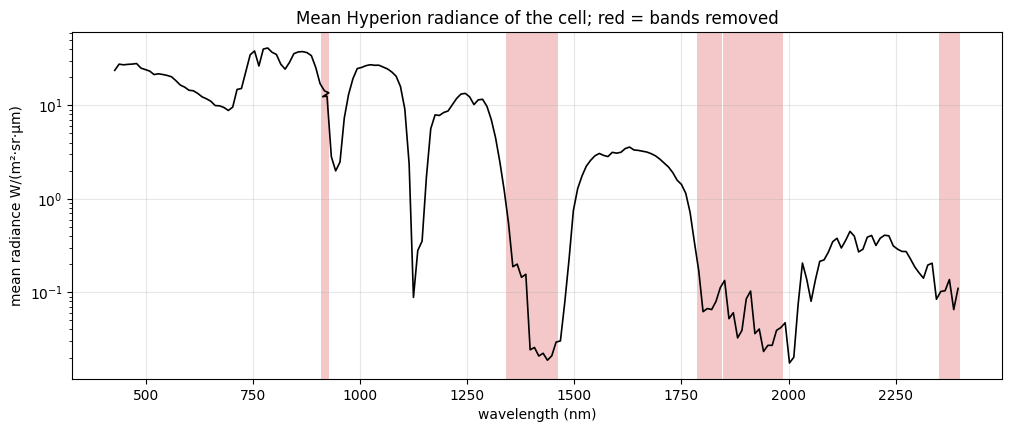

saved config/hyperion_bands.json


In [ ]:
# 02-D: band selection (calibrated bands, overlap, water absorption) + spectrum check
import numpy as np, json
import matplotlib.pyplot as plt

n = np.arange(1, 243)
# approximate band centre wavelengths (nm): VNIR 1-70 and SWIR 71-242 (published Hyperion layout)
wl = np.where(n <= 70, 355.59 + 10.2 * (n - 1), 851.92 + 10.09 * (n - 71))

calibrated = ((n >= 8) & (n <= 57)) | ((n >= 77) & (n <= 224))             # 198 bands (verified: others DN = 1)
overlap    = (n == 77) | (n == 78)                                          # VNIR/SWIR overlap: keep VNIR 56-57, drop SWIR 77-78
WATER = [(1340, 1460), (1790, 1990)]                                        # nm, strong water-vapour absorption
water = np.zeros(242, bool)
for a, b in WATER: water |= (wl >= a) & (wl <= b)
noisy_tail = wl > 2350                                                      # very low signal at the SWIR edge

keep = calibrated & ~overlap & ~water & ~noisy_tail
print("calibrated:", int(calibrated.sum()), "| overlap dropped:", int((calibrated & overlap).sum()),
      "| water dropped:", int((calibrated & water).sum()), "| tail dropped:", int((calibrated & noisy_tail).sum()))
print("bands kept:", int(keep.sum()))
print("kept band numbers:", ", ".join(f"{a}-{b}" for a, b in
      [(g[0], g[-1]) for g in np.split(n[keep], np.where(np.diff(n[keep]) != 1)[0] + 1)]))

# mean radiance spectrum of the clipped scene (uses `rad`, `valid` from 02-C)
spec = np.array([rad[i][valid].mean() for i in range(242)])
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(wl[calibrated], spec[calibrated], lw=1.2, color="k")
for i in np.where(calibrated & ~keep)[0]:
    ax.axvspan(wl[i] - 5, wl[i] + 5, color="tab:red", alpha=0.25, lw=0)
ax.set_yscale("log"); ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("mean radiance W/(m²·sr·µm)")
ax.set_title("Mean Hyperion radiance of the cell; red = bands removed"); ax.grid(alpha=0.3)
plt.show()

os.makedirs(f"{ROOT}/config", exist_ok=True)
json.dump({"calibrated": n[calibrated].tolist(), "keep": n[keep].tolist(),
           "wavelength_nm_approx": {int(a): float(round(b, 1)) for a, b in zip(n, wl)},
           "water_windows_nm": WATER, "tail_cut_nm": 2350,
           "scale": {"vnir_bands_1_70": 40, "swir_bands_71_242": 80}},
          open(f"{ROOT}/config/hyperion_bands.json", "w"))
print("saved config/hyperion_bands.json")

I recommend 6S, with water vapour and aerosol taken from MODIS MAIAC for each scene’s date, and with the corrected Hyperion cross-checked against Landsat surface reflectance. It assumes one uniform atmosphere per scene, which is a stated simplification. It also needs a 6S binary, which I haven’t verified installs in your Colab. So the first step is an install check with one small model run. It takes a few minutes.

In [ ]:
# 02-E (final try): get a working 6S binary, then run one test
import glob, os

def find_bin():
    c = glob.glob("/content/sixs_env/bin/sixs*") + glob.glob("/content/6SV1.1/sixs*")
    return [p for p in c if os.path.isfile(p) and os.access(p, os.X_OK)]

# route 1: conda-forge package called 'sixs'
!/content/bin/micromamba create -y -q -p /content/sixs_env -c conda-forge sixs 2>&1 | tail -3
b = find_bin()

# route 2: compile the original Fortran source
if not b:
    print("\nroute 1 failed -> compiling 6S from source")
    !apt-get -qq install -y gfortran make > /dev/null 2>&1
    !cd /content && curl -fsSL -o 6SV-1.1.tar http://rtwilson.com/downloads/6SV-1.1.tar && tar -xf 6SV-1.1.tar && ls /content
    !cd /content/6SV1.1 && make FC="gfortran -O2 -std=legacy -ffixed-line-length-none -fallow-argument-mismatch" FFLAGS="" sixs 2>&1 | tail -6
    b = find_bin()

print("\n6S binary:", b)

if b:
    !pip -q install Py6S
    from Py6S import SixS, Geometry, AtmosProfile, AeroProfile, Wavelength, AtmosCorr
    s = SixS(b[0])
    s.geometry = Geometry.User()
    s.geometry.solar_z = 90 - 24.27; s.geometry.solar_a = 59.67
    s.geometry.view_z = 0; s.geometry.view_a = 0
    s.geometry.day, s.geometry.month = 18, 6
    s.atmos_profile = AtmosProfile.UserWaterAndOzone(5.0, 0.28)
    s.aero_profile = AeroProfile.PredefinedType(AeroProfile.Maritime)
    s.aot550 = 0.2
    s.altitudes.set_target_sea_level(); s.altitudes.set_sensor_satellite_level()
    s.wavelength = Wavelength(0.55)
    s.atmos_corr = AtmosCorr.AtmosCorrLambertianFromRadiance(40.0)
    s.run()
    print("surface reflectance for a test radiance of 40 at 550 nm:",
          round(s.outputs.atmos_corrected_reflectance_lambertian, 4))
else:
    print("no 6S binary available, see the messages above")


6S binary: ['/content/sixs_env/bin/sixs']
surface reflectance for a test radiance of 40 at 550 nm: 0.1428


In [ ]:
# 02-F: aerosol, water vapour and elevation for the pilot scenes (MODIS MAIAC + SRTM, GEE)
import ee, pandas as pd, numpy as np
try:
    ee.Initialize(project="hyperspectral-thermal-511303")
except Exception:
    ee.Authenticate(); ee.Initialize(project="hyperspectral-thermal-511303")

p = pd.read_csv(f"{ROOT}/pilot_pairs.csv")
mcd  = ee.ImageCollection("MODIS/061/MCD19A2_GRANULES")
srtm = ee.Image("USGS/SRTMGL1_003")
HALF = 0.035

def retrieve(row, days):
    t = ee.Date(pd.Timestamp(row.acq_datetime).strftime("%Y-%m-%dT00:00:00"))
    g = ee.Geometry.Rectangle([row.lon - HALF, row.lat - HALF, row.lon + HALF, row.lat + HALF], geodesic=False)
    col = mcd.filterDate(t.advance(-days, "day"), t.advance(days + 1, "day")).filterBounds(g)
    img = col.select(["Optical_Depth_055", "Column_WV"]).median()
    v = img.reduceRegion(ee.Reducer.mean(), g, 1000, maxPixels=1e9).getInfo()
    return v, col.size().getInfo(), g

rows = []
for r in p.itertuples():
    for days in (3, 15):
        v, n, g = retrieve(r, days)
        if v.get("Optical_Depth_055") is not None and v.get("Column_WV") is not None:
            break
    elev = srtm.reduceRegion(ee.Reducer.mean(), g, 90, maxPixels=1e9).getInfo().get("elevation")
    aod = None if v.get("Optical_Depth_055") is None else v["Optical_Depth_055"] * 0.001
    wv  = None if v.get("Column_WV") is None else v["Column_WV"] * 0.001       # cm = g/cm2
    rows.append({"scene_id": r.scene_id, "profile": r.profile, "window_days": days, "granules": n,
                 "aod550": aod, "water_vapour_gcm2": wv, "elev_m": elev})
    print(r.scene_id[:22], "| window", days, "| granules", n, "| AOD", None if aod is None else round(aod, 3),
          "| WV", None if wv is None else round(wv, 2), "| elev", None if elev is None else round(elev))

atm = pd.DataFrame(rows)
atm.to_csv(f"{ROOT}/pilot_atmosphere.csv", index=False)
print("\nsaved pilot_atmosphere.csv")

EO1H1160662016170110PF | window 3 | granules 467 | AOD 0.167 | WV 2.3 | elev 729
EO1H1160662014200110PF | window 3 | granules 467 | AOD 0.215 | WV 2.28 | elev 729
EO1H1160662015098110PF | window 3 | granules 466 | AOD 0.079 | WV 2.74 | elev 729
EO1H1210652014233110KF | window 3 | granules 468 | AOD 0.237 | WV 1.93 | elev 675
EO1H1490432016293110Kl | window 3 | granules 641 | AOD 0.375 | WV 2.27 | elev 88
EO1H1510372015364110KF | window 3 | granules 700 | AOD 0.222 | WV 0.81 | elev 207
EO1H1770392013283110KF | window 3 | granules 605 | AOD 0.169 | WV 1.64 | elev 18
EO1H1470392014168110KF | window 3 | granules 476 | AOD 1.234 | WV 3.78 | elev 275
EO1H1950262015114110K4 | window 3 | granules 477 | AOD 0.073 | WV 0.89 | elev 146
EO1H1190382013102110PF | window 3 | granules 480 | AOD 0.54 | WV 0.84 | elev 5

saved pilot_atmosphere.csv


scene EO1H1160662016170110PF | sun elev 24.3 az 59.7 | 2016-06-18 | AOD 0.167 | WV 2.30 g/cm2 | elev 729 m
  6S runs 40/159, 32 s
  6S runs 80/159, 55 s
  6S runs 120/159, 78 s
  550 nm: median 0.037 | <0:  0.5% | >1:  0.0%
  670 nm: median 0.018 | <0:  0.5% | >1:  0.0%
  860 nm: median 0.320 | <0:  0.1% | >1:  0.0%
 1650 nm: median 0.122 | <0:  0.1% | >1:  0.0%
 2200 nm: median 0.035 | <0:  2.9% | >1:  0.0%
NDVI percentiles 5/25/50/75/95: [0.72 0.87 0.9  0.92 0.94]


/tmp/ipykernel_5171/2533920702.py:62: RuntimeWarning: Mean of empty slice
  if mk.sum() > 50: ax.plot(x, np.nanmean(refl[:, mk], axis=1), c=c, label=f"{lab}, n={int(mk.sum())}")


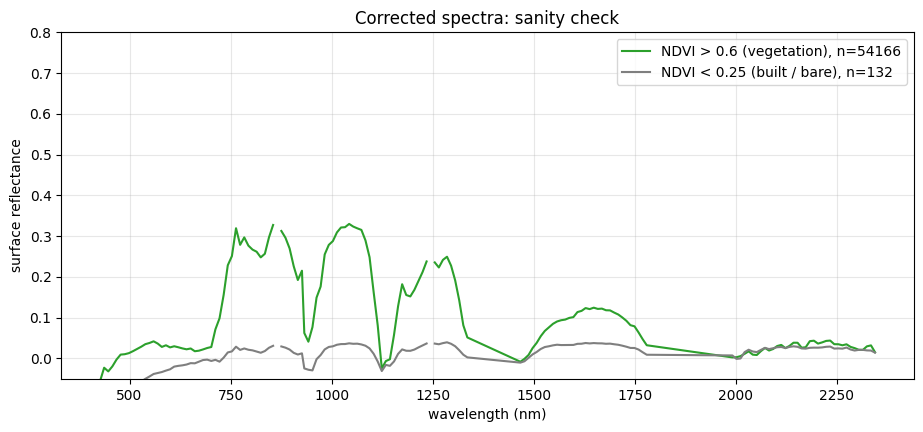

saved /content/hyp_work/EO1H1160662016170110PF_AK3_01_L1T_refl.npy (159, 259, 258)


In [ ]:
# 02-G: 6S atmospheric correction of ONE scene (clipped cell cube) -> surface reflectance
import json, re, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from Py6S import SixS, Geometry, AtmosProfile, AeroProfile, Wavelength, AtmosCorr

SIXS = "/content/sixs_env/bin/sixs"
cfgb = json.load(open(f"{ROOT}/config/hyperion_bands.json"))
keep = cfgb["keep"]; wl = {int(k): v for k, v in cfgb["wavelength_nm_approx"].items()}

atm = pd.read_csv(f"{ROOT}/pilot_atmosphere.csv")
a = atm[atm.scene_id.str.startswith(name[:22])].iloc[0]
txt = open(mtl, errors="ignore").read()
get = lambda k: re.search(rf"{k}\s*=\s*([^\n]+)", txt).group(1).strip().strip('"')
sun_el, sun_az = float(get("SUN_ELEVATION")), float(get("SUN_AZIMUTH"))
yy, mm, dd = map(int, get("ACQUISITION_DATE").split("-"))
print(f"scene {name[:22]} | sun elev {sun_el:.1f} az {sun_az:.1f} | {yy}-{mm:02d}-{dd:02d} | "
      f"AOD {a.aod550:.3f} | WV {a.water_vapour_gcm2:.2f} g/cm2 | elev {a.elev_m:.0f} m")

def coeffs(lam_nm):
    s = SixS(SIXS)
    s.geometry = Geometry.User()
    s.geometry.solar_z = 90 - sun_el; s.geometry.solar_a = sun_az
    s.geometry.view_z = 0; s.geometry.view_a = 0
    s.geometry.day, s.geometry.month = dd, mm
    s.atmos_profile = AtmosProfile.UserWaterAndOzone(float(a.water_vapour_gcm2), 0.28)
    s.aero_profile = AeroProfile.PredefinedType(AeroProfile.Continental)
    s.aot550 = float(a.aod550)
    s.altitudes.set_target_custom_altitude(max(float(a.elev_m), 0.0) / 1000.0)
    s.altitudes.set_sensor_satellite_level()
    s.wavelength = Wavelength((lam_nm - 5) / 1000.0, (lam_nm + 5) / 1000.0)
    s.atmos_corr = AtmosCorr.AtmosCorrLambertianFromRadiance(1.0)
    s.run()
    o = s.outputs
    return o.coef_xa, o.coef_xb, o.coef_xc

t0 = time.time(); coef = {}
for i, b in enumerate(keep):
    coef[b] = coeffs(wl[b])
    if (i + 1) % 40 == 0: print(f"  6S runs {i+1}/{len(keep)}, {time.time()-t0:.0f} s")

refl = np.zeros((len(keep),) + cube.shape[1:], "float32")
for i, b in enumerate(keep):
    L = cube[b - 1] / (40.0 if b <= 70 else 80.0)               # DN -> radiance
    xa, xb, xc = coef[b]
    yv = xa * L - xb
    refl[i] = yv / (1 + xc * yv)                                # surface reflectance
refl[:, ~valid] = np.nan

def near(nm): return int(np.argmin([abs(wl[b] - nm) for b in keep]))
for nm in (550, 670, 860, 1650, 2200):
    r = refl[near(nm)][valid]
    print(f"{nm:5d} nm: median {np.nanmedian(r):.3f} | <0: {np.mean(r < 0)*100:4.1f}% | >1: {np.mean(r > 1)*100:4.1f}%")

red, nir = refl[near(670)], refl[near(860)]
ndvi = (nir - red) / (nir + red)
print("NDVI percentiles 5/25/50/75/95:", np.round(np.nanpercentile(ndvi[valid], [5, 25, 50, 75, 95]), 2))

fig, ax = plt.subplots(figsize=(11, 4.5))
x = [wl[b] for b in keep]
for lab, msk, c in (("NDVI > 0.6 (vegetation)", ndvi > 0.6, "tab:green"), ("NDVI < 0.25 (built / bare)", ndvi < 0.25, "tab:gray")):
    mk = valid & msk
    if mk.sum() > 50: ax.plot(x, np.nanmean(refl[:, mk], axis=1), c=c, label=f"{lab}, n={int(mk.sum())}")
ax.set_ylim(-0.05, 0.8); ax.grid(alpha=0.3); ax.legend()
ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("surface reflectance"); ax.set_title("Corrected spectra: sanity check")
plt.show()

np.save(f"{WORK}/{name}_refl.npy", refl)
print("saved", f"{WORK}/{name}_refl.npy", refl.shape)

Cell 02-H does the whole pilot. For each scene it unpacks the scene, clips it to its cell, measures real coverage, runs the 6S correction, drops the noisy bands, computes quality flags, saves the result to Drive and deletes the unpacked files. It is resumable: scenes already saved are skipped. It takes about 15–25 minutes for the 10 scenes, because 6S takes about 80 s per scene. Run it in the session where 6S and pilot_atmosphere.csv exist.

In [ ]:
# 02-H: full pilot loop: unpack -> clip to cell -> 6S correction -> QC -> save -> clean up (resumable)
import os, glob, re, json, time, shutil, zipfile
import numpy as np, pandas as pd, rasterio
from rasterio.windows import from_bounds, Window
from rasterio.warp import transform_bounds
from Py6S import SixS, Geometry, AtmosProfile, AeroProfile, Wavelength, AtmosCorr

SIXS = "/content/sixs_env/bin/sixs"
PROC = f"{ROOT}/processed/hyperion"; os.makedirs(PROC, exist_ok=True)
HALF = 0.035
BLUE_CUT = 450                                   # nm, drop noisy blue bands
OUT_WATER = [(930, 980), (1100, 1180)]           # nm, residual water-vapour features dropped AFTER correction
MIN_COV, HIGH_AOD = 0.5, 0.8

cfgb = json.load(open(f"{ROOT}/config/hyperion_bands.json"))
keep = cfgb["keep"]; wl = {int(k): v for k, v in cfgb["wavelength_nm_approx"].items()}
out_bands = [b for b in keep if wl[b] >= BLUE_CUT and not any(a <= wl[b] <= c for a, c in OUT_WATER)]
print("bands for 6S:", len(keep), "| bands saved:", len(out_bands))

pilot = pd.read_csv(f"{ROOT}/pilot_pairs.csv")
atm   = pd.read_csv(f"{ROOT}/pilot_atmosphere.csv").set_index("scene_id")

def six_coeffs(lam, a, sun_el, sun_az, dd, mm):
    s = SixS(SIXS); s.geometry = Geometry.User()
    s.geometry.solar_z = 90 - sun_el; s.geometry.solar_a = sun_az
    s.geometry.view_z = 0; s.geometry.view_a = 0; s.geometry.day, s.geometry.month = dd, mm
    s.atmos_profile = AtmosProfile.UserWaterAndOzone(float(a.water_vapour_gcm2), 0.28)
    s.aero_profile = AeroProfile.PredefinedType(AeroProfile.Continental)
    s.aot550 = float(a.aod550)
    s.altitudes.set_target_custom_altitude(max(float(a.elev_m), 0.0) / 1000.0)
    s.altitudes.set_sensor_satellite_level()
    s.wavelength = Wavelength((lam - 5) / 1000.0, (lam + 5) / 1000.0)
    s.atmos_corr = AtmosCorr.AtmosCorrLambertianFromRadiance(1.0)
    s.run(); o = s.outputs
    return o.coef_xa, o.coef_xb, o.coef_xc

qc_path = f"{PROC}/qc_pilot.csv"
qc_rows = pd.read_csv(qc_path).to_dict("records") if os.path.exists(qc_path) else []
done = {r["scene_id"] for r in qc_rows}

for r in pilot.itertuples():
    sid = r.scene_id
    if sid in done: print("skip (done):", sid[:22]); continue
    t0 = time.time()
    zs = glob.glob(f"{RAW}/{sid}_*.ZIP")
    if not zs: print("no zip for", sid); continue
    d = f"/content/hyp_work/{sid}"
    with zipfile.ZipFile(zs[0]) as zf: zf.extractall(d)
    tifs = sorted(glob.glob(f"{d}/**/*_B[0-9][0-9][0-9]_*.TIF", recursive=True))
    mtl_f = glob.glob(f"{d}/**/*MTL*.TXT", recursive=True)[0]
    txt = open(mtl_f, errors="ignore").read()
    get = lambda k: re.search(rf"{k}\s*=\s*([^\n]+)", txt).group(1).strip().strip('"')
    sun_el, sun_az = float(get("SUN_ELEVATION")), float(get("SUN_AZIMUTH"))
    yy, mm, dd = map(int, get("ACQUISITION_DATE").split("-"))
    a = atm.loc[sid]

    with rasterio.open(tifs[0]) as s0:
        ub = transform_bounds("EPSG:4326", s0.crs, r.lon - HALF, r.lat - HALF, r.lon + HALF, r.lat + HALF)
        win = from_bounds(*ub, transform=s0.transform).round_offsets().round_lengths()
        win = win.intersection(Window(0, 0, s0.width, s0.height))
        tf, crs = s0.window_transform(win), s0.crs
    cube = np.stack([rasterio.open(t).read(1, window=win) for t in tifs]).astype("int16")
    valid = cube[49] != 0
    cov = float(valid.mean())

    coef = {b: six_coeffs(wl[b], a, sun_el, sun_az, dd, mm) for b in out_bands}
    refl = np.zeros((len(out_bands),) + cube.shape[1:], "float32")
    for i, b in enumerate(out_bands):
        L = cube[b - 1] / (40.0 if b <= 70 else 80.0)
        xa, xb, xc = coef[b]; yv = xa * L - xb
        refl[i] = yv / (1 + xc * yv)
    refl[:, ~valid] = np.nan

    nearb = lambda nm: int(np.argmin([abs(wl[b] - nm) for b in out_bands]))
    red, nir = refl[nearb(670)][valid], refl[nearb(860)][valid]
    ndvi = (nir - red) / (nir + red)
    q = {"scene_id": sid, "profile": r.profile, "product": os.path.basename(zs[0]).split("_")[-1][:-4],
         "coverage": round(cov, 3), "aod550": a.aod550, "wv": a.water_vapour_gcm2, "elev_m": a.elev_m,
         "neg_670_pct": round(float(np.mean(red < 0) * 100), 2), "neg_2200_pct": round(float(np.mean(refl[nearb(2200)][valid] < 0) * 100), 2),
         "refl_860_med": round(float(np.nanmedian(nir)), 3), "ndvi_med": round(float(np.nanmedian(ndvi)), 3),
         "flag_low_cov": cov < MIN_COV, "flag_high_aod": float(a.aod550) > HIGH_AOD,
         "flag_neg": bool(np.mean(red < 0) > 0.05), "n_px_valid": int(valid.sum())}
    np.savez_compressed(f"{PROC}/{sid}_refl.npz", refl=(refl * 10000).astype("int16") * 1,
                        valid=valid, bands=np.array(out_bands), wl_nm=np.array([wl[b] for b in out_bands]),
                        transform=np.array(tf)[:6], crs_wkt=crs.to_wkt(), scale=10000)
    qc_rows.append(q); pd.DataFrame(qc_rows).to_csv(qc_path, index=False)
    shutil.rmtree(d, ignore_errors=True)
    print(f"{sid[:22]} done in {time.time()-t0:.0f}s | cov {cov:.2f} | AOD {a.aod550:.2f} | NDVI med {q['ndvi_med']} | flags: "
          f"{[k[5:] for k in ('flag_low_cov','flag_high_aod','flag_neg') if q[k]]}")

print("\nfinished"); print(pd.DataFrame(qc_rows).drop(columns=["n_px_valid"]).to_string(index=False))

bands for 6S: 159 | bands saved: 143


/tmp/ipykernel_5171/1379139383.py:83: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f"{PROC}/{sid}_refl.npz", refl=(refl * 10000).astype("int16") * 1,


EO1H1160662016170110PF done in 112s | cov 0.83 | AOD 0.17 | NDVI med 0.904 | flags: []


/tmp/ipykernel_5171/1379139383.py:83: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f"{PROC}/{sid}_refl.npz", refl=(refl * 10000).astype("int16") * 1,


EO1H1160662014200110PF done in 97s | cov 0.68 | AOD 0.21 | NDVI med 0.754 | flags: []


/tmp/ipykernel_5171/1379139383.py:83: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f"{PROC}/{sid}_refl.npz", refl=(refl * 10000).astype("int16") * 1,


... (11 outputs left out)

/tmp/ipykernel_5171/1379139383.py:83: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f"{PROC}/{sid}_refl.npz", refl=(refl * 10000).astype("int16") * 1,


EO1H1950262015114110K4 done in 130s | cov 0.98 | AOD 0.07 | NDVI med 0.387 | flags: []


/tmp/ipykernel_5171/1379139383.py:83: RuntimeWarning: invalid value encountered in cast
  np.savez_compressed(f"{PROC}/{sid}_refl.npz", refl=(refl * 10000).astype("int16") * 1,


EO1H1190382013102110PF done in 86s | cov 0.70 | AOD 0.54 | NDVI med 0.467 | flags: []

finished
                     scene_id        profile product  coverage   aod550       wv     elev_m  neg_670_pct  neg_2200_pct  refl_860_med  ndvi_med  flag_low_cov  flag_high_aod  flag_neg
EO1H1160662016170110PF_AK3_01  humid_coastal     L1T     0.829 0.167280 2.301088 728.935313         0.52          2.95         0.320     0.904         False          False     False
EO1H1160662014200110PF_PF1_01  humid_coastal   L1Gst     0.677 0.214673 2.280664 728.935313         0.00          0.28         0.336     0.754         False          False     False
EO1H1160662015098110PF_PF2_01  humid_coastal   L1Gst     0.717 0.079048 2.739931 728.935313         0.00          0.00         0.401     0.502         False          False     False
EO1H1210652014233110KF_PF1_01  humid_coastal     L1T     0.551 0.236786 1.932187 674.901384         0.34          0.22         0.279     0.778         False          False     

In [ ]:
# Session restore: run this first in any new session (fast, no heavy work)
from google.colab import drive
drive.mount("/content/drive")

import os, glob, re, json, time
import numpy as np, pandas as pd, ee

ROOT = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
RAW  = f"{ROOT}/raw/hyperion"
PROC = f"{ROOT}/processed/hyperion"
WORK = "/content/hyp_work"; os.makedirs(WORK, exist_ok=True)

try:
    ee.Initialize(project="hyperspectral-thermal-511303")
except Exception:
    ee.Authenticate(); ee.Initialize(project="hyperspectral-thermal-511303")

try:
    import rasterio
except ImportError:
    !pip -q install rasterio
    import rasterio

print("processed scenes on Drive:", len(glob.glob(f"{PROC}/*_refl.npz")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
processed scenes on Drive: 10


In [ ]:
# 02-I: export the matching Landsat 8/9 scene (SR + LST + QA) on each Hyperion cell grid
import re
import numpy as np, pandas as pd, ee
from rasterio.crs import CRS

PROC = f"{ROOT}/processed/hyperion"
pilot = pd.read_csv(f"{ROOT}/pilot_pairs.csv")
tasks = []

for r in pilot.itertuples():
    sid = r.scene_id
    z = np.load(f"{PROC}/{sid}_refl.npz")
    h, w = z["refl"].shape[1:]
    a, b, c, d, e, f = [float(v) for v in z["transform"]]
    epsg = CRS.from_wkt(str(z["crs_wkt"])).to_epsg()
    crs = f"EPSG:{epsg}"

    lid = re.sub(r"^\d+_", "", str(r.ls_ids))              # drop the "0_"/"1_" prefix added by merge()
    coll = "LANDSAT/LC09/C02/T1_L2" if lid.startswith("LC09") else "LANDSAT/LC08/C02/T1_L2"
    img = ee.Image(f"{coll}/{lid}")
    sr  = (img.select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"]).resample("bilinear")
              .multiply(0.0000275).add(-0.2).rename(["blue", "green", "red", "nir", "swir1", "swir2"]))
    lst = img.select("ST_B10").resample("bilinear").multiply(0.00341802).add(149.0).rename("LST_K")
    qa  = img.select("QA_PIXEL").rename("QA_PIXEL")        # nearest neighbour (default)
    out = sr.addBands(lst).addBands(qa).toFloat()

    x0, y0 = c, f
    x1, y1 = c + a * w, f + e * h
    region = ee.Geometry.Rectangle([min(x0, x1), min(y0, y1), max(x0, x1), max(y0, y1)], proj=crs, geodesic=False)
    name = f"landsat_{sid[:22]}_{lid}"
    t = ee.batch.Export.image.toDrive(image=out, description=name[:100], folder="MEMBER1___PREPROCESSING",
                                      fileNamePrefix=name, region=region, crs=crs,
                                      crsTransform=[a, b, c, d, e, f], maxPixels=1e9)
    t.start(); tasks.append((name, t))
    print("started:", name, f"| {coll.split('/')[1]} | grid {w}x{h} | {crs}")

print("\n", len(tasks), "export tasks started. Check progress at https://code.earthengine.google.com/tasks")

started: landsat_EO1H1160662016170110PF_LC08_116066_20160620 | LC08 | grid 258x259 | EPSG:32750
started: landsat_EO1H1160662014200110PF_LC08_116066_20140717 | LC08 | grid 258x259 | EPSG:32750
started: landsat_EO1H1160662015098110PF_LC08_116066_20150415 | LC08 | grid 258x259 | EPSG:32750
started: landsat_EO1H1210652014233110KF_LC08_120065_20140830 | LC08 | grid 259x259 | EPSG:32749
started: landsat_EO1H1490432016293110Kl_LC08_149044_20161017 | LC08 | grid 243x263 | EPSG:32643
started: landsat_EO1H1510372015364110KF_LC08_151037_20160101 | LC08 | grid 226x264 | EPSG:32642
started: landsat_EO1H1770392013283110KF_LC08_177039_20131013 | LC08 | grid 232x263 | EPSG:32636
started: landsat_EO1H1470392014168110KF_LC08_146039_20140617 | LC08 | grid 230x263 | EPSG:32643
started: landsat_EO1H1950262015114110K4_LC08_195026_20150424 | LC08 | grid 177x262 | EPSG:32632
started: landsat_EO1H1190382013102110PF_LC08_119038_20130414 | LC08 | grid 227x263 | EPSG:32651

 10 export tasks started. Check progres

In [ ]:
# 02-J: one numbered folder per pair (1, 2, 3, ...): Hyperion GeoTIFF + Landsat + info
import os, glob, json, shutil
import numpy as np, pandas as pd, rasterio
from rasterio.transform import Affine
from rasterio.crs import CRS

PROC  = f"{ROOT}/processed/hyperion"
PAIRS = f"{ROOT}/pairs"; os.makedirs(PAIRS, exist_ok=True)
idx_path = f"{PAIRS}/pair_index.csv"
idx = pd.read_csv(idx_path) if os.path.exists(idx_path) else \
      pd.DataFrame(columns=["pair_no", "scene_id", "cell_id", "profile", "landsat_id"])

pilot = pd.read_csv(f"{ROOT}/pilot_pairs.csv")
qc    = pd.read_csv(f"{PROC}/qc_pilot.csv").set_index("scene_id")
atm   = pd.read_csv(f"{ROOT}/pilot_atmosphere.csv").set_index("scene_id")

for r in pilot.itertuples():
    sid = r.scene_id
    lid = re.sub(r"^\d+_", "", str(r.ls_ids)) if "re" in globals() else str(r.ls_ids).split("_", 1)[-1]
    hit = idx[(idx.scene_id == sid) & (idx.cell_id == r.cell_id)]
    if len(hit):
        no = int(hit.iloc[0].pair_no)
    else:
        no = int(idx.pair_no.max()) + 1 if len(idx) else 1
        idx.loc[len(idx)] = [no, sid, r.cell_id, r.profile, lid]
    folder = f"{PAIRS}/{no}"; os.makedirs(folder, exist_ok=True)

    # --- Hyperion processed cube -> GeoTIFF ---
    hy = f"{folder}/hyperion_reflectance.tif"
    if not os.path.exists(hy):
        z = np.load(f"{PROC}/{sid}_refl.npz")
        refl, bands, wlnm = z["refl"], z["bands"], z["wl_nm"]
        tf = Affine(*[float(v) for v in z["transform"]])
        crs = CRS.from_wkt(str(z["crs_wkt"]))
        with rasterio.open(hy, "w", driver="GTiff", height=refl.shape[1], width=refl.shape[2],
                           count=refl.shape[0], dtype="int16", crs=crs, transform=tf,
                           nodata=-32768, compress="deflate") as dst:
            dst.write(refl)
            for i, (b, w) in enumerate(zip(bands, wlnm), start=1):
                dst.set_band_description(i, f"{w:.0f} nm (B{int(b):03d})")
            dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000",
                            source=sid, correction="6S per scene (uniform atmosphere)")

    # --- Landsat export (moved from the project root) ---
    ls_dest = f"{folder}/landsat_{lid}.tif"
    found = glob.glob(f"{ROOT}/landsat_{sid[:22]}_*.tif")
    if found and not os.path.exists(ls_dest):
        shutil.move(found[0], ls_dest)
    has_ls = os.path.exists(ls_dest)

    # --- pair_info.json ---
    info = {"pair_no": no, "hyperion_scene": sid, "hyperion_date": str(r.acq_datetime),
            "landsat_scene": lid, "landsat_minus_hyperion_days": float(r.ls_dt),
            "cell_id": r.cell_id, "cell_lon": float(r.lon), "cell_lat": float(r.lat), "profile": r.profile,
            "atmosphere": atm.loc[sid].to_dict(), "qc": qc.loc[sid].to_dict(),
            "landsat_file_present": bool(has_ls)}
    json.dump(info, open(f"{folder}/pair_info.json", "w"), indent=1, default=str)
    print(f"pair {no:>3}: {sid[:22]} | hyperion tif OK | landsat {'OK' if has_ls else 'MISSING (re-run after the GEE exports finish)'}")

idx.to_csv(idx_path, index=False)
print("\nsaved", idx_path)

pair   1: EO1H1160662016170110PF | hyperion tif OK | landsat OK
pair   2: EO1H1160662014200110PF | hyperion tif OK | landsat OK
pair   3: EO1H1160662015098110PF | hyperion tif OK | landsat OK
pair   4: EO1H1210652014233110KF | hyperion tif OK | landsat OK
pair   5: EO1H1490432016293110Kl | hyperion tif OK | landsat OK
pair   6: EO1H1510372015364110KF | hyperion tif OK | landsat OK
pair   7: EO1H1770392013283110KF | hyperion tif OK | landsat OK
pair   8: EO1H1470392014168110KF | hyperion tif OK | landsat OK
pair   9: EO1H1950262015114110K4 | hyperion tif OK | landsat OK
pair  10: EO1H1190382013102110PF | hyperion tif OK | landsat OK

saved /content/drive/MyDrive/MEMBER1___PREPROCESSING/pairs/pair_index.csv


The Landsat files are all in the right folders. The only problem is that GEE exported each one 1–2 pixels larger than the Hyperion grid. For example, pair 1 is 260 × 259 against 259 × 258, and pair 4 is 261 × 261 against 259 × 259. This usually happens because the export region ends exactly on a pixel edge, so GEE rounds up. It is not a data problem.

The fix is to snap each Landsat file to the exact Hyperion grid by cropping the extra rows and columns. The cell first checks that the two grids are really aligned. The Landsat origin must sit a whole number of pixels from the Hyperion origin, with the same pixel size. If any pair isn’t aligned, the cell reports it and leaves that file alone. The result is the deliverable you want in each folder: Hyperion and Landsat on an identical grid.

In [ ]:
# 02-K0: snap each Landsat file to the exact Hyperion grid (crop the extra pixel rows/cols)
import os, glob, numpy as np, pandas as pd, rasterio
from rasterio.windows import Window

PAIRS = f"{ROOT}/pairs"
idx = pd.read_csv(f"{PAIRS}/pair_index.csv")

for p in idx.itertuples():
    folder = f"{PAIRS}/{int(p.pair_no)}"
    lf = glob.glob(f"{folder}/landsat_*.tif")
    if not lf: print(f"pair {int(p.pair_no):>2}: no landsat file"); continue
    lf = lf[0]
    with rasterio.open(f"{folder}/hyperion_reflectance.tif") as hs, rasterio.open(lf) as ls:
        ht, lt = hs.transform, ls.transform
        col = (ht.c - lt.c) / lt.a
        row = (ht.f - lt.f) / lt.e
        size_ok = abs(ht.a - lt.a) < 1e-3 and abs(ht.e - lt.e) < 1e-3
        frac_ok = abs(col - round(col)) < 0.1 and abs(row - round(row)) < 0.1
        if not (size_ok and frac_ok and hs.crs == ls.crs):
            print(f"pair {int(p.pair_no):>2}: NOT aligned (offset col {col:.2f}, row {row:.2f}, size_ok {size_ok}, same crs {hs.crs == ls.crs}) -> left unchanged")
            continue
        if ls.shape == hs.shape and abs(col) < 0.1 and abs(row) < 0.1:
            print(f"pair {int(p.pair_no):>2}: already on the Hyperion grid"); continue
        win = Window(int(round(col)), int(round(row)), hs.width, hs.height)
        data = ls.read(window=win, boundless=True, fill_value=np.nan)
        prof = ls.profile.copy()
        prof.update(height=hs.height, width=hs.width, transform=ht, nodata=None)
        descs = ls.descriptions
        old_shape = ls.shape
    tmp = lf + ".tmp"
    with rasterio.open(tmp, "w", **prof) as dst:
        dst.write(data)
        for i, d in enumerate(descs, start=1):
            if d: dst.set_band_description(i, d)
    os.replace(tmp, lf)
    print(f"pair {int(p.pair_no):>2}: {old_shape} -> {data.shape[1:]} | offset (col {col:.2f}, row {row:.2f})")

pair  1: (260, 259) -> (259, 258) | offset (col 0.00, row -0.00)
pair  2: (259, 259) -> (259, 258) | offset (col 0.00, row -0.00)
pair  3: (259, 259) -> (259, 258) | offset (col 0.00, row -0.00)
pair  4: (261, 261) -> (259, 259) | offset (col 1.00, row 1.00)
pair  5: (264, 244) -> (263, 243) | offset (col 1.00, row -0.00)
pair  6: (265, 227) -> (264, 226) | offset (col 0.00, row -0.00)
pair  7: (264, 233) -> (263, 232) | offset (col 1.00, row -0.00)
pair  8: (264, 231) -> (263, 230) | offset (col 0.00, row -0.00)
pair  9: (263, 178) -> (262, 177) | offset (col 0.00, row -0.00)
pair 10: (264, 228) -> (263, 227) | offset (col 1.00, row -0.00)


In [ ]:
# 02-K: co-registration + spectral agreement check for every pair folder
import os, glob, re, numpy as np, pandas as pd, rasterio

PAIRS = f"{ROOT}/pairs"
idx = pd.read_csv(f"{PAIRS}/pair_index.csv")
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}   # Landsat 8 OLI band windows (nm)
LB = list(WIN)

def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() < 200: return np.nan
    return float(np.corrcoef(a[m], b[m])[0, 1])

def sh(A, dy, dx):
    return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]

rows = []
for p in idx.itertuples():
    folder = f"{PAIRS}/{int(p.pair_no)}"
    lf = glob.glob(f"{folder}/landsat_*.tif")
    if not lf: rows.append({"pair": int(p.pair_no), "status": "no landsat file"}); continue
    with rasterio.open(f"{folder}/hyperion_reflectance.tif") as hs, rasterio.open(lf[0]) as ls:
        same = hs.shape == ls.shape and np.allclose(tuple(hs.transform)[:6], tuple(ls.transform)[:6], atol=1e-3)
        if not same:
            rows.append({"pair": int(p.pair_no), "status": f"grid mismatch {hs.shape} vs {ls.shape}"}); continue
        Hraw = hs.read().astype("float32"); Hraw[Hraw == -32768] = np.nan
        H = Hraw / 10000.0
        wlh = np.array([float(re.search(r"(\d+) nm", d).group(1)) for d in hs.descriptions])
        L = ls.read().astype("float32")
    SR, LST, QA = L[:6], L[6], L[7].astype("int64")
    clear = ((QA & 0b11110) == 0) & np.isfinite(SR[3]) & (QA != 0)
    hv = np.isfinite(H[0])
    usable = hv & clear

    sim = {}
    for k, (a, b) in WIN.items():
        sel = (wlh >= a) & (wlh <= b)
        sim[k] = np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
    row = {"pair": int(p.pair_no), "status": "ok", "n_px_usable": int(usable.sum()),
           "landsat_clear_pct": round(float(clear[hv].mean() * 100), 1) if hv.any() else np.nan,
           "LST_med_K": round(float(np.nanmedian(LST[usable])), 1) if usable.any() else np.nan}
    for i, k in enumerate(LB):
        a, b = sim[k][usable], SR[i][usable]
        row[f"bias_{k}"] = round(float(np.nanmean(a - b)), 3) if usable.any() else np.nan
        row[f"r_{k}"] = round(pearson(a, b), 2)

    ndvi_h = (sim["nir"] - sim["red"]) / (sim["nir"] + sim["red"])
    ndvi_l = (SR[3] - SR[2]) / (SR[3] + SR[2])
    ndvi_h = np.where(usable, ndvi_h, np.nan); ndvi_l = np.where(usable, ndvi_l, np.nan)
    best, r00 = (np.nan, (0, 0)), pearson(ndvi_h, ndvi_l)
    for dy in range(-3, 4):
        for dx in range(-3, 4):
            r = pearson(sh(ndvi_h, dy, dx), sh(ndvi_l, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    row.update({"ndvi_r_at_0": round(r00, 3), "ndvi_r_best": round(best[0], 3), "best_shift_yx_px": best[1]})
    flags = []
    if best[1] != (0, 0): flags.append("shift")
    if not np.isfinite(r00) or r00 < 0.7: flags.append("low_corr")
    if usable.sum() < 5000: flags.append("few_px")
    row["flags"] = ",".join(flags)
    rows.append(row)

res = pd.DataFrame(rows)
res.to_csv(f"{PAIRS}/coreg_qc.csv", index=False)
pd.set_option("display.width", 250)
print(res[["pair", "status", "n_px_usable", "landsat_clear_pct", "LST_med_K", "ndvi_r_at_0", "ndvi_r_best",
           "best_shift_yx_px", "flags"]].to_string(index=False))
print("\nreflectance bias (Hyperion minus Landsat) and correlation by band:")
print(res[["pair"] + [f"bias_{k}" for k in LB] + [f"r_{k}" for k in LB]].to_string(index=False))

/tmp/ipykernel_563/3434249948.py:48: RuntimeWarning: invalid value encountered in divide
  ndvi_h = (sim["nir"] - sim["red"]) / (sim["nir"] + sim["red"])
/tmp/ipykernel_563/3434249948.py:31: RuntimeWarning: invalid value encountered in cast
  SR, LST, QA = L[:6], L[6], L[7].astype("int64")


 pair status  n_px_usable  landsat_clear_pct  LST_med_K  ndvi_r_at_0  ndvi_r_best best_shift_yx_px          flags
    1     ok        65335               97.8      298.6        0.003        0.007          (-2, 1) shift,low_corr
    2     ok        66810              100.0      302.8        0.062        0.160         (-3, -3) shift,low_corr
    3     ok        66513               99.5      305.4       -0.054        0.059         (-3, -3) shift,low_corr
    4     ok        54376               81.1      300.4        0.630        0.648          (0, -1) shift,low_corr
    5     ok        63909              100.0      312.7        0.951        0.951           (0, 0)               
    6     ok        53816               90.2      292.8        0.565        0.565           (0, 0)       low_corr
    7     ok        61016              100.0      307.5        0.772        0.936          (0, -1)          shift
    8     ok        60016               99.2      310.6        0.345        0.394       

The pipeline works end to end, but the check found three things that need attention before you scale to 120 pairs. This is what the pilot is for.

1. Registration: a one-pixel shift in three clear cases. For pairs 7, 9 and 10 the NDVI correlation jumps when Hyperion is shifted by one pixel in x, from 0.77 to 0.94, 0.86 to 0.97 and 0.88 to 0.93. That is about 30 m, consistent in direction, and within EO-1’s stated geolocation accuracy. Pair 5 is already aligned (r = 0.95), and pair 6 (r = 0.57) also best-fits at no shift. The shifts reported for pairs 1–3 (up to 3 pixels) are not meaningful, because those correlations are near zero.

2. The three Bali pairs (1–3) can’t be judged by NDVI correlation. Their correlation is about zero because the cell is almost all dense vegetation. NDVI saturates near 0.9 everywhere, so there is little spatial contrast to correlate. That explanation fits, but I haven’t verified it. The new cell prints the NDVI spread of each image to test it.

3. A systematic bias that I don’t accept yet. In every pair, Hyperion near-infrared reflectance is lower than Landsat’s by 0.09–0.19, and SWIR1 and SWIR2 are lower by about 0.01–0.12 and 0.01–0.10. The visible bands are mostly within ±0.07. A consistent sign in all 10 scenes isn’t seasonal change or noise. The cause could be Hyperion’s radiometric calibration, my 6S settings (uniform atmosphere, approximate wavelengths, aerosol type), or both. I haven’t established which, and I won’t scale up until we know the size and the pattern.

The two warnings in the output (invalid value in divide and in cast) come from empty pixels and are harmless.

The next cell, 02-L, is a diagnostic. For each pair, after applying the shift where it is clearly supported, it fits Hyperion against Landsat band by band. A uniform ratio (slope ≈ 0.7 in all bands, offset ≈ 0) would point to a gain or calibration problem. A constant offset would point to the atmospheric path correction. It also prints the NDVI spread for the Bali test, and plots NIR scatter for three pairs.

/tmp/ipykernel_563/2793859848.py:47: RuntimeWarning: invalid value encountered in divide
  nh = (sim["nir"] - sim["red"]) / (sim["nir"] + sim["red"]); nl = (SR[3] - SR[2]) / (SR[3] + SR[2])


pair  1: NDVI std Hyperion 0.916 | Landsat 0.086 | median L 0.84
pair  2: NDVI std Hyperion 0.229 | Landsat 0.104 | median L 0.85
pair  3: NDVI std Hyperion 0.133 | Landsat 0.092 | median L 0.88
pair  4: NDVI std Hyperion 0.166 | Landsat 0.096 | median L 0.75
pair  5: NDVI std Hyperion 0.234 | Landsat 0.180 | median L 0.51
pair  6: NDVI std Hyperion 0.291 | Landsat 0.147 | median L 0.23
pair  7: NDVI std Hyperion 0.177 | Landsat 0.160 | median L 0.45
pair  8: NDVI std Hyperion 0.363 | Landsat 0.139 | median L 0.29
pair  9: NDVI std Hyperion 0.237 | Landsat 0.204 | median L 0.41
pair 10: NDVI std Hyperion 0.194 | Landsat 0.153 | median L 0.45

median ratio Hyperion/Landsat by band:
band  blue  green   red   nir  swir1  swir2
pair                                       
1     0.12   0.71  0.58  0.56   0.66   0.41
2     0.87   1.07  1.06  0.54   0.78   0.71
3     5.85   2.99  4.42  0.68   1.19   1.78
4     0.50   0.76  0.71  0.50   0.63   0.53
5     0.44   0.89  0.78  0.57   0.71   0.61
6 

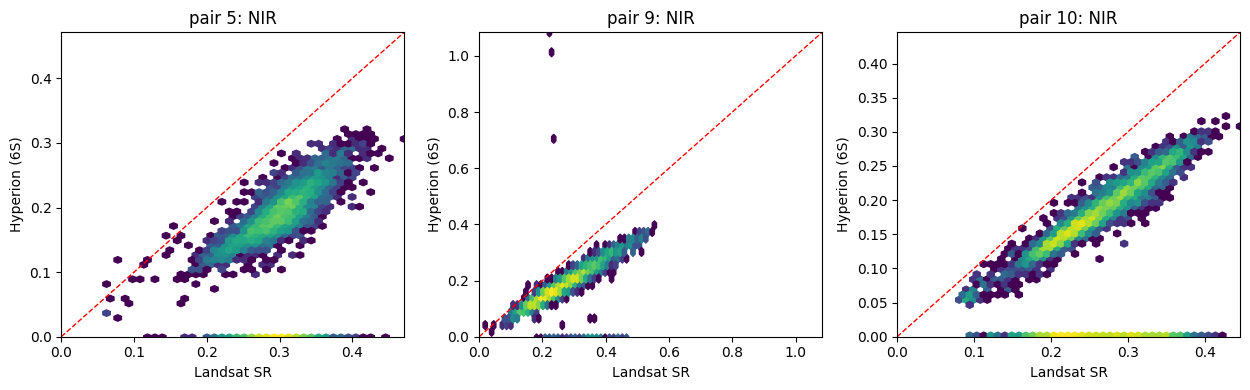

In [ ]:
# 02-L: diagnose the Hyperion-vs-Landsat bias (gain or offset?) after the registration shift
import ast, glob, re, numpy as np, pandas as pd, rasterio
import matplotlib.pyplot as plt

PAIRS = f"{ROOT}/pairs"
qc = pd.read_csv(f"{PAIRS}/coreg_qc.csv")
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
LB = list(WIN)
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]

rows, keep_scatter = [], {}
for r in qc.itertuples():
    if r.status != "ok": continue
    folder = f"{PAIRS}/{int(r.pair)}"
    with rasterio.open(f"{folder}/hyperion_reflectance.tif") as hs:
        Hr = hs.read().astype("float32"); Hr[Hr == -32768] = np.nan; H = Hr / 10000.0
        wlh = np.array([float(re.search(r"(\d+) nm", d).group(1)) for d in hs.descriptions])
    with rasterio.open(glob.glob(f"{folder}/landsat_*.tif")[0]) as ls:
        L = ls.read().astype("float32")
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & np.isfinite(SR[3]) & (QA != 0)

    dy, dx = ast.literal_eval(str(r.best_shift_yx_px))
    use_shift = (r.ndvi_r_best > 0.6) and (r.ndvi_r_best - r.ndvi_r_at_0 > 0.03)
    if not use_shift: dy, dx = 0, 0

    sim = {}
    for k, (a, b) in WIN.items():
        sel = (wlh >= a) & (wlh <= b)
        sim[k] = np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
    cl = sh(clear, -dy, -dx)
    for i, k in enumerate(LB):
        a_, b_ = sh(sim[k], dy, dx), sh(SR[i], -dy, -dx)
        m = np.isfinite(a_) & np.isfinite(b_) & cl
        if m.sum() < 2000: continue
        slope, icpt = np.polyfit(b_[m], a_[m], 1)
        rows.append({"pair": int(r.pair), "band": k, "shift": (dy, dx), "n": int(m.sum()),
                     "hyp_med": round(float(np.median(a_[m])), 3), "lan_med": round(float(np.median(b_[m])), 3),
                     "ratio": round(float(np.median(a_[m]) / np.median(b_[m])), 2),
                     "slope": round(float(slope), 2), "intercept": round(float(icpt), 3),
                     "corr": round(float(np.corrcoef(a_[m], b_[m])[0, 1]), 2)})
        if k == "nir" and int(r.pair) in (5, 9, 10):
            ii = np.random.default_rng(0).choice(m.sum(), min(6000, m.sum()), replace=False)
            keep_scatter[int(r.pair)] = (b_[m][ii], a_[m][ii])
    # NDVI spread (tests the 'no contrast' explanation for the dense-vegetation Bali cell)
    nh = (sim["nir"] - sim["red"]) / (sim["nir"] + sim["red"]); nl = (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = np.isfinite(nh) & np.isfinite(nl) & clear
    print(f"pair {int(r.pair):>2}: NDVI std Hyperion {np.nanstd(nh[u]):.3f} | Landsat {np.nanstd(nl[u]):.3f} | median L {np.nanmedian(nl[u]):.2f}")

d = pd.DataFrame(rows)
pd.set_option("display.width", 250)
print("\nmedian ratio Hyperion/Landsat by band:");  print(d.pivot(index="pair", columns="band", values="ratio")[LB].to_string())
print("\nslope of Hyperion on Landsat:");           print(d.pivot(index="pair", columns="band", values="slope")[LB].to_string())
print("\nintercept:");                              print(d.pivot(index="pair", columns="band", values="intercept")[LB].to_string())

fig, axs = plt.subplots(1, len(keep_scatter), figsize=(4.2 * len(keep_scatter), 4), squeeze=False)
for ax, (pno, (x, y)) in zip(axs[0], sorted(keep_scatter.items())):
    ax.hexbin(x, y, gridsize=40, bins="log", cmap="viridis")
    lim = [0, max(x.max(), y.max())]; ax.plot(lim, lim, "r--", lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_title(f"pair {pno}: NIR"); ax.set_xlabel("Landsat SR"); ax.set_ylabel("Hyperion (6S)")
plt.tight_layout(); plt.show()

What I’m not changing yet. I won’t apply a bias fix or the pixel shift until the bad pixels are removed, because the bias estimate is contaminated for half the pairs. The next cell, 02-M, does this:

Flags the bad pixels and counts their share per pair.
Checks for bad columns (Hyperion has stripes from bad detector columns).
Re-estimates the bias robustly, using binned medians that outliers can’t skew.
Prints the sun elevation of each scene, read directly from the raw ZIP without unpacking it.
Prints which Hyperion bands fall in each Landsat window, so I can check the NIR window.

In [ ]:
# 02-M: clean-pixel diagnosis (bad pixels, stripes, robust bias, sun elevation)
import ast, glob, json, re, zipfile, numpy as np, pandas as pd, rasterio

PAIRS = f"{ROOT}/pairs"
qc = pd.read_csv(f"{PAIRS}/coreg_qc.csv")
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
LB = list(WIN)
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]

diag, robust, first = [], [], True
for r in qc.itertuples():
    if r.status != "ok": continue
    pno = int(r.pair); folder = f"{PAIRS}/{pno}"
    info = json.load(open(f"{folder}/pair_info.json")); sid = info["hyperion_scene"]
    with rasterio.open(f"{folder}/hyperion_reflectance.tif") as hs:
        Hr = hs.read().astype("float32"); Hr[Hr == -32768] = np.nan; H = Hr / 10000.0
        wlh = np.array([float(re.search(r"(\d+) nm", d).group(1)) for d in hs.descriptions])
    with rasterio.open(glob.glob(f"{folder}/landsat_*.tif")[0]) as ls:
        L = ls.read().astype("float32")
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & np.isfinite(SR[3]) & (QA != 0)

    with zipfile.ZipFile(glob.glob(f"{RAW}/{sid}_*.ZIP")[0]) as zf:
        mtl = [n for n in zf.namelist() if "MTL" in n.upper()][0]
        sun = float(re.search(r"SUN_ELEVATION\s*=\s*([\d.\-]+)", zf.read(mtl).decode(errors="ignore")).group(1))

    sim = {}
    for k, (a, b) in WIN.items():
        sel = (wlh >= a) & (wlh <= b)
        sim[k] = np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
        if first: print(f"window {k:6s}: {int(sel.sum())} Hyperion bands, {wlh[sel].min():.0f}-{wlh[sel].max():.0f} nm")
    first = False
    S = np.stack([sim[k] for k in LB])
    hv = np.isfinite(S[0]); usable = hv & clear
    bad = np.any((S <= 0) | (S >= 1.0), axis=0)
    nirbad = (sim["nir"] <= 0) & usable
    colfrac = nirbad.sum(0) / np.maximum(usable.sum(0), 1)
    diag.append({"pair": pno, "sun_elev": sun, "aod": round(info["atmosphere"]["aod550"], 2),
                 "wv": round(info["atmosphere"]["water_vapour_gcm2"], 2), "elev_m": round(info["atmosphere"]["elev_m"]),
                 "pct_bad_px": round(float((usable & bad).sum() / max(usable.sum(), 1) * 100), 1),
                 "bad_cols(>50% NIR<=0)": int((colfrac > 0.5).sum())})

    dy, dx = ast.literal_eval(str(r.best_shift_yx_px))
    if not ((r.ndvi_r_best > 0.6) and (r.ndvi_r_best - r.ndvi_r_at_0 > 0.03)): dy, dx = 0, 0
    cl, bd = sh(clear, -dy, -dx), sh(bad, dy, dx)
    for k in ("red", "nir", "swir1"):
        a_, b_ = sh(sim[k], dy, dx), sh(SR[LB.index(k)], -dy, -dx)
        m = np.isfinite(a_) & np.isfinite(b_) & cl & ~bd
        if m.sum() < 2000: continue
        edges = np.percentile(b_[m], np.linspace(2, 98, 13)); bi = np.digitize(b_[m], edges)
        xm = np.array([np.median(b_[m][bi == i]) for i in range(1, 13) if (bi == i).sum() > 50])
        ym = np.array([np.median(a_[m][bi == i]) for i in range(1, 13) if (bi == i).sum() > 50])
        s, c = np.polyfit(xm, ym, 1)
        robust.append({"pair": pno, "band": k, "n_clean": int(m.sum()),
                       "ratio": round(float(np.median(a_[m]) / np.median(b_[m])), 2),
                       "slope": round(float(s), 2), "intercept": round(float(c), 3)})

pd.set_option("display.width", 250)
print("\nscene conditions and bad-pixel share:"); print(pd.DataFrame(diag).to_string(index=False))
rb = pd.DataFrame(robust)
for col in ("ratio", "slope", "intercept"):
    print(f"\nrobust {col} (clean pixels, binned medians):")
    print(rb.pivot(index="pair", columns="band", values=col)[["red", "nir", "swir1"]].to_string())

window blue  : 6 Hyperion bands, 458-509 nm
window green : 6 Hyperion bands, 539-590 nm
window red   : 4 Hyperion bands, 641-672 nm
window nir   : 3 Hyperion bands, 855-876 nm
window swir1 : 9 Hyperion bands, 1568-1649 nm
window swir2 : 18 Hyperion bands, 2113-2285 nm

scene conditions and bad-pixel share:
 pair  sun_elev  aod   wv  elev_m  pct_bad_px  bad_cols(>50% NIR<=0)
    1 24.265231 0.17 2.30     729        33.5                     44
    2 37.720289 0.21 2.28     729        32.3                     83
    3 38.844847 0.08 2.74     729        28.0                     72
    4 44.274462 0.24 1.93     675        35.9                    121
    5 30.027827 0.37 2.27      88        29.7                     71
    6 17.386382 0.22 0.81     207        55.5                    120
    7 45.565281 0.17 1.64      18        34.4                     79
    8 59.453927 1.23 3.78     275        14.2                     25
    9 42.217311 0.07 0.89     146         2.2                      0
  

Cell 02-N makes three tests:

Atmosphere sensitivity. Using 6S alone, no scene data. It takes a surface of reflectance 0.45 at 865 nm, computes the radiance the sensor would see, then inverts that radiance under other atmospheres (AOD, water vapour, aerosol type, elevation). If the retrieved value stays near 0.45, no plausible atmosphere setting can explain a drop to about 0.30, and the atmosphere is cleared.
Pictures for pairs 1, 5, 9. Hyperion NIR, Landsat NIR, and a map of where Hyperion NIR is ≤ 0, so we can see stripes versus swath edges.
Spectrum of pair 9. The Hyperion spectrum with the six Landsat band values overlaid, showing at which wavelengths the deficit begins.

In [ ]:
# Session restore for the 6S-based cells (safe to run any time)
from google.colab import drive
drive.mount("/content/drive")

import os, glob
ROOT = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
RAW  = f"{ROOT}/raw/hyperion"
PAIRS = f"{ROOT}/pairs"

try:
    import rasterio
except ImportError:
    !pip -q install rasterio
    import rasterio

try:
    import Py6S
except ImportError:
    !pip -q install Py6S

if not os.path.exists("/content/sixs_env/bin/sixs"):
    print("6S binary missing -> reinstalling")
    !curl -sSL https://micro.mamba.pm/api/micromamba/linux-64/latest -o /content/mm.tar.bz2
    !tar -xjf /content/mm.tar.bz2 -C /content bin/micromamba
    !/content/bin/micromamba create -y -q -p /content/sixs_env -c conda-forge sixs
print("6S binary:", glob.glob("/content/sixs_env/bin/sixs*"))
print("pair folders on Drive:", len(glob.glob(f"{PAIRS}/*/")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 749.3 kB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.2 MB/s eta 0:00:00
6S binary missing -> reinstalling
6S binary: ['/content/sixs_env/bin/sixs']
pair folders on Drive: 10


at-sensor radiance for a true reflectance of 0.45 (865 nm): 89.17

retrieved reflectance (true = 0.45) when the atmosphere assumed in the inversion is wrong:
  aod=0.05           0.448
  aod=0.2            0.464
  aod=0.5            0.501
  aod=1.0            0.573
  wv=0.5             0.45
  wv=1.0             0.45
  wv=2.3             0.45
  wv=4.0             0.45
  wv=6.0             0.45
  elev_km=0.0        0.45
  elev_km=0.7        0.45
  elev_km=1.5        0.45
  aerosol=Maritime   0.444
  aerosol=Urban      0.459
  aerosol=Desert     0.443


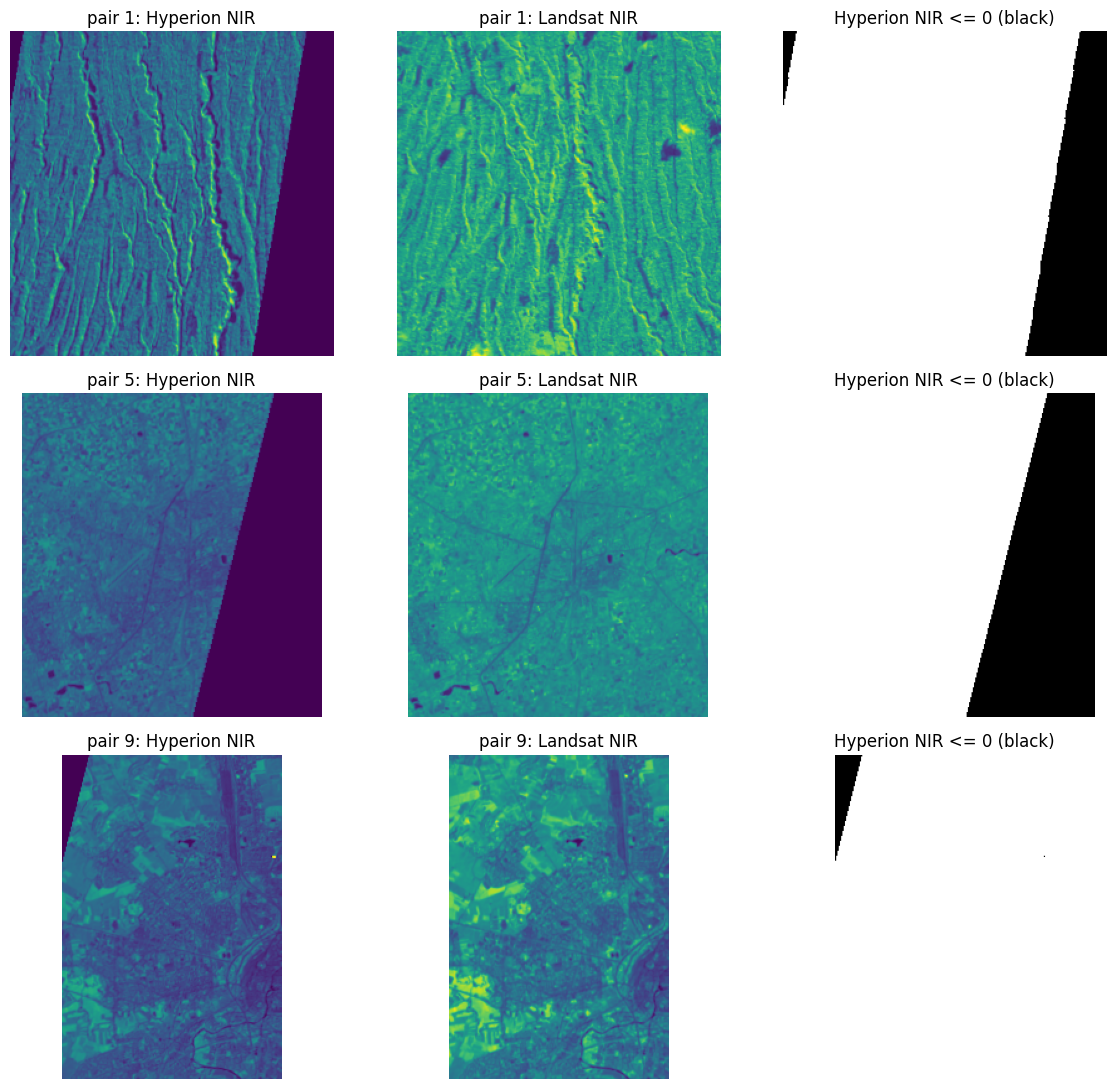

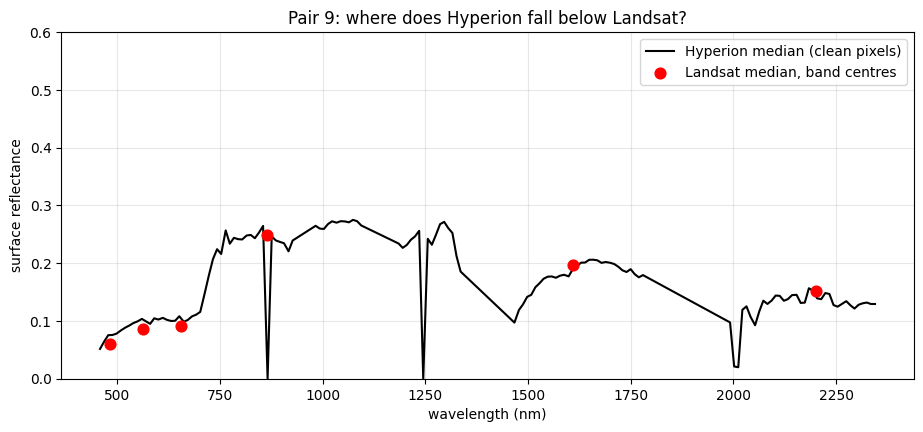

In [ ]:
# 02-N: (A) atmosphere sensitivity, (B) maps of pairs 1/5/9, (C) pair 9 spectrum vs Landsat
import glob, re, numpy as np, pandas as pd, rasterio, matplotlib.pyplot as plt
from Py6S import SixS, Geometry, AtmosProfile, AeroProfile, Wavelength, AtmosCorr, GroundReflectance

SIXS = "/content/sixs_env/bin/sixs"; PAIRS = f"{ROOT}/pairs"
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}

def run6s(sun_el, wv, aod, aero, elev_km, lam=865, rho=None, rad=None):
    s = SixS(SIXS); s.geometry = Geometry.User()
    s.geometry.solar_z = 90 - sun_el; s.geometry.solar_a = 100
    s.geometry.view_z = 0; s.geometry.view_a = 0; s.geometry.day, s.geometry.month = 15, 6
    s.atmos_profile = AtmosProfile.UserWaterAndOzone(wv, 0.28)
    s.aero_profile = AeroProfile.PredefinedType(aero); s.aot550 = aod
    s.altitudes.set_target_custom_altitude(elev_km); s.altitudes.set_sensor_satellite_level()
    s.wavelength = Wavelength((lam - 5) / 1000.0, (lam + 5) / 1000.0)
    if rho is not None:
        s.ground_reflectance = GroundReflectance.HomogeneousLambertian(rho); s.run()
        return s.outputs.apparent_radiance
    s.atmos_corr = AtmosCorr.AtmosCorrLambertianFromRadiance(rad); s.run()
    return s.outputs.atmos_corrected_reflectance_lambertian

# ---- (A) what reflectance does a TRUE 0.45 surface come back as under other settings? ----
base = dict(sun_el=42.2, wv=0.89, aod=0.07, aero=AeroProfile.Continental, elev_km=0.146)
Lrad = run6s(**base, rho=0.45)
print(f"at-sensor radiance for a true reflectance of 0.45 (865 nm): {Lrad:.2f}")
rows = []
for k, vals in (("aod", (0.05, 0.2, 0.5, 1.0)), ("wv", (0.5, 1.0, 2.3, 4.0, 6.0)), ("elev_km", (0.0, 0.7, 1.5))):
    for v in vals:
        rows.append((f"{k}={v}", round(run6s(**{**base, k: v}, rad=Lrad), 3)))
for name, a in (("Maritime", AeroProfile.Maritime), ("Urban", AeroProfile.Urban), ("Desert", AeroProfile.Desert)):
    rows.append((f"aerosol={name}", round(run6s(**{**base, "aero": a}, rad=Lrad), 3)))
print("\nretrieved reflectance (true = 0.45) when the atmosphere assumed in the inversion is wrong:")
for n, v in rows: print(f"  {n:18s} {v}")

# ---- loaders ----
def load(pno):
    folder = f"{PAIRS}/{pno}"
    with rasterio.open(f"{folder}/hyperion_reflectance.tif") as hs:
        Hr = hs.read().astype("float32"); Hr[Hr == -32768] = np.nan
        wlh = np.array([float(re.search(r"(\d+) nm", d).group(1)) for d in hs.descriptions])
    with rasterio.open(glob.glob(f"{folder}/landsat_*.tif")[0]) as ls: L = ls.read().astype("float32")
    return Hr / 10000.0, wlh, L

def simband(H, wlh, k):
    sel = (wlh >= WIN[k][0]) & (wlh <= WIN[k][1]); return np.nanmean(H[sel], axis=0)

# ---- (B) maps ----
fig, axs = plt.subplots(3, 3, figsize=(12, 11))
for row, pno in zip(axs, (1, 5, 9)):
    H, wlh, L = load(pno); nir = simband(H, wlh, "nir")
    row[0].imshow(nir, vmin=0, vmax=0.6, cmap="viridis"); row[0].set_title(f"pair {pno}: Hyperion NIR")
    row[1].imshow(L[3], vmin=0, vmax=0.6, cmap="viridis"); row[1].set_title(f"pair {pno}: Landsat NIR")
    row[2].imshow(np.where(np.isfinite(nir), (nir <= 0).astype(float), np.nan), cmap="gray_r"); row[2].set_title("Hyperion NIR <= 0 (black)")
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()

# ---- (C) pair 9 spectrum vs Landsat ----
H, wlh, L = load(9)
S = np.stack([simband(H, wlh, k) for k in WIN]); clean = np.all((S > 0) & (S < 1), axis=0)
clear = ((np.nan_to_num(L[7]).astype("int64") & 30) == 0) & np.isfinite(L[3])
m = clean & clear
spec = np.nanmedian(H[:, m], axis=1)
fig, ax = plt.subplots(figsize=(11, 4.5)); ax.plot(wlh, spec, "k", label="Hyperion median (clean pixels)")
ax.scatter([(a + b) / 2 for a, b in WIN.values()], [np.median(L[i][m]) for i in range(6)], c="r", s=60, zorder=5, label="Landsat median, band centres")
ax.set_ylim(0, 0.6); ax.grid(alpha=0.3); ax.legend(); ax.set_xlabel("wavelength (nm)"); ax.set_ylabel("surface reflectance")
ax.set_title("Pair 9: where does Hyperion fall below Landsat?"); plt.show()

In [ ]:
# 02-O: find systematic bad bands, better pixel mask, recompute bias (diagnostic only; no files changed)
import ast, glob, re, numpy as np, pandas as pd, rasterio

PAIRS = f"{ROOT}/pairs"
qc = pd.read_csv(f"{PAIRS}/coreg_qc.csv"); qc = qc[qc.status == "ok"]
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
LB = list(WIN)
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]

def load(pno):
    folder = f"{PAIRS}/{pno}"
    with rasterio.open(f"{folder}/hyperion_reflectance.tif") as hs:
        Hr = hs.read().astype("float32"); Hr[Hr == -32768] = np.nan
        wlh = np.array([float(re.search(r"(\d+) nm", d).group(1)) for d in hs.descriptions])
        bn = np.array([int(re.search(r"\(B(\d+)\)", d).group(1)) for d in hs.descriptions])
    with rasterio.open(glob.glob(f"{folder}/landsat_*.tif")[0]) as ls: L = ls.read().astype("float32")
    return Hr / 10000.0, wlh, bn, L

cache, flags, nok = {}, {}, 0
for r in qc.itertuples():
    H, wlh, bn, L = load(int(r.pair))
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & np.isfinite(SR[3]) & (QA != 0)
    fneg = ((H <= 0) & np.isfinite(H)).sum(0) / H.shape[0]
    plaus = np.isfinite(H[0]) & (fneg < 0.2)
    m = plaus & clear
    cache[int(r.pair)] = (H, wlh, bn, SR, clear, plaus, float(np.isfinite(H[0]).mean()), float(plaus.mean()))
    if m.sum() < 2000: continue
    s = np.nanmedian(H[:, m], axis=1); nok += 1
    for i in range(1, len(s) - 1):
        nbm = (s[i - 1] + s[i + 1]) / 2
        if nbm > 0.05 and s[i] < 0.7 * nbm: flags[(int(bn[i]), float(wlh[i]))] = flags.get((int(bn[i]), float(wlh[i])), 0) + 1

print(f"pairs analysed: {nok}")
print("\nbands that spike downward vs their neighbours (count of pairs):")
for (b, w), c in sorted(flags.items(), key=lambda kv: -kv[1])[:12]: print(f"  B{b:03d} {w:.0f} nm : {c}")
bad_bands = {b for (b, w), c in flags.items() if c >= max(5, nok // 2)}
print("systematic bad bands (flagged in at least half the pairs):", sorted(bad_bands))

rows, cov = [], []
for r in qc.itertuples():
    pno = int(r.pair); H, wlh, bn, SR, clear, plaus, cov0, cov1 = cache[pno]
    cov.append({"pair": pno, "valid_before": round(cov0, 3), "plausible_after": round(cov1, 3)})
    dy, dx = ast.literal_eval(str(r.best_shift_yx_px))
    if not ((r.ndvi_r_best > 0.6) and (r.ndvi_r_best - r.ndvi_r_at_0 > 0.03)): dy, dx = 0, 0
    good = np.array([b not in bad_bands for b in bn])
    cl, pl = sh(clear, -dy, -dx), sh(plaus, dy, dx)
    for k in ("red", "nir", "swir1", "swir2"):
        sel = (wlh >= WIN[k][0]) & (wlh <= WIN[k][1]) & good
        if not sel.any(): continue
        a_, b_ = sh(np.nanmean(H[sel], axis=0), dy, dx), sh(SR[LB.index(k)], -dy, -dx)
        m = np.isfinite(a_) & np.isfinite(b_) & cl & pl
        if m.sum() < 2000: continue
        edges = np.percentile(b_[m], np.linspace(2, 98, 13)); bi = np.digitize(b_[m], edges)
        xm = np.array([np.median(b_[m][bi == i]) for i in range(1, 13) if (bi == i).sum() > 50])
        ym = np.array([np.median(a_[m][bi == i]) for i in range(1, 13) if (bi == i).sum() > 50])
        s_, c_ = np.polyfit(xm, ym, 1)
        rows.append({"pair": pno, "band": k, "n_bands": int(sel.sum()), "ratio": round(float(np.median(a_[m]) / np.median(b_[m])), 2),
                     "slope": round(float(s_), 2), "intercept": round(float(c_), 3)})

pd.set_option("display.width", 250)
print("\ncoverage of the cell: old validity mask vs plausible-pixel mask"); print(pd.DataFrame(cov).to_string(index=False))
rb = pd.DataFrame(rows)
for col in ("ratio", "slope", "intercept"):
    print(f"\nrobust {col} with bad bands excluded:"); print(rb.pivot(index="pair", columns="band", values=col)[["red", "nir", "swir1", "swir2"]].to_string())

pairs analysed: 10

bands that spike downward vs their neighbours (count of pairs):
  B051 866 nm : 10
  B110 1245 nm : 10
  B132 1467 nm : 5
  B186 2012 nm : 3
  B184 1992 nm : 2
  B185 2002 nm : 2
  B035 702 nm : 1
  B190 2053 nm : 1
systematic bad bands (flagged in at least half the pairs): [51, 110, 132]

coverage of the cell: old validity mask vs plausible-pixel mask
 pair  valid_before  plausible_after
    1           1.0            0.817
    2           1.0            0.677
    3           1.0            0.717
    4           1.0            0.549
    5           1.0            0.706
    6           1.0            0.458
    7           1.0            0.660
    8           1.0            0.889
    9           1.0            0.979
   10           1.0            0.699

robust ratio with bad bands excluded:
band   red   nir  swir1  swir2
pair                          
1     0.64  0.91   0.70   0.46
2     1.56  1.03   0.98   0.97
3     5.35  1.09   1.30   2.05
4     0.88  0.91   0.76 

I read your 02-J and 02-O cells so this one matches your file layout. It rebuilds each pair’s Hyperion GeoTIFF from the original processed/hyperion/*_refl.npz, not from the GeoTIFF you have now. That makes it safe to re-run after a Colab restart: the 1-px shift can never be applied twice.

In [ ]:
# 02-P: FINALISE PILOT: drop bad bands, plausible-pixel mask, data-supported shift, rewrite pair TIFs, PASS/FAIL
import os, glob, re, json, zipfile, warnings, numpy as np, pandas as pd, rasterio
from rasterio.transform import Affine
from rasterio.crs import CRS
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
RAW, PROC, PAIRS = f"{ROOT}/raw/hyperion", f"{ROOT}/processed/hyperion", f"{ROOT}/pairs"

# ---- PASS/FAIL thresholds (my choices, edit here) ----
MIN_COV, RATIO_LO, RATIO_HI = 0.5, 0.85, 1.15
MAX_AOD, MIN_SUN, MIN_NDVI_R = 0.8, 25.0, 0.7
BAD_BANDS = [51, 110, 132]            # systematic bad bands from 02-O (866, 1245, 1467 nm)
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}

# ---- 1) config: add the bad bands, remove them from "keep" (used by 6S in the batch) ----
cfg_path = f"{ROOT}/config/hyperion_bands.json"
cfg = json.load(open(cfg_path))
bad = sorted(set(cfg.get("bad_bands", [])) | set(BAD_BANDS))
cfg["bad_bands"] = bad
cfg["keep"] = [b for b in cfg["keep"] if b not in bad]
cfg["bad_bands_note"] = "downward spikes vs neighbours in >= half of the 10 pilot pairs (02-O)"
json.dump(cfg, open(cfg_path, "w"))
print(f"config: bad bands {bad} removed; 'keep' now has {len(cfg['keep'])} bands")

# ---- helpers ----
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def shift_cube(A, dy, dx):                       # out[y, x] = A[y+dy, x+dx]  (same convention as 02-K / 02-O)
    out = np.full_like(A, np.nan); h, w = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(h, h - dy), max(0, -dx), min(w, w - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]
    return out
def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1])
    return np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
def ndvi_pair(H, wl, SR, clear):
    r, n = win_mean(H, wl, "red"), win_mean(H, wl, "nir")
    nh, nl = (n - r) / (n + r), (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = np.isfinite(nh) & np.isfinite(nl) & clear
    return np.where(u, nh, np.nan), np.where(u, nl, np.nan)
def best_shift(nh, nl):
    r0 = pearson(nh, nl); best = (r0, (0, 0))
    for dy in range(-3, 4):
        for dx in range(-3, 4):
            r = pearson(sh(nh, dy, dx), sh(nl, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    return r0, best
def sun_elev(sid):
    zs = glob.glob(f"{RAW}/{sid}_*.ZIP")
    if not zs: return np.nan
    with zipfile.ZipFile(zs[0]) as zf:
        mtl = [n for n in zf.namelist() if "MTL" in n.upper()][0]
        return float(re.search(r"SUN_ELEVATION\s*=\s*([\d.\-]+)", zf.read(mtl).decode(errors="ignore")).group(1))
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)

# ---- 2) per pair: rebuild from the npz, mask, shift, rewrite, QC ----
idx = pd.read_csv(f"{PAIRS}/pair_index.csv")
rows = []
for p in idx.itertuples():
    pno = int(p.pair_no); folder = f"{PAIRS}/{pno}"
    info = json.load(open(f"{folder}/pair_info.json")); sid = info["hyperion_scene"]
    z = np.load(f"{PROC}/{sid}_refl.npz")
    R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    tf, crs = Affine(*[float(v) for v in z["transform"]]), CRS.from_wkt(str(z["crs_wkt"]))
    g = ~np.isin(bands, bad)
    H, bands, wl = R[g] / 10000.0, bands[g], wl[g]

    # plausible-pixel mask: valid swath AND < 20% of the kept bands with reflectance <= 0 (or missing)
    plaus = z["valid"] & ((~(H > 0)).mean(axis=0) < 0.2)
    H[:, ~plaus] = np.nan

    lf = glob.glob(f"{folder}/landsat_*.tif")
    if not lf: rows.append({"pair": pno, "status": "FAIL", "reasons": "no landsat file"}); continue
    with rasterio.open(lf[0]) as ls: L = ls.read().astype("float32")
    if L.shape[1:] != H.shape[1:]: rows.append({"pair": pno, "status": "FAIL", "reasons": "grid mismatch"}); continue
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & np.isfinite(SR[3]) & (QA != 0)

    # registration: shift only if the data clearly support it
    nh, nl = ndvi_pair(H, wl, SR, clear)
    r0, (rb, (dy, dx)) = best_shift(nh, nl)
    apply = (dy, dx) != (0, 0) and np.isfinite(rb) and rb > 0.6 and (rb - r0) > 0.03
    if apply: H = shift_cube(H, dy, dx)
    else: dy, dx = 0, 0
    nh2, nl2 = ndvi_pair(H, wl, SR, clear)
    r_after, (r_res, sh_res) = best_shift(nh2, nl2)[0], best_shift(nh2, nl2)[1]
    unresolved = sh_res != (0, 0) and np.isfinite(r_res) and (r_res - r_after) > 0.03

    # agreement with Landsat (median ratio on clear, plausible pixels)
    ratio = {}
    for k in ("red", "nir", "swir1", "swir2"):
        a = win_mean(H, wl, k); b = SR[list(WIN).index(k)]
        m = np.isfinite(a) & np.isfinite(b) & clear
        ratio[k] = float(np.median(a[m]) / np.median(b[m])) if m.sum() >= 2000 else np.nan

    cov = float(np.isfinite(H[0]).mean()); sun = sun_elev(sid); aod = float(info["atmosphere"]["aod550"])
    checks = {"coverage": cov >= MIN_COV,
              "nir_ratio": RATIO_LO <= ratio["nir"] <= RATIO_HI,
              "swir1_ratio": RATIO_LO <= ratio["swir1"] <= RATIO_HI,
              "no_unresolved_shift": not unresolved,
              "ndvi_r": bool(np.isfinite(r_after) and r_after >= MIN_NDVI_R),
              "aod": aod <= MAX_AOD,
              "sun_elev": bool(np.isfinite(sun) and sun >= MIN_SUN)}
    status = "PASS" if all(checks.values()) else "FAIL"
    reasons = ",".join(k for k, v in checks.items() if not v)

    # rewrite the pair GeoTIFF (int16 x10000, nodata -32768)
    out = np.full(H.shape, -32768, "int16"); fin = np.isfinite(H)
    out[fin] = np.clip(np.round(H[fin] * 10000), -32000, 32000).astype("int16")
    hy = f"{folder}/hyperion_reflectance.tif"; tmp = hy + ".tmp"
    with rasterio.open(tmp, "w", driver="GTiff", height=out.shape[1], width=out.shape[2], count=out.shape[0],
                       dtype="int16", crs=crs, transform=tf, nodata=-32768, compress="deflate") as dst:
        dst.write(out)
        for i, (b, w) in enumerate(zip(bands, wl), start=1): dst.set_band_description(i, f"{w:.0f} nm (B{int(b):03d})")
        dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000", source=sid,
                        correction="6S per scene (uniform atmosphere)", bad_bands_dropped=str(bad),
                        plausible_pixel_mask="invalid if >20% of bands <= 0", shift_applied_yx=str((dy, dx)))
    os.replace(tmp, hy)

    info["status"] = status
    info["final_qc"] = {"status": status, "failed_checks": reasons, "coverage": fx(cov), "sun_elev": fx(sun, 1), "aod550": fx(aod, 2),
                        "ndvi_r_before": fx(r0), "ndvi_r_after": fx(r_after), "applied_shift_yx": [dy, dx],
                        "ratio_hyp_over_landsat": {k: fx(v, 2) for k, v in ratio.items()},
                        "bad_bands_dropped": bad, "n_bands": int(len(bands)),
                        "thresholds": {"min_cov": MIN_COV, "ratio": [RATIO_LO, RATIO_HI], "max_aod": MAX_AOD,
                                       "min_sun": MIN_SUN, "min_ndvi_r": MIN_NDVI_R}}
    json.dump(info, open(f"{folder}/pair_info.json", "w"), indent=1, default=str)
    rows.append({"pair": pno, "sun": fx(sun, 1), "aod": fx(aod, 2), "cov": fx(cov, 2), "shift": (dy, dx),
                 "ndvi_r": f"{fx(r0, 2)}->{fx(r_after, 2)}", "nir": fx(ratio["nir"], 2), "swir1": fx(ratio["swir1"], 2),
                 "swir2": fx(ratio["swir2"], 2), "status": status, "reasons": reasons})

res = pd.DataFrame(rows)
res.to_csv(f"{PAIRS}/pilot_final_qc.csv", index=False)
pd.set_option("display.width", 250)
print("\n" + res.to_string(index=False))
print("\nPASS pairs:", res.loc[res.status == "PASS", "pair"].tolist(), "| FAIL pairs:", res.loc[res.status == "FAIL", "pair"].tolist())

config: bad bands [51, 110, 132] removed; 'keep' now has 156 bands

 pair  sun  aod  cov    shift       ndvi_r  nir  swir1  swir2 status                                reasons
    1 24.3 0.17 0.82   (0, 0) -0.03->-0.03 0.91   0.70   0.46   FAIL            swir1_ratio,ndvi_r,sun_elev
    2 37.7 0.21 0.68   (0, 0)   0.06->0.06 1.03   0.98   0.97   FAIL             no_unresolved_shift,ndvi_r
    3 38.8 0.08 0.72   (0, 0) -0.05->-0.05 1.09   1.30   2.05   FAIL swir1_ratio,no_unresolved_shift,ndvi_r
    4 44.3 0.24 0.55   (0, 0)   0.82->0.82 0.91   0.76   0.67   FAIL                            swir1_ratio
    5 30.0 0.37 0.71   (0, 0)   0.96->0.96 0.94   0.79   0.72   FAIL                            swir1_ratio
    6 17.4 0.22 0.46   (0, 0)   0.92->0.92 1.01   0.80   0.74   FAIL          coverage,swir1_ratio,sun_elev
    7 45.6 0.17 0.66  (0, -1)   0.79->0.96 0.97   0.94   0.94   PASS                                       
    8 59.5 1.23 0.88 (-1, -2)   0.81->0.93 1.08   0.89   0.89   FAIL

Here is the batch cell. It is one cell that you re-run until nothing is pending. Each run does four things in order:

It adds the new scenes to a state table.
It fetches the atmosphere for them.
It downloads and processes up to MAX_SCENES scenes and submits their Landsat exports.
It collects any finished exports and finalises those pairs (mask, shift, PASS/FAIL).

I based it on your 02-F, 02-H, 02-I, 02-K0 and 02-P code. The first run is capped at 10 scenes as a test.

In [9]:
# 03-BATCH: resumable chain over handover_pairs.csv (Hyperion). Re-run until "pending" = 0.
import os, re, glob, json, time, zipfile, shutil, getpass, warnings, sys, subprocess, requests
import numpy as np, pandas as pd
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ================= RUN SETTINGS (edit) =================
MAX_SCENES  = 110    # scenes to download + process in THIS run (test: 10, then 40, then 200)
TIME_BUDGET = 100     # minutes; no new scene is started after this
CHUNK       = 5       # scenes requested from USGS at once
N_THREADS   = 2       # parallel 6S runs
KEEP_ZIPS   = False   # True = also keep the raw ZIPs on Drive (large)
SKIP_HIGH_AOD, SKIP_LOW_SUN = True, True   # skip before 6S / export (saves time)
SWIR1_HARD  = False   # False: SWIR1 ratio is only a flag; True: part of PASS/FAIL
REFINALISE  = False   # True: re-label ALL finished pairs with the thresholds below (no reprocessing)
MIN_COV, RATIO_LO, RATIO_HI = 0.5, 0.85, 1.15
MAX_AOD, MIN_SUN, MIN_NDVI_R = 0.8, 25.0, 0.7
HALF, BLUE_CUT = 0.035, 450
OUT_WATER = [(930, 980), (1100, 1180)]
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}

# ================= idempotent setup =================
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
ROOT = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
RAW, PROC, PAIRS, BATCH = f"{ROOT}/raw/hyperion", f"{ROOT}/processed/hyperion", f"{ROOT}/pairs", f"{ROOT}/batch"
ZIPS, WORK = "/content/hyp_zip", "/content/hyp_work"
for d in (RAW, PROC, PAIRS, BATCH, ZIPS, WORK): os.makedirs(d, exist_ok=True)
pip = lambda p: subprocess.run([sys.executable, "-m", "pip", "install", "-q", p])
try: import rasterio
except ImportError: pip("rasterio"); import rasterio
try: import Py6S
except ImportError: pip("Py6S")
SIXS = "/content/sixs_env/bin/sixs"
if not os.path.exists(SIXS):
    print("6S binary missing -> reinstalling (about 1-2 min)")
    os.system("curl -sSL https://micro.mamba.pm/api/micromamba/linux-64/latest -o /content/mm.tar.bz2 && "
              "tar -xjf /content/mm.tar.bz2 -C /content bin/micromamba && "
              "/content/bin/micromamba create -y -q -p /content/sixs_env -c conda-forge sixs")
from rasterio.windows import from_bounds, Window
from rasterio.warp import transform_bounds
from rasterio.transform import Affine
from rasterio.crs import CRS
from Py6S import SixS, Geometry, AtmosProfile, AeroProfile, Wavelength, AtmosCorr
import ee
try: ee.Initialize(project="hyperspectral-thermal-511303")
except Exception: ee.Authenticate(); ee.Initialize(project="hyperspectral-thermal-511303")

cfg = json.load(open(f"{ROOT}/config/hyperion_bands.json"))
bad = sorted(cfg.get("bad_bands", []))
keep = cfg["keep"]; wlb = {int(k): v for k, v in cfg["wavelength_nm_approx"].items()}
out_bands = [b for b in keep if wlb[b] >= BLUE_CUT and not any(a <= wlb[b] <= c for a, c in OUT_WATER)]
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)

# ================= state table =================
sp = f"{BATCH}/batch_state.csv"
COLS = ["key", "scene_id", "cell_id", "profile", "lon", "lat", "acq_datetime", "ls_id", "ls_dt", "fit", "aod550",
        "water_vapour_gcm2", "elev_m", "atm_window_days", "sun_elev", "stage", "pair_no", "status",
        "failed_checks", "swir1_flag", "coverage", "spike_bands"]
st = pd.read_csv(sp).astype(object) if os.path.exists(sp) else pd.DataFrame(columns=COLS).astype(object)
for c in COLS:
    if c not in st.columns: st[c] = np.nan
def save(): st.to_csv(sp, index=False)
def setv(i, **kw):
    for k, v in kw.items(): st.at[i, k] = v
    save()

idxp_path = f"{PAIRS}/pair_index.csv"
idxp = pd.read_csv(idxp_path)
pilot_done = set(zip(idxp.scene_id, idxp.cell_id.astype(str)))
h = pd.read_csv(f"{ROOT}/handover_pairs.csv"); h = h[h.sensor == "HYPERION"]
have = set(st["key"].astype(str)); new = []
for r in h.itertuples():
    if (r.scene_id, str(r.cell_id)) in pilot_done: continue
    key = f"{r.scene_id}__{re.sub(r'[^A-Za-z0-9]+', '-', str(r.cell_id))}"
    if key in have: continue
    new.append({"key": key, "scene_id": r.scene_id, "cell_id": r.cell_id, "profile": r.profile, "lon": r.lon, "lat": r.lat,
                "acq_datetime": r.acq_datetime, "ls_id": re.sub(r"^\d+_", "", str(r.ls_ids)), "ls_dt": r.ls_dt,
                "fit": r.fit, "stage": "new"})
if new: st = pd.concat([st, pd.DataFrame(new)], ignore_index=True).astype(object); save()
print(f"handover Hyperion rows: {len(h)} | pilot (already done): {len(pilot_done)} | in batch table: {len(st)} (+{len(new)} new)")

# ================= phase 1: atmosphere (MAIAC + SRTM) for all 'new' rows =================
mcd, srtm = ee.ImageCollection("MODIS/061/MCD19A2_GRANULES"), ee.Image("USGS/SRTMGL1_003")
def atm_for(r):
    lon, lat = float(r["lon"]), float(r["lat"])
    t = ee.Date(pd.Timestamp(r["acq_datetime"]).strftime("%Y-%m-%dT00:00:00"))
    g = ee.Geometry.Rectangle([lon - HALF, lat - HALF, lon + HALF, lat + HALF], geodesic=False)
    for days in (3, 15):
        col = mcd.filterDate(t.advance(-days, "day"), t.advance(days + 1, "day")).filterBounds(g)
        v = col.select(["Optical_Depth_055", "Column_WV"]).median().reduceRegion(ee.Reducer.mean(), g, 1000, maxPixels=1e9).getInfo()
        if v.get("Optical_Depth_055") is not None and v.get("Column_WV") is not None: break
    elev = srtm.reduceRegion(ee.Reducer.mean(), g, 90, maxPixels=1e9).getInfo().get("elevation")
    if v.get("Optical_Depth_055") is None or v.get("Column_WV") is None: return None
    return v["Optical_Depth_055"] * 0.001, v["Column_WV"] * 0.001, (elev or 0.0), days
nn = st.index[st.stage == "new"]
for n, i in enumerate(nn, 1):
    try: res = atm_for(st.loc[i].to_dict())
    except Exception as e: print("  atmosphere error", st.at[i, "key"][:30], str(e)[:80]); continue   # stays 'new'
    if res is None: st.at[i, "stage"] = "skip_noatm"
    else:
        a, w, el, dd = res
        st.at[i, "aod550"], st.at[i, "water_vapour_gcm2"], st.at[i, "elev_m"], st.at[i, "atm_window_days"] = a, w, el, dd
        st.at[i, "stage"] = "skip_aod" if (SKIP_HIGH_AOD and a > MAX_AOD) else "ready"
    if n % 10 == 0 or n == len(nn): save(); print(f"  atmosphere {n}/{len(nn)}")
if len(nn): save()

# ================= USGS M2M =================
M2M = "https://m2m.cr.usgs.gov/api/api/json/stable/"
KEY, USGS_USER, USGS_TOKEN = globals().get("KEY"), globals().get("USGS_USER"), globals().get("USGS_TOKEN")
def login():
    global KEY, USGS_USER, USGS_TOKEN
    if not USGS_USER: USGS_USER = input("USGS ERS username: "); USGS_TOKEN = getpass.getpass("USGS application token: ")
    j = requests.post(M2M + "login-token", json={"username": USGS_USER, "token": USGS_TOKEN}, timeout=120).json()
    if j.get("errorCode"): raise RuntimeError(f"login: {j['errorCode']} {j['errorMessage']}")
    KEY = j["data"]
def m2m(ep, payload, retry=True):
    if KEY is None: login()
    r = requests.post(M2M + ep, json=payload, headers={"X-Auth-Token": KEY}, timeout=120)
    if r.status_code in (401, 403) and retry: login(); return m2m(ep, payload, False)
    r.raise_for_status(); j = r.json()
    if j.get("errorCode"):
        if "AUTH" in str(j["errorCode"]).upper() and retry: login(); return m2m(ep, payload, False)
        raise RuntimeError(f"{ep}: {j['errorCode']} {j['errorMessage']}")
    return j["data"]

PREF = [("L1T Product in GeoTiff format", "L1T"), ("L1Gst Product in GeoTiff format", "L1Gst")]
def fetch_chunk(sids):
    out = {}
    for s in sids:
        g = glob.glob(f"{ZIPS}/{s}_*.[Zz][Ii][Pp]") + glob.glob(f"{RAW}/{s}_*.[Zz][Ii][Pp]")
        if g: out[s] = g[0]
    need = [s for s in sids if s not in out]
    if not need: return out
    opts = m2m("download-options", {"datasetName": "eo1_hyp_pub", "entityIds": need})
    od = pd.DataFrame([{"entityId": o["entityId"], "productId": o["id"], "product": o["productName"], "available": o["available"]} for o in opts])
    choice = {}
    for eid, g in od.groupby("entityId"):
        for name, tag in PREF:
            m = g[(g["product"] == name) & (g["available"])]
            if len(m): choice[eid] = (m.iloc[0]["productId"], tag); break
    urls = {}
    def collect(d):
        for k in ("availableDownloads", "available"):
            for x in (d.get(k) or []):
                if x.get("url") and x.get("entityId"): urls[x["entityId"]] = x["url"]
    if choice:
        label = "batch_" + time.strftime("%Y%m%d%H%M%S")
        collect(m2m("download-request", {"downloads": [{"entityId": e, "productId": p} for e, (p, t) in choice.items()],
                                         "label": label, "returnAvailable": True}))
        t0 = time.time()
        while not set(choice) <= set(urls) and time.time() - t0 < 600:
            time.sleep(20); collect(m2m("download-retrieve", {"label": label}))
    for e, (p, tag) in choice.items():
        if e not in urls: continue
        r = requests.get(urls[e], stream=True, timeout=300); r.raise_for_status()
        dest = f"{ZIPS}/{e}_{tag}.ZIP"
        with open(dest + ".part", "wb") as f:
            for ch in r.iter_content(1 << 20): f.write(ch)
        os.rename(dest + ".part", dest); out[e] = dest
    return out

# ================= per-scene processing (unpack -> clip -> 6S -> npz) =================
def coeffs(lam, wv, aod, elev, sun_el, sun_az, dd, mm):
    s = SixS(SIXS); s.geometry = Geometry.User()
    s.geometry.solar_z = 90 - sun_el; s.geometry.solar_a = sun_az
    s.geometry.view_z = 0; s.geometry.view_a = 0; s.geometry.day, s.geometry.month = dd, mm
    s.atmos_profile = AtmosProfile.UserWaterAndOzone(float(wv), 0.28)
    s.aero_profile = AeroProfile.PredefinedType(AeroProfile.Continental); s.aot550 = float(aod)
    s.altitudes.set_target_custom_altitude(max(float(elev), 0.0) / 1000.0); s.altitudes.set_sensor_satellite_level()
    s.wavelength = Wavelength((lam - 5) / 1000.0, (lam + 5) / 1000.0)
    s.atmos_corr = AtmosCorr.AtmosCorrLambertianFromRadiance(1.0); s.run(); o = s.outputs
    return o.coef_xa, o.coef_xb, o.coef_xc

def process_scene(r, zpath, i):
    key = r["key"]
    with zipfile.ZipFile(zpath) as zf:
        mtl = [n for n in zf.namelist() if "MTL" in n.upper() and n.upper().endswith(".TXT")][0]
        txt = zf.read(mtl).decode(errors="ignore")
    get = lambda k: re.search(rf"{k}\s*=\s*([^\n]+)", txt).group(1).strip().strip('"')
    sun_el, sun_az = float(get("SUN_ELEVATION")), float(get("SUN_AZIMUTH"))
    yy, mm, dd = map(int, get("ACQUISITION_DATE").split("-"))
    setv(i, sun_elev=sun_el)
    if SKIP_LOW_SUN and sun_el < MIN_SUN: return "skip_sun", None
    d = f"{WORK}/{key}"
    try:
        with zipfile.ZipFile(zpath) as zf: zf.extractall(d)
        tifs = sorted(glob.glob(f"{d}/**/*_B[0-9][0-9][0-9]_*.TIF", recursive=True))
        if len(tifs) != 242: return f"error:{len(tifs)}_bands", None
        with rasterio.open(tifs[0]) as s0:
            lon, lat = float(r["lon"]), float(r["lat"])
            ub = transform_bounds("EPSG:4326", s0.crs, lon - HALF, lat - HALF, lon + HALF, lat + HALF)
            win = from_bounds(*ub, transform=s0.transform).round_offsets().round_lengths()
            win = win.intersection(Window(0, 0, s0.width, s0.height))
            tf, crs = s0.window_transform(win), s0.crs
        if win.width < 10 or win.height < 10: return "error:no_overlap", None
        cube = np.empty((242, int(win.height), int(win.width)), "int16")
        for k, t in enumerate(tifs):
            with rasterio.open(t) as s: cube[k] = s.read(1, window=win)
        valid = cube[49] != 0; cov = float(valid.mean())
        a, w_, el = float(r["aod550"]), float(r["water_vapour_gcm2"]), float(r["elev_m"])
        with ThreadPoolExecutor(N_THREADS) as ex:
            res = list(ex.map(lambda b: coeffs(wlb[b], w_, a, el, sun_el, sun_az, dd, mm), out_bands))
        refl = np.full((len(out_bands),) + cube.shape[1:], -32768, "int16")
        for k, (b, (xa, xb, xc)) in enumerate(zip(out_bands, res)):
            L = cube[b - 1] / (40.0 if b <= 70 else 80.0)
            yv = xa * L - xb; rho = yv / (1 + xc * yv)
            ok = valid & np.isfinite(rho)
            refl[k][ok] = np.clip(np.round(rho[ok] * 10000), -32000, 32000).astype("int16")
        np.savez_compressed(f"{PROC}/{key}_refl.npz", refl=refl, valid=valid, bands=np.array(out_bands),
                            wl_nm=np.array([wlb[b] for b in out_bands]), transform=np.array(tf)[:6],
                            crs_wkt=crs.to_wkt(), scale=10000)
        return "processed", cov
    finally:
        shutil.rmtree(d, ignore_errors=True)

# ================= Landsat export on the Hyperion cell grid (GEE task) =================
def export_landsat(key, lid):
    z = np.load(f"{PROC}/{key}_refl.npz"); hh, ww = z["refl"].shape[1:]
    a, b, c, d, e, f = [float(v) for v in z["transform"]]
    crs = f"EPSG:{CRS.from_wkt(str(z['crs_wkt'])).to_epsg()}"
    coll = "LANDSAT/LC09/C02/T1_L2" if lid.startswith("LC09") else "LANDSAT/LC08/C02/T1_L2"
    img = ee.Image(f"{coll}/{lid}")
    sr = (img.select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"]).resample("bilinear")
             .multiply(0.0000275).add(-0.2).rename(["blue", "green", "red", "nir", "swir1", "swir2"]))
    lst = img.select("ST_B10").resample("bilinear").multiply(0.00341802).add(149.0).rename("LST_K")
    out = sr.addBands(lst).addBands(img.select("QA_PIXEL").rename("QA_PIXEL")).toFloat()
    x1, y1 = c + a * ww, f + e * hh
    region = ee.Geometry.Rectangle([min(c, x1), min(f, y1), max(c, x1), max(f, y1)], proj=crs, geodesic=False)
    name = f"landsat_{key}_{lid}"
    ee.batch.Export.image.toDrive(image=out, description=name[:100], folder="MEMBER1___PREPROCESSING", fileNamePrefix=name,
                                  region=region, crs=crs, crsTransform=[a, b, c, d, e, f], maxPixels=1e9).start()
    return name

# ================= phase 2: download + process + submit export =================
todo = st[(st.stage == "ready") | st.stage.astype(str).str.startswith("error")].copy()
todo["fit"] = pd.to_numeric(todo["fit"], errors="coerce")
todo = todo.sort_values("fit", ascending=False); todo["rr"] = todo.groupby("profile").cumcount()
ids = list(todo.sort_values(["rr", "fit"], ascending=[True, False]).head(MAX_SCENES).index)
print(f"\nready to process: {len(todo)} | this run: {len(ids)}")
t_start = time.time()
for c0 in range(0, len(ids), CHUNK):
    if (time.time() - t_start) / 60 > TIME_BUDGET: print("time budget reached; re-run to continue"); break
    chunk = ids[c0:c0 + CHUNK]
    sids = list(dict.fromkeys(st.at[i, "scene_id"] for i in chunk))
    t0 = time.time()
    try: zips = fetch_chunk(sids)
    except Exception as e: print("download error (will retry next run):", str(e)[:120]); continue
    print(f"downloaded {len(zips)}/{len(sids)} scenes in {time.time() - t0:.0f} s")
    for i in chunk:
        r = st.loc[i].to_dict(); t1 = time.time(); zp = zips.get(r["scene_id"])
        if not zp: setv(i, stage="error:no_product"); print("  no product:", r["scene_id"]); continue
        try:
            stage, cov = process_scene(r, zp, i)
            if stage == "processed":
                try: export_landsat(r["key"], r["ls_id"]); stage = "exported"
                except Exception as e: print("  export submit failed (retried next run):", str(e)[:100])
            setv(i, stage=stage, coverage=fx(cov, 3) if cov is not None else np.nan)
        except Exception as e:
            setv(i, stage=f"error:{type(e).__name__}:{str(e)[:60]}"); stage, cov = st.at[i, "stage"], None
        print(f"  {r['key'][:34]} | {stage} | sun {st.at[i, 'sun_elev']} | AOD {float(r['aod550']):.2f} | {time.time() - t1:.0f} s")
    for s in sids:
        for z in glob.glob(f"{ZIPS}/{s}_*"):
            if KEEP_ZIPS: shutil.move(z, f"{RAW}/{os.path.basename(z)}")
            else: os.remove(z)

# retry exports for rows processed earlier but never submitted
for i in st.index[st.stage == "processed"]:
    try: export_landsat(st.at[i, "key"], st.at[i, "ls_id"]); setv(i, stage="exported")
    except Exception as e: print("export retry failed:", st.at[i, "key"][:30], str(e)[:80])

# ================= phase 3: collect Landsat exports + finalise pairs =================
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def shift_cube(A, dy, dx):
    out = np.full_like(A, np.nan); hh, ww = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(hh, hh - dy), max(0, -dx), min(ww, ww - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]; return out
def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1])
    return np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
def ndvi_pair(H, wl, SR, clear):
    rd, ni = win_mean(H, wl, "red"), win_mean(H, wl, "nir")
    nh, nl = (ni - rd) / (ni + rd), (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = np.isfinite(nh) & np.isfinite(nl) & clear
    return np.where(u, nh, np.nan), np.where(u, nl, np.nan)
def best_shift(nh, nl):
    r0 = pearson(nh, nl); best = (r0, (0, 0))
    for dy in range(-3, 4):
        for dx in range(-3, 4):
            r = pearson(sh(nh, dy, dx), sh(nl, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    return r0, best
def snap_landsat(lf, tf, crs, hh, ww):
    with rasterio.open(lf) as ls:
        lt = ls.transform; col, row = (tf.c - lt.c) / lt.a, (tf.f - lt.f) / lt.e
        ok = (abs(tf.a - lt.a) < 1e-3 and abs(tf.e - lt.e) < 1e-3 and abs(col - round(col)) < 0.1
              and abs(row - round(row)) < 0.1 and ls.crs == crs)
        if not ok: return False
        if ls.shape == (hh, ww) and abs(col) < 0.1 and abs(row) < 0.1: return True
        data = ls.read(window=Window(int(round(col)), int(round(row)), ww, hh), boundless=True, fill_value=np.nan)
        prof = ls.profile.copy(); prof.update(height=hh, width=ww, transform=tf, nodata=None); descs = ls.descriptions
    tmp = lf + ".tmp"
    with rasterio.open(tmp, "w", **prof) as dst:
        dst.write(data)
        for k, dsc in enumerate(descs, start=1):
            if dsc: dst.set_band_description(k, dsc)
    os.replace(tmp, lf); return True

def finalise(r, no, folder):
    key, lid = r["key"], r["ls_id"]
    z = np.load(f"{PROC}/{key}_refl.npz")
    R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    tf, crs = Affine(*[float(v) for v in z["transform"]]), CRS.from_wkt(str(z["crs_wkt"]))
    g = ~np.isin(bands, bad); H, bands, wl = R[g] / 10000.0, bands[g], wl[g]
    plaus = z["valid"] & ((~(H > 0)).mean(axis=0) < 0.2); H[:, ~plaus] = np.nan
    lf = glob.glob(f"{folder}/landsat_*.tif")[0]
    with rasterio.open(lf) as ls: L = ls.read().astype("float32")
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & np.isfinite(SR[3]) & (QA != 0)
    nh, nl = ndvi_pair(H, wl, SR, clear)
    r0, (rb, (dy, dx)) = best_shift(nh, nl)
    if (dy, dx) != (0, 0) and np.isfinite(rb) and rb > 0.6 and (rb - r0) > 0.03: H = shift_cube(H, dy, dx)
    else: dy, dx = 0, 0
    nh2, nl2 = ndvi_pair(H, wl, SR, clear)
    r_after, (r_res, sh_res) = best_shift(nh2, nl2)
    unresolved = sh_res != (0, 0) and np.isfinite(r_res) and (r_res - r_after) > 0.03
    ratio = {}
    for k in ("red", "nir", "swir1", "swir2"):
        a_ = win_mean(H, wl, k); b_ = SR[list(WIN).index(k)]; m = np.isfinite(a_) & np.isfinite(b_) & clear
        ratio[k] = float(np.median(a_[m]) / np.median(b_[m])) if m.sum() >= 2000 else np.nan
    # new systematic-bad-band watch (downward spikes vs neighbours)
    m = np.isfinite(H[0]) & clear; spikes = []
    if m.sum() >= 2000:
        s = np.nanmedian(H[:, m], axis=1)
        for k in range(1, len(s) - 1):
            nbm = (s[k - 1] + s[k + 1]) / 2
            if nbm > 0.05 and s[k] < 0.7 * nbm: spikes.append(int(bands[k]))
    cov, sun, aod = float(np.isfinite(H[0]).mean()), float(r["sun_elev"]), float(r["aod550"])
    swir1_ok = bool(RATIO_LO <= ratio["swir1"] <= RATIO_HI)
    checks = {"coverage": cov >= MIN_COV, "nir_ratio": RATIO_LO <= ratio["nir"] <= RATIO_HI,
              "swir1_ratio": swir1_ok if SWIR1_HARD else True, "no_unresolved_shift": not unresolved,
              "ndvi_r": bool(np.isfinite(r_after) and r_after >= MIN_NDVI_R), "aod": aod <= MAX_AOD,
              "sun_elev": bool(np.isfinite(sun) and sun >= MIN_SUN)}
    status = "PASS" if all(checks.values()) else "FAIL"; reasons = ",".join(k for k, v in checks.items() if not v)
    out = np.full(H.shape, -32768, "int16"); fin = np.isfinite(H)
    out[fin] = np.clip(np.round(H[fin] * 10000), -32000, 32000).astype("int16")
    hy = f"{folder}/hyperion_reflectance.tif"; tmp = hy + ".tmp"
    with rasterio.open(tmp, "w", driver="GTiff", height=out.shape[1], width=out.shape[2], count=out.shape[0], dtype="int16",
                       crs=crs, transform=tf, nodata=-32768, compress="deflate") as dst:
        dst.write(out)
        for k, (b, w) in enumerate(zip(bands, wl), start=1): dst.set_band_description(k, f"{w:.0f} nm (B{int(b):03d})")
        dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000", source=r["scene_id"],
                        correction="6S per scene (uniform atmosphere)", bad_bands_dropped=str(bad),
                        plausible_pixel_mask="invalid if >20% of bands <= 0", shift_applied_yx=str((dy, dx)))
    os.replace(tmp, hy)
    info = {"pair_no": no, "hyperion_scene": r["scene_id"], "hyperion_date": str(r["acq_datetime"]), "landsat_scene": lid,
            "landsat_minus_hyperion_days": float(r["ls_dt"]), "cell_id": r["cell_id"], "cell_lon": float(r["lon"]),
            "cell_lat": float(r["lat"]), "profile": r["profile"], "status": status,
            "atmosphere": {"aod550": aod, "water_vapour_gcm2": float(r["water_vapour_gcm2"]), "elev_m": float(r["elev_m"]),
                           "window_days": int(r["atm_window_days"])},
            "final_qc": {"status": status, "failed_checks": reasons, "swir1_flag_ok": swir1_ok, "coverage": fx(cov),
                         "sun_elev": fx(sun, 1), "aod550": fx(aod, 2), "ndvi_r_before": fx(r0), "ndvi_r_after": fx(r_after),
                         "applied_shift_yx": [dy, dx], "ratio_hyp_over_landsat": {k: fx(v, 2) for k, v in ratio.items()},
                         "bad_bands_dropped": bad, "spike_bands": spikes, "n_bands": int(len(bands)),
                         "thresholds": {"min_cov": MIN_COV, "ratio": [RATIO_LO, RATIO_HI], "max_aod": MAX_AOD,
                                        "min_sun": MIN_SUN, "min_ndvi_r": MIN_NDVI_R, "swir1_hard": SWIR1_HARD}}}
    json.dump(info, open(f"{folder}/pair_info.json", "w"), indent=1, default=str)
    return status, reasons, swir1_ok, cov, spikes

try:
    ops = ee.data.listOperations()
    failed_tasks = {o["metadata"]["description"] for o in ops if o.get("metadata", {}).get("state") == "FAILED"}
except Exception: failed_tasks = set()

final_idx = []
for i in st.index:
    stg = st.at[i, "stage"]
    if stg == "exported":
        key = st.at[i, "key"]
        if glob.glob(f"{ROOT}/landsat_{key}_*.tif"): final_idx.append(i)
        elif f"landsat_{key}_{st.at[i, 'ls_id']}"[:100] in failed_tasks:
            try: export_landsat(key, st.at[i, "ls_id"]); print("  resubmitted failed export:", key[:30])
            except Exception as e: print("  resubmit failed:", str(e)[:80])
    elif stg == "final" and REFINALISE: final_idx.append(i)
print(f"\nfinalising {len(final_idx)} pairs")
for i in final_idx:
    r = st.loc[i].to_dict(); key, sid = r["key"], r["scene_id"]
    idxp = pd.read_csv(idxp_path)
    hit = idxp[(idxp.scene_id == sid) & (idxp.cell_id.astype(str) == str(r["cell_id"]))]
    if len(hit): no = int(hit.iloc[0].pair_no)
    else:
        no = int(idxp.pair_no.max()) + 1
        idxp.loc[len(idxp)] = [no, sid, r["cell_id"], r["profile"], r["ls_id"]]; idxp.to_csv(idxp_path, index=False)
    folder = f"{PAIRS}/{no}"; os.makedirs(folder, exist_ok=True)
    if not glob.glob(f"{folder}/landsat_*.tif"):
        shutil.move(glob.glob(f"{ROOT}/landsat_{key}_*.tif")[0], f"{folder}/landsat_{r['ls_id']}.tif")
    z = np.load(f"{PROC}/{key}_refl.npz")
    ok = snap_landsat(glob.glob(f"{folder}/landsat_*.tif")[0], Affine(*[float(v) for v in z["transform"]]),
                      CRS.from_wkt(str(z["crs_wkt"])), *z["refl"].shape[1:])
    if not ok: setv(i, stage="final", pair_no=no, status="FAIL", failed_checks="landsat_not_aligned"); print(f"  pair {no}: NOT aligned"); continue
    status, reasons, s1, cov, spikes = finalise(r, no, folder)
    setv(i, stage="final", pair_no=no, status=status, failed_checks=reasons, swir1_flag=s1, coverage=fx(cov, 3),
         spike_bands=",".join(map(str, spikes)))
    print(f"  pair {no:>3} | {status} | cov {cov:.2f} | swir1_ok {s1} | {reasons}")

# ================= summary =================
print("\n=== progress ===")
print(st.stage.astype(str).str.replace(r"^error:.*", "error", regex=True).value_counts().to_string())
fin = st[st.stage == "final"]
if len(fin):
    print("\nfinal pairs:", len(fin), "| PASS:", int((fin.status == "PASS").sum()), "| FAIL:", int((fin.status == "FAIL").sum()))
    print("PASS but SWIR1 flag not ok:", int(((fin.status == "PASS") & (fin.swir1_flag == False)).sum()))
    cnt = {}
    for sb in fin.spike_bands.dropna().astype(str):
        for b in [x for x in sb.split(",") if x]: cnt[int(b)] = cnt.get(int(b), 0) + 1
    newbad = {b: c for b, c in cnt.items() if b not in bad and c >= max(3, 0.3 * len(fin))}
    print("possible NEW systematic bad bands (>=30% of pairs):", newbad or "none")
pending = int((st.stage == "exported").sum()); left = int(((st.stage == "ready") | st.stage.astype(str).str.startswith("error")).sum())
print(f"\npending Landsat exports: {pending} | scenes still to process: {left}")

handover Hyperion rows: 120 | pilot (already done): 94 | in batch table: 110 (+0 new)

ready to process: 0 | this run: 0

finalising 0 pairs

=== progress ===
stage
final       84
skip_sun    24
skip_aod     2

final pairs: 84 | PASS: 44 | FAIL: 40
PASS but SWIR1 flag not ok: 10
possible NEW systematic bad bands (>=30% of pairs): {185: 27, 186: 30, 133: 48}

pending Landsat exports: 0 | scenes still to process: 0


Things to know

Re-running is safe. If you change a threshold later and re-label with REFINALISE = True, run this cell again. It removes copies that are no longer PASS and adds the new ones. It only deletes inside PASSED-PAIRS, never in pairs/.
The SWIR1 flag is in the CSV and the README. About 10 of the PASS pairs have a SWIR1 ratio outside 0.85 to 1.15, and the README tells your teammate how to filter them out. If you decide to make SWIR1 a hard rule, re-label first and then re-run this cell.
The extra bad bands (B133, and maybe B185 and B186) are not applied. If you want them dropped from the delivered files, tell me before the final copy.

In [10]:
# 04-HANDOVER: copy PASS pairs only into PASSED-PAIRS (+ handover_pass.csv + README). Safe to re-run.
import os, glob, json, shutil
import pandas as pd

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
ROOT  = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
PAIRS = f"{ROOT}/pairs"
OUT   = f"{ROOT}/PASSED-PAIRS"
os.makedirs(OUT, exist_ok=True)
RLO, RHI = 0.85, 1.15                      # only used to fill the swir1_ratio_ok column

# ---- 1) read the status of every pair folder (pilot + batch) ----
folders = sorted([d for d in glob.glob(f"{PAIRS}/*") if os.path.isdir(d) and os.path.basename(d).isdigit()],
                 key=lambda d: int(os.path.basename(d)))
rows, problems = [], []
for d in folders:
    no = int(os.path.basename(d)); jp = f"{d}/pair_info.json"
    if not os.path.exists(jp): problems.append(f"pair {no}: no pair_info.json"); continue
    info = json.load(open(jp)); q = info.get("final_qc") or {}; r = q.get("ratio_hyp_over_landsat") or {}
    s1 = r.get("swir1")
    rows.append({"pair": no, "status": info.get("status"), "failed_checks": q.get("failed_checks"),
                 "profile": info.get("profile"), "cell_id": info.get("cell_id"),
                 "cell_lon": info.get("cell_lon"), "cell_lat": info.get("cell_lat"),
                 "hyperion_scene": info.get("hyperion_scene"), "hyperion_date": info.get("hyperion_date"),
                 "landsat_scene": info.get("landsat_scene"), "landsat_minus_hyperion_days": info.get("landsat_minus_hyperion_days"),
                 "coverage": q.get("coverage"), "sun_elev": q.get("sun_elev"), "aod550": q.get("aod550"),
                 "ndvi_r_after": q.get("ndvi_r_after"), "applied_shift_yx": q.get("applied_shift_yx"),
                 "ratio_red": r.get("red"), "ratio_nir": r.get("nir"), "ratio_swir1": s1, "ratio_swir2": r.get("swir2"),
                 "swir1_ratio_ok": bool(s1 is not None and RLO <= s1 <= RHI), "n_bands": q.get("n_bands")})
allp = pd.DataFrame(rows)
allp.to_csv(f"{PAIRS}/all_pairs_status.csv", index=False)         # full record of every pair, PASS and FAIL
print("pairs found:", len(allp), "|", allp.status.value_counts(dropna=False).to_dict())

# ---- 2) PASS list, with a completeness check ----
passp = allp[allp.status == "PASS"].copy()
ok_rows = []
for p in passp.itertuples():
    d = f"{PAIRS}/{p.pair}"
    if os.path.exists(f"{d}/hyperion_reflectance.tif") and glob.glob(f"{d}/landsat_*.tif") and os.path.exists(f"{d}/pair_info.json"):
        ok_rows.append(p.pair)
    else: problems.append(f"pair {p.pair}: PASS but a file is missing -> not copied")
passp = passp[passp.pair.isin(ok_rows)]
keep = set(passp.pair.astype(int))

# ---- 3) sync PASSED-PAIRS: remove copies that are no longer PASS, copy new/changed files ----
def copy_if_changed(src, dst):
    if (not os.path.exists(dst)) or os.path.getsize(dst) != os.path.getsize(src) or os.path.getmtime(dst) < os.path.getmtime(src):
        shutil.copy2(src, dst); return True
    return False
for d in glob.glob(f"{OUT}/*"):
    if os.path.isdir(d) and os.path.basename(d).isdigit() and int(os.path.basename(d)) not in keep:
        shutil.rmtree(d); print("removed stale copy of pair", os.path.basename(d))
n_new = 0
for no in sorted(keep):
    src, dst = f"{PAIRS}/{no}", f"{OUT}/{no}"; os.makedirs(dst, exist_ok=True)
    files = [f for f in os.listdir(src) if os.path.isfile(f"{src}/{f}")]
    for f in files: n_new += copy_if_changed(f"{src}/{f}", f"{dst}/{f}")
    for f in os.listdir(dst):                                   # keep the copy identical to the master
        if f not in files: os.remove(f"{dst}/{f}")
print(f"PASS pairs copied to PASSED-PAIRS: {len(keep)} ({n_new} files written or updated)")

# ---- 4) CSV, band config, README ----
passp.to_csv(f"{OUT}/handover_pass.csv", index=False)
shutil.copy2(f"{ROOT}/config/hyperion_bands.json", f"{OUT}/hyperion_bands.json")
first = json.load(open(f"{PAIRS}/{sorted(keep)[0]}/pair_info.json")).get("final_qc", {}) if keep else {}
th = first.get("thresholds", {})
n_s1 = int((~passp.swir1_ratio_ok).sum())
readme = f"""PASSED-PAIRS: Hyperion + Landsat 8/9 pairs that passed the quality rules
=====================================================================
Pairs: {len(passp)} (pair numbers are the same as in the master archive pairs/ ; gaps are pairs that did not pass)

Each pair folder contains
  hyperion_reflectance.tif  surface reflectance x 10000 (int16), nodata -32768, band names in the band descriptions
  landsat_<id>.tif          Landsat 8/9 on the SAME 30 m grid: blue, green, red, nir, swir1, swir2 (SR), LST_K, QA_PIXEL
  pair_info.json            scene IDs, dates, atmosphere inputs, QC numbers (final_qc)
handover_pass.csv lists every pair with profile, cell, dates and QC numbers. hyperion_bands.json is the band configuration.

How the Hyperion reflectance was made
  - 6S atmospheric correction per scene (uniform atmosphere; AOD and water vapour from MODIS MAIAC +/-3 days, else +/-15)
  - bad bands removed (systematic): {cfg_bad if (cfg_bad := json.load(open(f"{ROOT}/config/hyperion_bands.json")).get("bad_bands")) else "see config"}
  - pixels invalid if more than 20% of bands have reflectance <= 0 (swath-edge wedge)
  - a 1-2 pixel shift was applied ONLY where the NDVI correlation with Landsat clearly improved (applied_shift_yx in pair_info.json)

PASS rules used (my design choices, not from the literature)
  coverage >= {th.get('min_cov')}, NIR ratio within {th.get('ratio')}, AOD <= {th.get('max_aod')}, sun elevation >= {th.get('min_sun')} deg,
  NDVI correlation after alignment >= {th.get('min_ndvi_r')}, no unresolved shift.
  SWIR1 ratio (Hyperion/Landsat, window 1566-1651 nm) is a FLAG only. In {n_s1} of these pairs it is outside 0.85-1.15 (column swir1_ratio_ok = False).
  Filter on swir1_ratio_ok if you need the strictest set.

Known caveats
  - Hyperion SWIR is often lower than Landsat in the pilot pairs; cause not established.
  - Scenes with sun elevation below the threshold or AOD above 0.8 were not processed.
  - Atmosphere is one uniform value per scene.
"""
open(f"{OUT}/README.txt", "w").write(readme)

# ---- 5) summary ----
print("\nPASS pairs by profile:\n", passp.profile.value_counts().to_string())
print(f"\nPASS pairs with SWIR1 ratio outside 0.85-1.15: {n_s1} of {len(passp)}")
size = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(OUT) for f in fs) / 1e6
print(f"PASSED-PAIRS size: {size:.0f} MB | location: {OUT}")
print("PASS pair numbers:", sorted(keep))
if problems: print("\nPROBLEMS:", *problems, sep="\n  ")

pairs found: 94 | {'FAIL': 47, 'PASS': 47}
PASS pairs copied to PASSED-PAIRS: 47 (141 files written or updated)

PASS pairs by profile:
 profile
dense_city        24
semi_arid_city    23

PASS pairs with SWIR1 ratio outside 0.85-1.15: 8 of 47
PASSED-PAIRS size: 567 MB | location: /content/drive/MyDrive/MEMBER1___PREPROCESSING/PASSED-PAIRS
PASS pair numbers: [7, 9, 10, 11, 13, 14, 15, 18, 20, 23, 24, 25, 26, 27, 30, 31, 32, 34, 35, 36, 39, 42, 44, 45, 49, 50, 53, 61, 63, 64, 65, 66, 70, 71, 72, 73, 75, 77, 79, 80, 83, 85, 86, 88, 91, 92, 93]


After moving, edit the paths in the code

03-BATCH and 04-HANDOVER: change the ROOT line to ROOT = "/content/drive/MyDrive/MEMBER1___PREPROCESSING/HYPERION-LANDSAT". In 03-BATCH, also change the handover_pairs.csv line to read from the top folder: pd.read_csv("/content/drive/MyDrive/MEMBER1___PREPROCESSING/handover_pairs.csv").
Landsat exports: GEE still drops new Landsat files into the top-level MEMBER1___PREPROCESSING folder. That only matters if you process new Hyperion scenes. For REFINALISE and the PASSED-PAIRS copy you don’t need it.
Old notebooks (01, 01b, 02): they have the old ROOT hard-coded. You only need to update them if you re-run them

In [12]:
# 05-ORGANISE: move the Hyperion-Landsat work into HYPERION-LANDSAT (dry run first)
import os, shutil
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
DEST = f"{BASE}/HYPERION-LANDSAT"
DRY_RUN = False            # first run: only print. Then set False.

MOVE = ["raw", "processed", "pairs", "batch", "PASSED-PAIRS",
        "config/hyperion_bands.json",
        "pilot_download_options.csv", "pilot_atmosphere.csv"]
for name in MOVE:
    src, dst = f"{BASE}/{name}", f"{DEST}/{name}"
    if not os.path.exists(src): print("not found, skipped:", name); continue
    if os.path.exists(dst):     print("already at destination, skipped:", name); continue
    print(("would move: " if DRY_RUN else "moving: ") + name)
    if not DRY_RUN:
        os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.move(src, dst)
print("\nstays at the top level:", sorted(os.listdir(BASE)))

moving: raw
moving: processed
moving: pairs
moving: batch
moving: PASSED-PAIRS
moving: config/hyperion_bands.json
moving: pilot_download_options.csv
moving: pilot_atmosphere.csv

stays at the top level: ['HYPERION-LANDSAT', 'cells_stage1.csv', 'config', 'handover_pairs.csv', 'pilot_pairs.csv', 'screening']


# Cells 06–12: extra scenes, QC v2 → v2.3 and the final handover

These cells were run later in the same Colab notebook. The Colab copy with their printed outputs is not in this repo;
the code below is the exact code that was run (recovered from the session logs), and each cell's result is stated
above it. Final results: `results/member1/hyperion/` and `results/member1/README.md`.

### 06-EXTRA-LIST
List of unused Hyperion scenes from the screening (max 3 dates per cell; low-sun pre-filter). Result: 231 scenes to process (dense 207, semi-arid 22, humid 2).

In [ ]:
# 06-EXTRA-LIST: list of UNUSED Hyperion scenes for 07-BATCH-EXTRA + low-sun pre-filter calibrated on the batch (offline)
import os, glob, shutil
import numpy as np, pandas as pd

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PAIRS, BATCH, PROC = f"{ROOT}/pairs", f"{ROOT}/batch", f"{ROOT}/processed/hyperion"

# ---- design choices (edit) ----
MAX_DATES_PER_CELL = 3             # dates per cell, counting those already processed (humid cells exempt)
MIN_SUN, SUN_MARGIN = 25.0, None   # None = margin from the calibration error (90th percentile)
pd.set_option("display.width", 220)

# ---- 1) candidates: Hyperion (scene, cell) pairs from the screening, minus scenes already used ----
r = pd.read_csv(f"{BASE}/screening/ranked_pairs.csv"); r = r[r.sensor == "HYPERION"].copy()
st = pd.read_csv(f"{BATCH}/batch_state.csv"); idx = pd.read_csv(f"{PAIRS}/pair_index.csv")
ho = pd.read_csv(f"{BASE}/handover_pairs.csv"); ho = ho[ho.sensor == "HYPERION"]
used = set(st.scene_id) | set(idx.scene_id) | set(ho.scene_id)
print(f"(1) screening Hyperion (scene, cell) pairs: {len(r)} | unique scenes: {r.scene_id.nunique()} | scenes already used: {len(used)}")
r = r[~r.scene_id.isin(used)].copy()
r["prio"] = r.profile.map({"humid_coastal": 0, "semi_arid_city": 1, "dense_city": 2})
r["abs_dt"] = r.ls_dt.astype(float).abs(); r["cell_id"] = r.cell_id.astype(str)
best = r.sort_values(["prio", "fit", "abs_dt"], ascending=[True, False, True]).drop_duplicates("scene_id").copy()
have = ho.cell_id.astype(str).value_counts()
best["dates_before"] = best.cell_id.map(have).fillna(0).astype(int)
best["rank_in_cell"] = best.groupby("cell_id").cumcount() + best.dates_before
print(f"    unused scenes (one cell each): {len(best)} | by profile: {best.profile.value_counts().to_dict()}")

# ---- 2) sun elevation predictor: local solar time per year fitted on scenes with known sun elevation ----
def sun_el(lat, doy, T):
    dec = np.radians(23.44 * np.sin(np.radians(360 / 365 * (284 + doy))))
    la, h = np.radians(lat), np.radians(15 * (T - 12))
    return np.degrees(np.arcsin(np.sin(la) * np.sin(dec) + np.cos(la) * np.cos(dec) * np.cos(h)))
k = st.dropna(subset=["sun_elev"]).copy()
t = pd.to_datetime(k.acq_datetime); k["year"], k["doy"] = t.dt.year, t.dt.dayofyear
k["lat"], k["sun_elev"] = k.lat.astype(float), k.sun_elev.astype(float)
TT = np.arange(7.0, 12.01, 0.05); Tyear = {}
for y, g in k.groupby("year"):
    err = [np.median(np.abs(sun_el(g.lat.values, g.doy.values, T) - g.sun_elev.values)) for T in TT]
    Tyear[int(y)] = round(float(TT[int(np.argmin(err))]), 2)
Tof = lambda y: Tyear.get(int(y), Tyear[min(Tyear, key=lambda z: abs(z - int(y)))])
k["est"] = sun_el(k.lat.values, k.doy.values, np.array([Tof(y) for y in k.year]))
e = (k.est - k.sun_elev).abs()
margin = SUN_MARGIN if SUN_MARGIN is not None else float(np.ceil(np.percentile(e, 90)))
print(f"\n(2) fitted local solar time by year: {Tyear}  (scenes per year: {k.year.value_counts().sort_index().to_dict()})")
print(f"    error |est - real| on {len(k)} known scenes: median {e.median():.1f} deg | 90th pct {np.percentile(e, 90):.1f} | max {e.max():.1f}")
pred = k.est < MIN_SUN - margin
print(f"    pre-filter rule: skip if estimated sun < {MIN_SUN} - {margin} = {MIN_SUN - margin} deg")
print(f"    on the known scenes: real low-sun {int((k.sun_elev < MIN_SUN).sum())} | rule skips {int(pred.sum())} "
      f"(wrongly, real sun >= {MIN_SUN}: {int((pred & (k.sun_elev >= MIN_SUN)).sum())}) | low-sun it misses: {int((~pred & (k.sun_elev < MIN_SUN)).sum())}")

# ---- 3) decisions ----
t = pd.to_datetime(best.acq_datetime); best["year"], best["doy"] = t.dt.year, t.dt.dayofyear
best["est_sun"] = sun_el(best.lat.astype(float).values, best.doy.values, np.array([Tof(y) for y in best.year])).round(1)
cap = (best.rank_in_cell >= MAX_DATES_PER_CELL) & (best.profile != "humid_coastal")
low = best.est_sun < MIN_SUN - margin
best["decision"] = np.select([cap, low], ["skip_cap", "skip_lowsun_est"], "process")
print("\n(3) decisions by profile:\n", pd.crosstab(best.decision, best.profile, margins=True).to_string())
todo = best[best.decision == "process"]
print("\nto process by year:", todo.year.value_counts().sort_index().to_dict())
print("new cells (never processed):", todo[todo.dates_before == 0].cell_id.nunique(),
      "| extra dates at known cells:", int((todo.dates_before > 0).sum()))
print("humid rows:\n", best[best.profile == "humid_coastal"][["scene_id", "acq_datetime", "cell_id", "ls_dt", "ls_clear", "est_sun", "decision"]].to_string(index=False))

# ---- 4) expected yield + Drive space ----
fin = st[st.stage == "final"]; pass_rate = float((fin.status == "PASS").mean())
miss = float((~pred & (k.sun_elev < MIN_SUN)).sum() / max((~pred).sum(), 1)); aod_rate = float((st.stage == "skip_aod").mean())
exp_pass = len(todo) * (1 - miss - aod_rate) * pass_rate
print(f"\n(4) rough yield: {len(todo)} scenes x (1 - {miss:.2f} low-sun missed - {aod_rate:.2f} AOD) x {pass_rate:.2f} PASS rate = about {exp_pass:.0f} PASS pairs")
npz = [os.path.getsize(f) for f in glob.glob(f"{PROC}/*_refl.npz")]
pair_mb = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(PAIRS) for f in fs) / 1e6 / max(len(idx), 1)
need_gb = len(todo) * ((np.mean(npz) / 1e6 if npz else 0) + pair_mb) / 1e3
du = shutil.disk_usage("/content/drive/MyDrive")
print(f"    space: about {np.mean(npz) / 1e6 if npz else float('nan'):.0f} MB npz + {pair_mb:.0f} MB pair per scene -> need about {need_gb:.1f} GB"
      f" | Drive free (approx.): {du.free / 1e9:.1f} GB")

# ---- 5) save ----
cols = list(pd.read_csv(f"{BASE}/handover_pairs.csv", nrows=1).columns)
todo[cols].to_csv(f"{BATCH}/hyperion_extra_list.csv", index=False)
best.drop(columns=["prio"]).to_csv(f"{BATCH}/hyperion_extra_all.csv", index=False)
print(f"\nsaved: {BATCH}/hyperion_extra_list.csv ({len(todo)} rows) and hyperion_extra_all.csv ({len(best)} rows)")

### 06b
Offline check of the extra list against the first handover (fit, settled share, Köppen).

In [ ]:
# 06b: compare the extra list with the first handover (fit, settled, Koppen) - offline check
import pandas as pd
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"
ho = pd.read_csv(f"{BASE}/handover_pairs.csv"); ho = ho[ho.sensor == "HYPERION"].assign(group="first_120")
ex = pd.read_csv(f"{BASE}/HYPERION-LANDSAT/batch/hyperion_extra_list.csv").assign(group="extra")
a = pd.concat([ho, ex])
print(a.groupby(["profile", "group"])[["fit", "settled"]].describe().round(2).to_string())
print("\nKoppen codes (kg) by profile and group:\n", pd.crosstab([a.profile, a.group], a.kg).to_string())

### 07-BATCH-EXTRA
Same chain as 03-BATCH for the extra list. Result: 189 extra pairs finalised (84 PASS under the old rules); batch table: final 273, skip_sun 62, skip_aod 4.

In [ ]:
# 07-BATCH-EXTRA: copy of 03-BATCH for the EXTRA list (06-EXTRA-LIST). Resumable: re-run until "pending" = 0.
import os, re, glob, json, time, zipfile, shutil, getpass, warnings, sys, subprocess, requests
import numpy as np, pandas as pd
from concurrent.futures import ThreadPoolExecutor
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ================= RUN SETTINGS (edit) =================
MAX_SCENES  = 100    # scenes to download + process in THIS run
TIME_BUDGET = 100    # minutes; no new scene is started after this
CHUNK       = 5      # scenes requested from USGS at once
N_THREADS   = 2      # parallel 6S runs
KEEP_ZIPS   = False  # True = also keep the raw ZIPs on Drive (large)
SKIP_HIGH_AOD, SKIP_LOW_SUN = True, True
SWIR1_HARD  = False  # SWIR1 ratio is only a flag
REFINALISE  = False
LIST_LIMIT  = None   # CHANGED: None = whole extra list; or e.g. 200 = only the first 200 rows (best fit first)
MIN_COV, RATIO_LO, RATIO_HI = 0.5, 0.85, 1.15
MAX_AOD, MIN_SUN, MIN_NDVI_R = 0.8, 25.0, 0.7
HALF, BLUE_CUT = 0.035, 450
OUT_WATER = [(930, 980), (1100, 1180)]
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}

# ================= idempotent setup =================
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"                 # CHANGED: top folder (GEE exports land here)
ROOT = f"{BASE}/HYPERION-LANDSAT"                                        # CHANGED: after 05-ORGANISE
RAW, PROC, PAIRS, BATCH = f"{ROOT}/raw/hyperion", f"{ROOT}/processed/hyperion", f"{ROOT}/pairs", f"{ROOT}/batch"
LIST = f"{BATCH}/hyperion_extra_list.csv"                                # CHANGED: list from 06-EXTRA-LIST
ZIPS, WORK = "/content/hyp_zip", "/content/hyp_work"
for d in (RAW, PROC, PAIRS, BATCH, ZIPS, WORK): os.makedirs(d, exist_ok=True)
pip = lambda p: subprocess.run([sys.executable, "-m", "pip", "install", "-q", p])
try: import rasterio
except ImportError: pip("rasterio"); import rasterio
try: import Py6S
except ImportError: pip("Py6S")
SIXS = "/content/sixs_env/bin/sixs"
if not os.path.exists(SIXS):
    print("6S binary missing -> reinstalling (about 1-2 min)")
    os.system("curl -sSL https://micro.mamba.pm/api/micromamba/linux-64/latest -o /content/mm.tar.bz2 && "
              "tar -xjf /content/mm.tar.bz2 -C /content bin/micromamba && "
              "/content/bin/micromamba create -y -q -p /content/sixs_env -c conda-forge sixs")
from rasterio.windows import from_bounds, Window
from rasterio.warp import transform_bounds
from rasterio.transform import Affine
from rasterio.crs import CRS
from Py6S import SixS, Geometry, AtmosProfile, AeroProfile, Wavelength, AtmosCorr
import ee
try: ee.Initialize(project="hyperspectral-thermal-511303")
except Exception: ee.Authenticate(); ee.Initialize(project="hyperspectral-thermal-511303")

cfg = json.load(open(f"{ROOT}/config/hyperion_bands.json"))
bad = sorted(cfg.get("bad_bands", []))
keep = cfg["keep"]; wlb = {int(k): v for k, v in cfg["wavelength_nm_approx"].items()}
out_bands = [b for b in keep if wlb[b] >= BLUE_CUT and not any(a <= wlb[b] <= c for a, c in OUT_WATER)]
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)

# ================= state table (same file as 03-BATCH; new rows are appended) =================
sp = f"{BATCH}/batch_state.csv"
COLS = ["key", "scene_id", "cell_id", "profile", "lon", "lat", "acq_datetime", "ls_id", "ls_dt", "fit", "aod550",
        "water_vapour_gcm2", "elev_m", "atm_window_days", "sun_elev", "stage", "pair_no", "status",
        "failed_checks", "swir1_flag", "coverage", "spike_bands"]
st = pd.read_csv(sp).astype(object) if os.path.exists(sp) else pd.DataFrame(columns=COLS).astype(object)
for c in COLS:
    if c not in st.columns: st[c] = np.nan
def save(): st.to_csv(sp, index=False)
def setv(i, **kw):
    for k, v in kw.items(): st.at[i, k] = v
    save()

idxp_path = f"{PAIRS}/pair_index.csv"
idxp = pd.read_csv(idxp_path)
pilot_done = set(zip(idxp.scene_id, idxp.cell_id.astype(str)))
h = pd.read_csv(LIST); h = h[h.sensor == "HYPERION"]                    # CHANGED: extra list
if LIST_LIMIT: h = h.head(LIST_LIMIT)                                     # CHANGED
have = set(st["key"].astype(str)); new = []
for r in h.itertuples():
    if (r.scene_id, str(r.cell_id)) in pilot_done: continue
    key = f"{r.scene_id}__{re.sub(r'[^A-Za-z0-9]+', '-', str(r.cell_id))}"
    if key in have: continue
    new.append({"key": key, "scene_id": r.scene_id, "cell_id": r.cell_id, "profile": r.profile, "lon": r.lon, "lat": r.lat,
                "acq_datetime": r.acq_datetime, "ls_id": re.sub(r"^\d+_", "", str(r.ls_ids)), "ls_dt": r.ls_dt,
                "fit": r.fit, "stage": "new"})
if new: st = pd.concat([st, pd.DataFrame(new)], ignore_index=True).astype(object); save()
print(f"extra list rows: {len(h)} | in batch table: {len(st)} (+{len(new)} new)")

# ================= phase 1: atmosphere (MAIAC + SRTM) for all 'new' rows =================
mcd, srtm = ee.ImageCollection("MODIS/061/MCD19A2_GRANULES"), ee.Image("USGS/SRTMGL1_003")
def atm_for(r):
    lon, lat = float(r["lon"]), float(r["lat"])
    t = ee.Date(pd.Timestamp(r["acq_datetime"]).strftime("%Y-%m-%dT00:00:00"))
    g = ee.Geometry.Rectangle([lon - HALF, lat - HALF, lon + HALF, lat + HALF], geodesic=False)
    for days in (3, 15):
        col = mcd.filterDate(t.advance(-days, "day"), t.advance(days + 1, "day")).filterBounds(g)
        v = col.select(["Optical_Depth_055", "Column_WV"]).median().reduceRegion(ee.Reducer.mean(), g, 1000, maxPixels=1e9).getInfo()
        if v.get("Optical_Depth_055") is not None and v.get("Column_WV") is not None: break
    elev = srtm.reduceRegion(ee.Reducer.mean(), g, 90, maxPixels=1e9).getInfo().get("elevation")
    if v.get("Optical_Depth_055") is None or v.get("Column_WV") is None: return None
    return v["Optical_Depth_055"] * 0.001, v["Column_WV"] * 0.001, (elev or 0.0), days
nn = st.index[st.stage == "new"]
for n, i in enumerate(nn, 1):
    try: res = atm_for(st.loc[i].to_dict())
    except Exception as e: print("  atmosphere error", st.at[i, "key"][:30], str(e)[:80]); continue
    if res is None: st.at[i, "stage"] = "skip_noatm"
    else:
        a, w, el, dd = res
        st.at[i, "aod550"], st.at[i, "water_vapour_gcm2"], st.at[i, "elev_m"], st.at[i, "atm_window_days"] = a, w, el, dd
        st.at[i, "stage"] = "skip_aod" if (SKIP_HIGH_AOD and a > MAX_AOD) else "ready"
    if n % 10 == 0 or n == len(nn): save(); print(f"  atmosphere {n}/{len(nn)}")
if len(nn): save()

# ================= USGS M2M =================
M2M = "https://m2m.cr.usgs.gov/api/api/json/stable/"
KEY, USGS_USER, USGS_TOKEN = globals().get("KEY"), globals().get("USGS_USER"), globals().get("USGS_TOKEN")
def login():
    global KEY, USGS_USER, USGS_TOKEN
    if not USGS_USER: USGS_USER = input("USGS ERS username: "); USGS_TOKEN = getpass.getpass("USGS application token: ")
    j = requests.post(M2M + "login-token", json={"username": USGS_USER, "token": USGS_TOKEN}, timeout=120).json()
    if j.get("errorCode"): raise RuntimeError(f"login: {j['errorCode']} {j['errorMessage']}")
    KEY = j["data"]
def m2m(ep, payload, retry=True):
    if KEY is None: login()
    r = requests.post(M2M + ep, json=payload, headers={"X-Auth-Token": KEY}, timeout=120)
    if r.status_code in (401, 403) and retry: login(); return m2m(ep, payload, False)
    r.raise_for_status(); j = r.json()
    if j.get("errorCode"):
        if "AUTH" in str(j["errorCode"]).upper() and retry: login(); return m2m(ep, payload, False)
        raise RuntimeError(f"{ep}: {j['errorCode']} {j['errorMessage']}")
    return j["data"]

PREF = [("L1T Product in GeoTiff format", "L1T"), ("L1Gst Product in GeoTiff format", "L1Gst")]
def fetch_chunk(sids):
    out = {}
    for s in sids:
        g = glob.glob(f"{ZIPS}/{s}_*.[Zz][Ii][Pp]") + glob.glob(f"{RAW}/{s}_*.[Zz][Ii][Pp]")
        if g: out[s] = g[0]
    need = [s for s in sids if s not in out]
    if not need: return out
    opts = m2m("download-options", {"datasetName": "eo1_hyp_pub", "entityIds": need})
    od = pd.DataFrame([{"entityId": o["entityId"], "productId": o["id"], "product": o["productName"], "available": o["available"]} for o in opts])
    choice = {}
    for eid, g in od.groupby("entityId"):
        for name, tag in PREF:
            m = g[(g["product"] == name) & (g["available"])]
            if len(m): choice[eid] = (m.iloc[0]["productId"], tag); break
    urls = {}
    def collect(d):
        for k in ("availableDownloads", "available"):
            for x in (d.get(k) or []):
                if x.get("url") and x.get("entityId"): urls[x["entityId"]] = x["url"]
    if choice:
        label = "batch_" + time.strftime("%Y%m%d%H%M%S")
        collect(m2m("download-request", {"downloads": [{"entityId": e, "productId": p} for e, (p, t) in choice.items()],
                                         "label": label, "returnAvailable": True}))
        t0 = time.time()
        while not set(choice) <= set(urls) and time.time() - t0 < 600:
            time.sleep(20); collect(m2m("download-retrieve", {"label": label}))
    for e, (p, tag) in choice.items():
        if e not in urls: continue
        r = requests.get(urls[e], stream=True, timeout=300); r.raise_for_status()
        dest = f"{ZIPS}/{e}_{tag}.ZIP"
        with open(dest + ".part", "wb") as f:
            for ch in r.iter_content(1 << 20): f.write(ch)
        os.rename(dest + ".part", dest); out[e] = dest
    return out

# ================= per-scene processing (unpack -> clip -> 6S -> npz) =================
def coeffs(lam, wv, aod, elev, sun_el, sun_az, dd, mm):
    s = SixS(SIXS); s.geometry = Geometry.User()
    s.geometry.solar_z = 90 - sun_el; s.geometry.solar_a = sun_az
    s.geometry.view_z = 0; s.geometry.view_a = 0; s.geometry.day, s.geometry.month = dd, mm
    s.atmos_profile = AtmosProfile.UserWaterAndOzone(float(wv), 0.28)
    s.aero_profile = AeroProfile.PredefinedType(AeroProfile.Continental); s.aot550 = float(aod)
    s.altitudes.set_target_custom_altitude(max(float(elev), 0.0) / 1000.0); s.altitudes.set_sensor_satellite_level()
    s.wavelength = Wavelength((lam - 5) / 1000.0, (lam + 5) / 1000.0)
    s.atmos_corr = AtmosCorr.AtmosCorrLambertianFromRadiance(1.0); s.run(); o = s.outputs
    return o.coef_xa, o.coef_xb, o.coef_xc

def process_scene(r, zpath, i):
    key = r["key"]
    with zipfile.ZipFile(zpath) as zf:
        mtl = [n for n in zf.namelist() if "MTL" in n.upper() and n.upper().endswith(".TXT")][0]
        txt = zf.read(mtl).decode(errors="ignore")
    get = lambda k: re.search(rf"{k}\s*=\s*([^\n]+)", txt).group(1).strip().strip('"')
    sun_el, sun_az = float(get("SUN_ELEVATION")), float(get("SUN_AZIMUTH"))
    yy, mm, dd = map(int, get("ACQUISITION_DATE").split("-"))
    setv(i, sun_elev=sun_el)
    if SKIP_LOW_SUN and sun_el < MIN_SUN: return "skip_sun", None
    d = f"{WORK}/{key}"
    try:
        with zipfile.ZipFile(zpath) as zf: zf.extractall(d)
        tifs = sorted(glob.glob(f"{d}/**/*_B[0-9][0-9][0-9]_*.TIF", recursive=True))
        if len(tifs) != 242: return f"error:{len(tifs)}_bands", None
        with rasterio.open(tifs[0]) as s0:
            lon, lat = float(r["lon"]), float(r["lat"])
            ub = transform_bounds("EPSG:4326", s0.crs, lon - HALF, lat - HALF, lon + HALF, lat + HALF)
            win = from_bounds(*ub, transform=s0.transform).round_offsets().round_lengths()
            win = win.intersection(Window(0, 0, s0.width, s0.height))
            tf, crs = s0.window_transform(win), s0.crs
        if win.width < 10 or win.height < 10: return "error:no_overlap", None
        cube = np.empty((242, int(win.height), int(win.width)), "int16")
        for k, t in enumerate(tifs):
            with rasterio.open(t) as s: cube[k] = s.read(1, window=win)
        valid = cube[49] != 0; cov = float(valid.mean())
        a, w_, el = float(r["aod550"]), float(r["water_vapour_gcm2"]), float(r["elev_m"])
        with ThreadPoolExecutor(N_THREADS) as ex:
            res = list(ex.map(lambda b: coeffs(wlb[b], w_, a, el, sun_el, sun_az, dd, mm), out_bands))
        refl = np.full((len(out_bands),) + cube.shape[1:], -32768, "int16")
        for k, (b, (xa, xb, xc)) in enumerate(zip(out_bands, res)):
            L = cube[b - 1] / (40.0 if b <= 70 else 80.0)
            yv = xa * L - xb; rho = yv / (1 + xc * yv)
            ok = valid & np.isfinite(rho)
            refl[k][ok] = np.clip(np.round(rho[ok] * 10000), -32000, 32000).astype("int16")
        np.savez_compressed(f"{PROC}/{key}_refl.npz", refl=refl, valid=valid, bands=np.array(out_bands),
                            wl_nm=np.array([wlb[b] for b in out_bands]), transform=np.array(tf)[:6],
                            crs_wkt=crs.to_wkt(), scale=10000)
        return "processed", cov
    finally:
        shutil.rmtree(d, ignore_errors=True)

# ================= Landsat export on the Hyperion cell grid (GEE task) =================
def export_landsat(key, lid):
    z = np.load(f"{PROC}/{key}_refl.npz"); hh, ww = z["refl"].shape[1:]
    a, b, c, d, e, f = [float(v) for v in z["transform"]]
    crs = f"EPSG:{CRS.from_wkt(str(z['crs_wkt'])).to_epsg()}"
    coll = "LANDSAT/LC09/C02/T1_L2" if lid.startswith("LC09") else "LANDSAT/LC08/C02/T1_L2"
    img = ee.Image(f"{coll}/{lid}")
    sr = (img.select(["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7"]).resample("bilinear")
             .multiply(0.0000275).add(-0.2).rename(["blue", "green", "red", "nir", "swir1", "swir2"]))
    lst = img.select("ST_B10").resample("bilinear").multiply(0.00341802).add(149.0).rename("LST_K")
    out = sr.addBands(lst).addBands(img.select("QA_PIXEL").rename("QA_PIXEL")).toFloat()
    x1, y1 = c + a * ww, f + e * hh
    region = ee.Geometry.Rectangle([min(c, x1), min(f, y1), max(c, x1), max(f, y1)], proj=crs, geodesic=False)
    name = f"landsat_{key}_{lid}"
    ee.batch.Export.image.toDrive(image=out, description=name[:100], folder="MEMBER1___PREPROCESSING", fileNamePrefix=name,
                                  region=region, crs=crs, crsTransform=[a, b, c, d, e, f], maxPixels=1e9).start()
    return name

# ================= phase 2: download + process + submit export =================
todo = st[(st.stage == "ready") | st.stage.astype(str).str.startswith("error")].copy()
todo["fit"] = pd.to_numeric(todo["fit"], errors="coerce")
todo = todo.sort_values("fit", ascending=False); todo["rr"] = todo.groupby("profile").cumcount()
ids = list(todo.sort_values(["rr", "fit"], ascending=[True, False]).head(MAX_SCENES).index)
print(f"\nready to process: {len(todo)} | this run: {len(ids)}")
t_start = time.time()
for c0 in range(0, len(ids), CHUNK):
    if (time.time() - t_start) / 60 > TIME_BUDGET: print("time budget reached; re-run to continue"); break
    chunk = ids[c0:c0 + CHUNK]
    sids = list(dict.fromkeys(st.at[i, "scene_id"] for i in chunk))
    t0 = time.time()
    try: zips = fetch_chunk(sids)
    except Exception as e: print("download error (will retry next run):", str(e)[:120]); continue
    print(f"downloaded {len(zips)}/{len(sids)} scenes in {time.time() - t0:.0f} s")
    for i in chunk:
        r = st.loc[i].to_dict(); t1 = time.time(); zp = zips.get(r["scene_id"])
        if not zp: setv(i, stage="error:no_product"); print("  no product:", r["scene_id"]); continue
        try:
            stage, cov = process_scene(r, zp, i)
            if stage == "processed":
                try: export_landsat(r["key"], r["ls_id"]); stage = "exported"
                except Exception as e: print("  export submit failed (retried next run):", str(e)[:100])
            setv(i, stage=stage, coverage=fx(cov, 3) if cov is not None else np.nan)
        except Exception as e:
            setv(i, stage=f"error:{type(e).__name__}:{str(e)[:60]}"); stage, cov = st.at[i, "stage"], None
        print(f"  {r['key'][:34]} | {stage} | sun {st.at[i, 'sun_elev']} | AOD {float(r['aod550']):.2f} | {time.time() - t1:.0f} s")
    for s in sids:
        for z in glob.glob(f"{ZIPS}/{s}_*"):
            if KEEP_ZIPS: shutil.move(z, f"{RAW}/{os.path.basename(z)}")
            else: os.remove(z)

for i in st.index[st.stage == "processed"]:
    try: export_landsat(st.at[i, "key"], st.at[i, "ls_id"]); setv(i, stage="exported")
    except Exception as e: print("export retry failed:", st.at[i, "key"][:30], str(e)[:80])

# ================= phase 3: collect Landsat exports + finalise pairs =================
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def shift_cube(A, dy, dx):
    out = np.full_like(A, np.nan); hh, ww = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(hh, hh - dy), max(0, -dx), min(ww, ww - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]; return out
def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1])
    return np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
def ndvi_pair(H, wl, SR, clear):
    rd, ni = win_mean(H, wl, "red"), win_mean(H, wl, "nir")
    nh, nl = (ni - rd) / (ni + rd), (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = np.isfinite(nh) & np.isfinite(nl) & clear
    return np.where(u, nh, np.nan), np.where(u, nl, np.nan)
def best_shift(nh, nl):
    r0 = pearson(nh, nl); best = (r0, (0, 0))
    for dy in range(-3, 4):
        for dx in range(-3, 4):
            r = pearson(sh(nh, dy, dx), sh(nl, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    return r0, best
def snap_landsat(lf, tf, crs, hh, ww):
    with rasterio.open(lf) as ls:
        lt = ls.transform; col, row = (tf.c - lt.c) / lt.a, (tf.f - lt.f) / lt.e
        ok = (abs(tf.a - lt.a) < 1e-3 and abs(tf.e - lt.e) < 1e-3 and abs(col - round(col)) < 0.1
              and abs(row - round(row)) < 0.1 and ls.crs == crs)
        if not ok: return False
        if ls.shape == (hh, ww) and abs(col) < 0.1 and abs(row) < 0.1: return True
        data = ls.read(window=Window(int(round(col)), int(round(row)), ww, hh), boundless=True, fill_value=np.nan)
        prof = ls.profile.copy(); prof.update(height=hh, width=ww, transform=tf, nodata=None); descs = ls.descriptions
    tmp = lf + ".tmp"
    with rasterio.open(tmp, "w", **prof) as dst:
        dst.write(data)
        for k, dsc in enumerate(descs, start=1):
            if dsc: dst.set_band_description(k, dsc)
    os.replace(tmp, lf); return True

def finalise(r, no, folder):
    key, lid = r["key"], r["ls_id"]
    z = np.load(f"{PROC}/{key}_refl.npz")
    R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    tf, crs = Affine(*[float(v) for v in z["transform"]]), CRS.from_wkt(str(z["crs_wkt"]))
    g = ~np.isin(bands, bad); H, bands, wl = R[g] / 10000.0, bands[g], wl[g]
    plaus = z["valid"] & ((~(H > 0)).mean(axis=0) < 0.2); H[:, ~plaus] = np.nan
    lf = glob.glob(f"{folder}/landsat_*.tif")[0]
    with rasterio.open(lf) as ls: L = ls.read().astype("float32")
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & np.isfinite(SR[3]) & (QA != 0)
    nh, nl = ndvi_pair(H, wl, SR, clear)
    r0, (rb, (dy, dx)) = best_shift(nh, nl)
    if (dy, dx) != (0, 0) and np.isfinite(rb) and rb > 0.6 and (rb - r0) > 0.03: H = shift_cube(H, dy, dx)
    else: dy, dx = 0, 0
    nh2, nl2 = ndvi_pair(H, wl, SR, clear)
    r_after, (r_res, sh_res) = best_shift(nh2, nl2)
    unresolved = sh_res != (0, 0) and np.isfinite(r_res) and (r_res - r_after) > 0.03
    ratio = {}
    for k in ("red", "nir", "swir1", "swir2"):
        a_ = win_mean(H, wl, k); b_ = SR[list(WIN).index(k)]; m = np.isfinite(a_) & np.isfinite(b_) & clear
        ratio[k] = float(np.median(a_[m]) / np.median(b_[m])) if m.sum() >= 2000 else np.nan
    m = np.isfinite(H[0]) & clear; spikes = []
    if m.sum() >= 2000:
        s = np.nanmedian(H[:, m], axis=1)
        for k in range(1, len(s) - 1):
            nbm = (s[k - 1] + s[k + 1]) / 2
            if nbm > 0.05 and s[k] < 0.7 * nbm: spikes.append(int(bands[k]))
    cov, sun, aod = float(np.isfinite(H[0]).mean()), float(r["sun_elev"]), float(r["aod550"])
    swir1_ok = bool(RATIO_LO <= ratio["swir1"] <= RATIO_HI)
    checks = {"coverage": cov >= MIN_COV, "nir_ratio": RATIO_LO <= ratio["nir"] <= RATIO_HI,
              "swir1_ratio": swir1_ok if SWIR1_HARD else True, "no_unresolved_shift": not unresolved,
              "ndvi_r": bool(np.isfinite(r_after) and r_after >= MIN_NDVI_R), "aod": aod <= MAX_AOD,
              "sun_elev": bool(np.isfinite(sun) and sun >= MIN_SUN)}
    status = "PASS" if all(checks.values()) else "FAIL"; reasons = ",".join(k for k, v in checks.items() if not v)
    out = np.full(H.shape, -32768, "int16"); fin = np.isfinite(H)
    out[fin] = np.clip(np.round(H[fin] * 10000), -32000, 32000).astype("int16")
    hy = f"{folder}/hyperion_reflectance.tif"; tmp = hy + ".tmp"
    with rasterio.open(tmp, "w", driver="GTiff", height=out.shape[1], width=out.shape[2], count=out.shape[0], dtype="int16",
                       crs=crs, transform=tf, nodata=-32768, compress="deflate") as dst:
        dst.write(out)
        for k, (b, w) in enumerate(zip(bands, wl), start=1): dst.set_band_description(k, f"{w:.0f} nm (B{int(b):03d})")
        dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000", source=r["scene_id"],
                        correction="6S per scene (uniform atmosphere)", bad_bands_dropped=str(bad),
                        plausible_pixel_mask="invalid if >20% of bands <= 0", shift_applied_yx=str((dy, dx)))
    os.replace(tmp, hy)
    info = {"pair_no": no, "hyperion_scene": r["scene_id"], "hyperion_date": str(r["acq_datetime"]), "landsat_scene": lid,
            "landsat_minus_hyperion_days": float(r["ls_dt"]), "cell_id": r["cell_id"], "cell_lon": float(r["lon"]),
            "cell_lat": float(r["lat"]), "profile": r["profile"], "status": status, "source_list": "extra",   # CHANGED: tag
            "atmosphere": {"aod550": aod, "water_vapour_gcm2": float(r["water_vapour_gcm2"]), "elev_m": float(r["elev_m"]),
                           "window_days": int(r["atm_window_days"])},
            "final_qc": {"status": status, "failed_checks": reasons, "swir1_flag_ok": swir1_ok, "coverage": fx(cov),
                         "sun_elev": fx(sun, 1), "aod550": fx(aod, 2), "ndvi_r_before": fx(r0), "ndvi_r_after": fx(r_after),
                         "applied_shift_yx": [dy, dx], "ratio_hyp_over_landsat": {k: fx(v, 2) for k, v in ratio.items()},
                         "bad_bands_dropped": bad, "spike_bands": spikes, "n_bands": int(len(bands)),
                         "thresholds": {"min_cov": MIN_COV, "ratio": [RATIO_LO, RATIO_HI], "max_aod": MAX_AOD,
                                        "min_sun": MIN_SUN, "min_ndvi_r": MIN_NDVI_R, "swir1_hard": SWIR1_HARD}}}
    json.dump(info, open(f"{folder}/pair_info.json", "w"), indent=1, default=str)
    return status, reasons, swir1_ok, cov, spikes

try:
    ops = ee.data.listOperations()
    failed_tasks = {o["metadata"]["description"] for o in ops if o.get("metadata", {}).get("state") == "FAILED"}
except Exception: failed_tasks = set()

final_idx = []
for i in st.index:
    stg = st.at[i, "stage"]
    if stg == "exported":
        key = st.at[i, "key"]
        if glob.glob(f"{BASE}/landsat_{key}_*.tif"): final_idx.append(i)          # CHANGED: exports land in BASE
        elif f"landsat_{key}_{st.at[i, 'ls_id']}"[:100] in failed_tasks:
            try: export_landsat(key, st.at[i, "ls_id"]); print("  resubmitted failed export:", key[:30])
            except Exception as e: print("  resubmit failed:", str(e)[:80])
    elif stg == "final" and REFINALISE: final_idx.append(i)
print(f"\nfinalising {len(final_idx)} pairs")
for i in final_idx:
    r = st.loc[i].to_dict(); key, sid = r["key"], r["scene_id"]
    idxp = pd.read_csv(idxp_path)
    hit = idxp[(idxp.scene_id == sid) & (idxp.cell_id.astype(str) == str(r["cell_id"]))]
    if len(hit): no = int(hit.iloc[0].pair_no)
    else:
        no = int(idxp.pair_no.max()) + 1
        idxp.loc[len(idxp)] = [no, sid, r["cell_id"], r["profile"], r["ls_id"]]; idxp.to_csv(idxp_path, index=False)
    folder = f"{PAIRS}/{no}"; os.makedirs(folder, exist_ok=True)
    if not glob.glob(f"{folder}/landsat_*.tif"):
        shutil.move(glob.glob(f"{BASE}/landsat_{key}_*.tif")[0], f"{folder}/landsat_{r['ls_id']}.tif")   # CHANGED: BASE
    z = np.load(f"{PROC}/{key}_refl.npz")
    ok = snap_landsat(glob.glob(f"{folder}/landsat_*.tif")[0], Affine(*[float(v) for v in z["transform"]]),
                      CRS.from_wkt(str(z["crs_wkt"])), *z["refl"].shape[1:])
    if not ok: setv(i, stage="final", pair_no=no, status="FAIL", failed_checks="landsat_not_aligned"); print(f"  pair {no}: NOT aligned"); continue
    status, reasons, s1, cov, spikes = finalise(r, no, folder)
    setv(i, stage="final", pair_no=no, status=status, failed_checks=reasons, swir1_flag=s1, coverage=fx(cov, 3),
         spike_bands=",".join(map(str, spikes)))
    print(f"  pair {no:>3} | {status} | cov {cov:.2f} | swir1_ok {s1} | {reasons}")

# ================= summary (whole table + extra list only) =================
print("\n=== progress (all rows) ===")
print(st.stage.astype(str).str.replace(r"^error:.*", "error", regex=True).value_counts().to_string())
ex = st[st.scene_id.isin(set(h.scene_id))]                                                     # CHANGED: extra rows
print("\n=== progress (extra list only) ===")
print(ex.stage.astype(str).str.replace(r"^error:.*", "error", regex=True).value_counts().to_string())
fin = ex[ex.stage == "final"]
if len(fin):
    print("extra final pairs:", len(fin), "| PASS:", int((fin.status == "PASS").sum()), "| FAIL:", int((fin.status == "FAIL").sum()))
    print("PASS by profile:", fin[fin.status == "PASS"].profile.value_counts().to_dict())
pending = int((st.stage == "exported").sum()); left = int(((st.stage == "ready") | st.stage.astype(str).str.startswith("error")).sum())
print(f"\npending Landsat exports: {pending} | scenes still to process: {left}")

### 07b
Read-only: why one Landsat export was still pending.

In [ ]:
# 07b: why is a Landsat export still pending? (read-only: task state + where the file is on Drive)
import os, glob, pandas as pd, ee
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
try: ee.Initialize(project="hyperspectral-thermal-511303")
except Exception: ee.Authenticate(); ee.Initialize(project="hyperspectral-thermal-511303")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; BATCH = f"{BASE}/HYPERION-LANDSAT/batch"

st = pd.read_csv(f"{BATCH}/batch_state.csv")
pend = st[st["stage"] == "exported"]
ops = ee.data.listOperations()
for r in pend.itertuples():
    name = f"landsat_{r.key}_{r.ls_id}"[:100]
    states = [(o["metadata"].get("state"), o["metadata"].get("updateTime", "")[:19], (o.get("error") or {}).get("message", ""))
              for o in ops if o.get("metadata", {}).get("description") == name]
    print("pending:", r.key, "| Landsat:", r.ls_id, "| profile:", r.profile)
    print("  GEE task state(s):", states or "task not found in the recent task list")
    hits = glob.glob(f"/content/drive/MyDrive/**/landsat_{r.key}*.tif", recursive=True)
    print("  file(s) on Drive:", hits or "none")
print("\nskip_noatm row:", st.loc[st["stage"] == "skip_noatm", ["scene_id", "profile", "acq_datetime"]].values.tolist())

### 08-REFINALISE
QC v2: rebuild all 283 pairs from the saved 6S reflectance (.npz). Result: 144 PASS.

In [ ]:
# 08-REFINALISE: rebuild ALL Hyperion pairs from the saved .npz with QC v2 (no download, no 6S). Safe to re-run.
import os, glob, json, shutil, warnings
import numpy as np, pandas as pd, rasterio
import matplotlib.pyplot as plt
from rasterio.transform import Affine
from rasterio.crs import CRS
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PROC, PAIRS, BATCH = f"{ROOT}/processed/hyperion", f"{ROOT}/pairs", f"{ROOT}/batch"

# ---- QC v2 rules (design choices; edit here) ----
QC_VERSION = "v2"
MIN_COV, RLO, RHI, MAX_AOD, MIN_SUN, MIN_AGREE = 0.5, 0.85, 1.15, 0.8, 25.0, 0.7
SHIFT_MAX, MIN_R_SHIFT, MIN_GAIN, BIG_SHIFT = 8, 0.6, 0.03, 3   # shifts > 3 px are listed for a visual check
NEW_BAD = [184, 185, 186]                                       # 1992-2012 nm (06-ASSESS band check)
BLUE_CUT, OUT_WATER = 450, [(930, 980), (1100, 1180)]           # same output bands for every pair
FLAG_BANDS = ("blue", "red", "swir1")                           # recorded, never cause FAIL
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
NAMES = list(WIN)                                               # same order as Landsat bands 1-6
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)
pd.set_option("display.width", 250)

# ---- 1) config: add the new bad bands ----
cfgp = f"{ROOT}/config/hyperion_bands.json"; cfg = json.load(open(cfgp))
bad = sorted(set(cfg.get("bad_bands", [])) | set(NEW_BAD))
if bad != sorted(cfg.get("bad_bands", [])):
    cfg["bad_bands"] = bad; cfg["keep"] = [b for b in cfg["keep"] if b not in bad]
    cfg["bad_bands_note_v2"] = "B184-186 (1992-2012 nm) added: deviation from neighbours <= 15 nm: B185 -70%, B186 -73%, B184 +255%"
    json.dump(cfg, open(cfgp, "w"), indent=1)
print("bad bands:", bad)

# ---- helpers ----
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def shift_cube(A, dy, dx):
    out = np.full_like(A, np.nan); hh, ww = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(hh, hh - dy), max(0, -dx), min(ww, ww - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]; return out
def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1])
    return np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
def signals(H, wl, SR, clear):
    rd, ni, s1 = win_mean(H, wl, "red"), win_mean(H, wl, "nir"), win_mean(H, wl, "swir1")
    nh, nl = (ni - rd) / (ni + rd), (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = clear & np.isfinite(nh) & np.isfinite(nl); v = clear & np.isfinite(s1) & (SR[4] > 0)
    return {"ndvi": (np.where(u, nh, np.nan), np.where(u, nl, np.nan)),
            "swir1": (np.where(v, s1, np.nan), np.where(v, SR[4], np.nan))}
def search(a, b):
    r0 = pearson(a, b); best = (r0, (0, 0))
    for dy in range(-SHIFT_MAX, SHIFT_MAX + 1):
        for dx in range(-SHIFT_MAX, SHIFT_MAX + 1):
            r = pearson(sh(a, dy, dx), sh(b, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    return r0, best[0], best[1]

# ---- 2) pair -> npz (batch npz are named by key, pilot npz by scene id) ----
idx = pd.read_csv(f"{PAIRS}/pair_index.csv")
st = pd.read_csv(f"{BATCH}/batch_state.csv")
key_of = {int(p): k for p, k in zip(pd.to_numeric(st["pair_no"], errors="coerce"), st["key"]) if pd.notna(p)}

rows, viz, skipped = [], {}, []
nos = sorted(idx["pair_no"].astype(int))
print(f"pairs in pair_index.csv: {len(nos)}")
for n, no in enumerate(nos, 1):
    folder = f"{PAIRS}/{no}"; jp = f"{folder}/pair_info.json"
    if not os.path.exists(jp): skipped.append((no, "no pair_info.json (e.g. landsat_not_aligned in the batch)")); continue
    if not os.path.exists(f"{folder}/pair_info_v1.json"): shutil.copy(jp, f"{folder}/pair_info_v1.json")
    info = json.load(open(f"{folder}/pair_info_v1.json")); old = info.get("final_qc") or {}
    sid, key = info["hyperion_scene"], key_of.get(no)
    zp = f"{PROC}/{key}_refl.npz" if key and os.path.exists(f"{PROC}/{key}_refl.npz") else f"{PROC}/{sid}_refl.npz"
    lf = glob.glob(f"{folder}/landsat_*.tif")
    if not os.path.exists(zp): skipped.append((no, "no npz")); continue
    if not lf: skipped.append((no, "no landsat file")); continue
    z = np.load(zp)
    R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    tf, crs = Affine(*[float(v) for v in z["transform"]]), CRS.from_wkt(str(z["crs_wkt"]))
    g = ~np.isin(bands, bad) & (wl >= BLUE_CUT) & ~np.any([(wl >= a) & (wl <= b) for a, b in OUT_WATER], axis=0)
    H, bands, wl = R[g] / 10000.0, bands[g], wl[g]
    plaus = z["valid"] & ((~(H > 0)).mean(axis=0) < 0.2); H[:, ~plaus] = np.nan
    with rasterio.open(lf[0]) as ls: L = ls.read().astype("float32")
    if L.shape[1:] != H.shape[1:]: skipped.append((no, f"grid mismatch {L.shape[1:]} vs {H.shape[1:]}")); continue
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & (QA != 0) & np.isfinite(SR[3])

    # registration: search with NDVI and SWIR1, use the shift of the better-correlated signal
    S = signals(H, wl, SR, clear)
    res = {k: search(*S[k]) for k in S}                         # k -> (r at 0,0, best r, best shift)
    pick = max(res, key=lambda k: res[k][1] if np.isfinite(res[k][1]) else -9)
    r0p, rbp, (dy, dx) = res[pick]
    if (dy, dx) != (0, 0) and np.isfinite(rbp) and rbp > MIN_R_SHIFT and (rbp - r0p) > MIN_GAIN: H = shift_cube(H, dy, dx)
    else: dy, dx = 0, 0
    S2 = signals(H, wl, SR, clear)
    r_ndvi, r_swir1 = pearson(*S2["ndvi"]), pearson(*S2["swir1"])
    r_res0, r_res, sh_res = search(*S2[pick])
    at_edge = SHIFT_MAX in (abs(dy), abs(dx))
    unresolved = at_edge or (sh_res != (0, 0) and np.isfinite(r_res) and (r_res - r_res0) > MIN_GAIN)
    rr = [r for r in (r_ndvi, r_swir1) if np.isfinite(r)]; agree = max(rr) if rr else np.nan
    good = [res[k][2] for k in res if np.isfinite(res[k][1]) and res[k][1] > MIN_R_SHIFT]
    disagree = len(good) == 2 and max(abs(good[0][0] - good[1][0]), abs(good[0][1] - good[1][1])) > 1
    big = max(abs(dy), abs(dx)) > BIG_SHIFT

    # ratios, coverage, checks
    ratio = {}
    for i, k in enumerate(NAMES):
        a_ = win_mean(H, wl, k); b_ = SR[i]; mm = np.isfinite(a_) & clear & (b_ > 0)
        ratio[k] = float(np.median(a_[mm]) / np.median(b_[mm])) if mm.sum() >= 2000 else np.nan
    flag_ok = {k: bool(RLO <= ratio[k] <= RHI) for k in FLAG_BANDS}
    fin = np.isfinite(H).any(axis=0); cov = float(fin.mean())
    ls_clear = float(clear[fin].mean()) if fin.any() else np.nan
    sun = float(old["sun_elev"]) if old.get("sun_elev") is not None else np.nan
    aod = float(info["atmosphere"]["aod550"])
    checks = {"coverage": cov >= MIN_COV, "nir_ratio": bool(RLO <= ratio["nir"] <= RHI),
              "no_unresolved_shift": not unresolved, "agreement_r": bool(np.isfinite(agree) and agree >= MIN_AGREE),
              "aod": aod <= MAX_AOD, "sun_elev": bool(np.isfinite(sun) and sun >= MIN_SUN)}
    status = "PASS" if all(checks.values()) else "FAIL"; reasons = ",".join(k for k, v in checks.items() if not v)
    flags_out = ",".join(k for k, v in flag_ok.items() if not v)

    # rewrite the Hyperion GeoTIFF (the Landsat file is not changed)
    out = np.full(H.shape, -32768, "int16"); ok = np.isfinite(H)
    out[ok] = np.clip(np.round(H[ok] * 10000), -32000, 32000).astype("int16")
    hy = f"{folder}/hyperion_reflectance.tif"; tmp = hy + ".tmp"
    with rasterio.open(tmp, "w", driver="GTiff", height=out.shape[1], width=out.shape[2], count=out.shape[0], dtype="int16",
                       crs=crs, transform=tf, nodata=-32768, compress="deflate") as dst:
        dst.write(out)
        for k, (b, w) in enumerate(zip(bands, wl), start=1): dst.set_band_description(k, f"{w:.0f} nm (B{int(b):03d})")
        dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000", source=sid,
                        correction="6S per scene (uniform atmosphere)", bad_bands_dropped=str(bad),
                        plausible_pixel_mask="invalid if >20% of bands <= 0", shift_applied_yx=str((dy, dx)), qc_version=QC_VERSION)
    os.replace(tmp, hy)

    source = "pilot" if no <= 10 else info.get("source_list", "batch")
    info.update({"status": status, "qc_version": QC_VERSION, "source_list": source})
    info["final_qc"] = {"status": status, "failed_checks": reasons, "flags_outside_range": flags_out, "swir1_flag_ok": flag_ok["swir1"],
                        "coverage": fx(cov), "landsat_clear_frac": fx(ls_clear), "sun_elev": fx(sun, 1), "aod550": fx(aod, 2),
                        "ndvi_r_after": fx(r_ndvi), "swir1_r_after": fx(r_swir1), "agreement_r": fx(agree),
                        "shift_signal": pick, "shift_ndvi": list(res["ndvi"][2]), "shift_swir1": list(res["swir1"][2]),
                        "applied_shift_yx": [dy, dx], "large_shift": big, "shift_at_search_edge": at_edge,
                        "shift_signals_disagree": disagree,
                        "ratio_hyp_over_landsat": {k: fx(v, 2) for k, v in ratio.items()},
                        "bad_bands_dropped": bad, "n_bands": int(len(bands)),
                        "thresholds": {"min_cov": MIN_COV, "ratio": [RLO, RHI], "max_aod": MAX_AOD, "min_sun": MIN_SUN,
                                       "min_agreement_r": MIN_AGREE, "agreement": "max(NDVI r, SWIR1 r)",
                                       "shift_search_px": SHIFT_MAX, "shift_min_r": MIN_R_SHIFT, "shift_min_gain": MIN_GAIN,
                                       "flag_bands": list(FLAG_BANDS), "nir_hard": True}}
    json.dump(info, open(jp, "w"), indent=1, default=str)

    old_status = old.get("status")
    rows.append({"pair": no, "source": source, "profile": info.get("profile") or idx.set_index("pair_no")["profile"].get(no),
                 "cell": info.get("cell_id"), "year": int(str(info.get("hyperion_date"))[:4]), "sun": fx(sun, 1), "aod": fx(aod, 2),
                 "wv": fx(info["atmosphere"].get("water_vapour_gcm2"), 2), "cov": fx(cov, 2), "shift": f"{dy},{dx}", "signal": pick,
                 "r_ndvi": fx(r_ndvi, 2), "r_swir1": fx(r_swir1, 2), **{k: fx(ratio[k], 2) for k in NAMES},
                 "old_status": old_status, "status": status, "reasons": reasons, "flags": flags_out,
                 "big": big, "disagree": disagree, "n_bands": int(len(bands))})
    if big or status != old_status:
        ib = [int(np.argmin(np.abs(wl - w))) for w in (650, 550, 470)]
        viz[no] = (np.nan_to_num(np.clip(np.stack([H[i] for i in ib], -1) / 0.3, 0, 1)),
                   np.nan_to_num(np.clip(np.stack([SR[2], SR[1], SR[0]], -1) / 0.3, 0, 1)), S2[pick], pick, status, (dy, dx))
    if n % 25 == 0: print(f"  {n}/{len(nos)} pairs")

# ================= summary =================
res = pd.DataFrame(rows).sort_values("pair").reset_index(drop=True)
res.to_csv(f"{BATCH}/hyperion_final_qc_{QC_VERSION}.csv", index=False)
print(f"\nrebuilt: {len(res)} | skipped: {len(skipped)}")
for s in skipped: print("   skipped pair", s[0], ":", s[1])
print("bands per pair:", res["n_bands"].value_counts().to_dict())
print(f"\nPASS v2: {int((res['status'] == 'PASS').sum())} | PASS v1 (saved): {int((res['old_status'] == 'PASS').sum())}")
print("\nPASS by source and profile:\n", pd.crosstab(res["source"], [res["profile"], res["status"]]).to_string())
print("\ncells with >= 1 PASS pair by profile:", res[res["status"] == "PASS"].groupby("profile")["cell"].nunique().to_dict())
up = res[(res["old_status"] != "PASS") & (res["status"] == "PASS")]; down = res[(res["old_status"] == "PASS") & (res["status"] != "PASS")]
print(f"\nFAIL -> PASS: {len(up)} pairs {up['pair'].tolist()}")
print(f"PASS -> FAIL: {len(down)} pairs")
if len(down): print(down[["pair", "source", "profile", "shift", "signal", "r_ndvi", "r_swir1", "nir", "reasons"]].to_string(index=False))
fails = res[res["status"] == "FAIL"].assign(reason=lambda x: x["reasons"].str.split(",")).explode("reason")
print("\nfailed checks (a pair can fail several):", fails["reason"].value_counts().to_dict())
print("failing ONE check only:", res[(res["status"] == "FAIL") & ~res["reasons"].str.contains(",")]["reasons"].value_counts().to_dict())
print(f"\nLARGE SHIFTS (> {BIG_SHIFT} px):", res.loc[res["big"], ["pair", "shift", "signal", "status"]].values.tolist() or "none")
print("NDVI and SWIR1 point to different shifts:", res.loc[res["disagree"], "pair"].tolist() or "none")
print("shift chosen from:", res["signal"].value_counts().to_dict())
pp = res[res["status"] == "PASS"]
print("\nflags among PASS pairs:", {k: int(pp["flags"].fillna("").str.contains(k).sum()) for k in FLAG_BANDS})
print("median ratios over PASS pairs:", pp[NAMES].median().round(2).to_dict())

# ================= diagnostics =================
nf = res[res["reasons"].str.contains("nir_ratio")]
print(f"\n(D1) NIR-ratio failures: {len(nf)} | too low (< {RLO}): {int((nf['nir'] < RLO).sum())} | too high (> {RHI}): {int((nf['nir'] > RHI).sum())}"
      f" | missing: {int(nf['nir'].isna().sum())} | median {nf['nir'].median():.2f}")
print("     by profile (low / high):", {p: (int((g_['nir'] < RLO).sum()), int((g_['nir'] > RHI).sum())) for p, g_ in nf.groupby("profile")})
print("     by year (low / high):", {int(y): (int((g_['nir'] < RLO).sum()), int((g_['nir'] > RHI).sum())) for y, g_ in nf.groupby("year")})
def partial(d, x, y, zc):
    d = d[[x, y, zc]].dropna().rank()
    rx = d[x] - np.polyval(np.polyfit(d[zc], d[x], 1), d[zc]); ry = d[y] - np.polyval(np.polyfit(d[zc], d[y], 1), d[zc])
    return round(float(np.corrcoef(rx, ry)[0, 1]), 2), len(d)
print("\n(D2) Spearman: year vs sun:", round(float(res[["year", "sun"]].corr(method="spearman").iloc[0, 1]), 2))
for c in ("swir1", "swir2", "nir"):
    print(f"     {c} ratio: rho with year {res[[c, 'year']].corr(method='spearman').iloc[0, 1]:.2f} | with sun {res[[c, 'sun']].corr(method='spearman').iloc[0, 1]:.2f}"
          f" | partial with year (sun fixed) {partial(res, c, 'year', 'sun')[0]} | partial with sun (year fixed) {partial(res, c, 'sun', 'year')[0]}")
print("     median SWIR1 ratio by year:", res.groupby("year")["swir1"].median().round(2).to_dict())

# ================= visual check: large shifts and status changes (max 8) =================
show = sorted(viz)[:8]
if show:
    fig, axs = plt.subplots(len(show), 3, figsize=(12, 3.6 * len(show)), squeeze=False)
    for i, no in enumerate(show):
        ah, al, (sa, sb), pick, stt, s = viz[no]
        axs[i, 0].imshow(ah); axs[i, 0].set_title(f"pair {no} Hyperion RGB shift {s} {stt}", fontsize=9)
        axs[i, 1].imshow(al); axs[i, 1].set_title("Landsat RGB", fontsize=9)
        mk = np.isfinite(sa) & np.isfinite(sb); sel = np.flatnonzero(mk.ravel())[::max(1, mk.sum() // 3000)]
        axs[i, 2].scatter(sb.ravel()[sel], sa.ravel()[sel], s=2, alpha=.4)
        axs[i, 2].set_xlabel(f"Landsat {pick}"); axs[i, 2].set_ylabel(f"Hyperion {pick}")
        for a in axs[i, :2]: a.axis("off")
    plt.tight_layout(); plt.show()
print(f"\nsaved: {BATCH}/hyperion_final_qc_{QC_VERSION}.csv")

### 08b
Read-only diagnostics after QC v2.

In [ ]:
# 08b: read-only diagnostics after 08-REFINALISE
#   (1) clouds/haze in Hyperion that the Landsat QA cannot see   (2) are the 'unresolved shift' failures real?
import os, re, glob, json, warnings
import numpy as np, pandas as pd, rasterio
warnings.filterwarnings("ignore", category=RuntimeWarning)

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PAIRS, BATCH = f"{ROOT}/pairs", f"{ROOT}/batch"
SHIFT_MAX, REAL_GAIN = 8, 0.05
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
pd.set_option("display.width", 250)
QC = pd.read_csv(f"{BATCH}/hyperion_final_qc_v2.csv")

def load(no):
    d = f"{PAIRS}/{no}"
    with rasterio.open(f"{d}/hyperion_reflectance.tif") as s:
        H = s.read().astype("float32"); H[H == -32768] = np.nan; H /= 1e4
        wl = np.array([float(re.match(r"\s*([\d.]+)\s*nm", x).group(1)) for x in s.descriptions])
    with rasterio.open(glob.glob(f"{d}/landsat_*.tif")[0]) as s: L = s.read().astype("float32")
    QA = np.nan_to_num(L[7]).astype("int64")
    return H, wl, L, ((QA & 0b11110) == 0) & (QA != 0) & np.isfinite(L[3])
def wmean(H, wl, k): return np.nanmean(H[(wl >= WIN[k][0]) & (wl <= WIN[k][1])], axis=0)
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def search(a, b):
    G = np.full((2 * SHIFT_MAX + 1, 2 * SHIFT_MAX + 1), np.nan)
    for dy in range(-SHIFT_MAX, SHIFT_MAX + 1):
        for dx in range(-SHIFT_MAX, SHIFT_MAX + 1): G[dy + SHIFT_MAX, dx + SHIFT_MAX] = pearson(sh(a, dy, dx), sh(b, -dy, -dx))
    if not np.isfinite(G).any(): return np.nan, np.nan, (0, 0)
    k = np.nanargmax(G); by, bx = divmod(k, G.shape[1])
    return G[SHIFT_MAX, SHIFT_MAX], G[by, bx], (by - SHIFT_MAX, bx - SHIFT_MAX)
def signals(H, wl, L, clear):
    rd, ni, s1 = wmean(H, wl, "red"), wmean(H, wl, "nir"), wmean(H, wl, "swir1")
    nh, nl = (ni - rd) / (ni + rd), (L[3] - L[2]) / (L[3] + L[2])
    u = clear & np.isfinite(nh) & np.isfinite(nl); v = clear & np.isfinite(s1) & (L[4] > 0)
    return {"ndvi": (np.where(u, nh, np.nan), np.where(u, nl, np.nan)), "swir1": (np.where(v, s1, np.nan), np.where(v, L[4], np.nan))}

un_set = set(QC.loc[QC["reasons"].fillna("").str.contains("no_unresolved_shift"), "pair"])
hz, us = [], []
for n, no in enumerate(QC["pair"], 1):
    H, wl, L, clear = load(no)
    hb, lb = wmean(H, wl, "blue"), L[0]
    m = clear & np.isfinite(hb) & np.isfinite(lb); d = hb - lb
    r = {"pair": no, "n_clear": int(m.sum())}
    for t in (0.04, 0.06, 0.10): r[f"blue_excess_{t}"] = round(float((d[m] > t).mean()), 3) if m.sum() else np.nan
    r["bright_hyp_dark_ls"] = round(float(((hb > 0.25) & (lb < 0.15))[m].mean()), 3) if m.sum() else np.nan
    hz.append(r)
    if no in un_set:
        S = signals(H, wl, L, clear); pick = QC.set_index("pair").at[no, "signal"]; other = "swir1" if pick == "ndvi" else "ndvi"
        r0p, rbp, shp = search(*S[pick]); r0o, rbo, sho = search(*S[other])
        gain = rbp - r0p; informative = np.isfinite(rbo) and rbo > 0.6
        agree = informative and max(abs(shp[0] - sho[0]), abs(shp[1] - sho[1])) <= 1
        real = bool(np.isfinite(gain) and gain >= REAL_GAIN and (agree or not informative))
        us.append({"pair": no, "pick": pick, "r_at_0": round(r0p, 2), "best": round(rbp, 2), "shift": shp, "gain": round(gain, 3),
                   f"{other}_best_shift": sho, f"{other}_r": round(rbo, 2) if np.isfinite(rbo) else np.nan, "real": real})
    if n % 50 == 0: print(f"  {n}/{len(QC)} pairs")

# ---- (1) haze / cloud ----
hz = pd.DataFrame(hz).merge(QC[["pair", "source", "profile", "status", "reasons", "nir", "swir1", "blue"]], on="pair")
hz.to_csv(f"{BATCH}/hyperion_haze_check.csv", index=False)
print("\n(1) HYPERION HAZE / CLOUD (pixels where Landsat is clear)")
print("share of pixels with Hyperion blue - Landsat blue > threshold, quantiles over all pairs:")
print(hz[["blue_excess_0.04", "blue_excess_0.06", "blue_excess_0.1", "bright_hyp_dark_ls"]].quantile([.5, .75, .9, .95, 1]).round(3).to_string())
for t in (0.05, 0.10, 0.20):
    sel = hz[(hz["status"] == "PASS") & (hz["blue_excess_0.06"] > t)]
    print(f"PASS pairs with > {int(t * 100)}% hazy pixels (excess > 0.06): {len(sel)} {sel['pair'].tolist()[:40]}")
print("pairs 16, 48, 56:", hz[hz["pair"].isin([16, 48, 56])][["pair", "status", "blue_excess_0.06", "bright_hyp_dark_ls", "nir"]].values.tolist())
print("Spearman of NIR ratio with haze share:", round(float(hz[["nir", "blue_excess_0.06"]].corr(method="spearman").iloc[0, 1]), 2))
nf = hz[hz["reasons"].fillna("").str.contains("nir_ratio")]
print("median haze share: NIR-too-high fails", round(float(nf[nf["nir"] > 1.15]["blue_excess_0.06"].median()), 3),
      "| NIR-too-low fails", round(float(nf[nf["nir"] < 0.85]["blue_excess_0.06"].median()), 3),
      "| PASS pairs", round(float(hz[hz["status"] == "PASS"]["blue_excess_0.06"].median()), 3))

# ---- (2) unresolved shifts ----
us = pd.DataFrame(us)
print(f"\n(2) 'UNRESOLVED SHIFT' failures re-checked: {len(us)} | real (gain >= {REAL_GAIN} and the other signal agrees or is uninformative): "
      f"{int(us['real'].sum()) if len(us) else 0}")
if len(us): print(us.to_string(index=False))
only = QC[QC["reasons"] == "no_unresolved_shift"]["pair"]
spur = us[(~us["real"]) & us["pair"].isin(only)]["pair"].tolist() if len(us) else []
print(f"\npairs failing ONLY on unresolved shift that look spurious (would PASS with the stricter rule): {len(spur)} {spur}")

### 08c-REFINALISE
QC v2.1: haze/cloud mask + iterative registration. Result: 149 PASS.

In [ ]:
# 08c-REFINALISE (v2.1): v2 + Hyperion haze/cloud mask + iterative registration + stricter unresolved rule. Safe to re-run.
import os, glob, json, shutil, warnings
import numpy as np, pandas as pd, rasterio
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation
from rasterio.transform import Affine
from rasterio.crs import CRS
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PROC, PAIRS, BATCH = f"{ROOT}/processed/hyperion", f"{ROOT}/pairs", f"{ROOT}/batch"

# ---- QC v2.1 rules (design choices; edit here) ----
QC_VERSION = "v2.1"
MIN_COV, RLO, RHI, MAX_AOD, MIN_SUN, MIN_AGREE = 0.5, 0.85, 1.15, 0.8, 25.0, 0.7
SHIFT_MAX, MIN_R_SHIFT, MIN_GAIN, BIG_SHIFT = 8, 0.6, 0.03, 3   # first shift: as v2
RES_GAIN, ITER_MAX = 0.05, 3                                    # further shifts / unresolved: gain >= 0.05 and signals agree
HAZE_EXCESS, HAZE_ABS, HAZE_DILATE = 0.06, 0.30, 1              # haze/cloud mask (from 08b)
BLUE_CUT, OUT_WATER = 450, [(930, 980), (1100, 1180)]
FLAG_BANDS = ("blue", "red", "swir1")
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
NAMES = list(WIN)
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)
pd.set_option("display.width", 250)

cfg = json.load(open(f"{ROOT}/config/hyperion_bands.json")); bad = sorted(cfg["bad_bands"])
print("bad bands:", bad)

# ---- helpers ----
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def shift_cube(A, dy, dx):
    out = np.full_like(A, np.nan); hh, ww = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(hh, hh - dy), max(0, -dx), min(ww, ww - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]; return out
def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1])
    return np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
def signals(H, wl, SR, clear):
    rd, ni, s1 = win_mean(H, wl, "red"), win_mean(H, wl, "nir"), win_mean(H, wl, "swir1")
    nh, nl = (ni - rd) / (ni + rd), (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = clear & np.isfinite(nh) & np.isfinite(nl); v = clear & np.isfinite(s1) & (SR[4] > 0)
    return {"ndvi": (np.where(u, nh, np.nan), np.where(u, nl, np.nan)),
            "swir1": (np.where(v, s1, np.nan), np.where(v, SR[4], np.nan))}
def search(a, b):
    r0 = pearson(a, b); best = (r0, (0, 0))
    for dy in range(-SHIFT_MAX, SHIFT_MAX + 1):
        for dx in range(-SHIFT_MAX, SHIFT_MAX + 1):
            r = pearson(sh(a, dy, dx), sh(b, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    return r0, best[0], best[1]
def haze_mask(H, wl, SR, clear):
    hb = win_mean(H, wl, "blue"); fin = np.isfinite(hb)
    m = fin & ((clear & (hb - SR[0] > HAZE_EXCESS)) | (hb > HAZE_ABS))
    return binary_dilation(m, iterations=HAZE_DILATE) & fin if HAZE_DILATE else m
def residual(Hc, wl, SR, clear, pick):
    S = signals(Hc, wl, SR, clear); other = "ndvi" if pick == "swir1" else "swir1"
    r0p, rbp, sp = search(*S[pick]); r0o, rbo, so = search(*S[other])
    gain = rbp - r0p if np.isfinite(rbp) and np.isfinite(r0p) else np.nan
    informative = bool(np.isfinite(rbo) and rbo > MIN_R_SHIFT)
    agree = informative and max(abs(sp[0] - so[0]), abs(sp[1] - so[1])) <= 1
    real = bool(sp != (0, 0) and np.isfinite(gain) and gain >= RES_GAIN and np.isfinite(rbp) and rbp > MIN_R_SHIFT and (agree or not informative))
    return real, sp, gain

# ---- pair -> npz, previous QC ----
idx = pd.read_csv(f"{PAIRS}/pair_index.csv")
st = pd.read_csv(f"{BATCH}/batch_state.csv")
key_of = {int(p): k for p, k in zip(pd.to_numeric(st["pair_no"], errors="coerce"), st["key"]) if pd.notna(p)}
prev = pd.read_csv(f"{BATCH}/hyperion_final_qc_v2.csv").set_index("pair")["status"].to_dict()

rows, viz, skipped = [], {}, []
nos = sorted(idx["pair_no"].astype(int))
print(f"pairs in pair_index.csv: {len(nos)}")
for n, no in enumerate(nos, 1):
    folder = f"{PAIRS}/{no}"; jp = f"{folder}/pair_info.json"
    if not os.path.exists(jp): skipped.append((no, "no pair_info.json")); continue
    if not os.path.exists(f"{folder}/pair_info_v1.json"): shutil.copy(jp, f"{folder}/pair_info_v1.json")
    info = json.load(open(f"{folder}/pair_info_v1.json")); old = info.get("final_qc") or {}
    sid, key = info["hyperion_scene"], key_of.get(no)
    zp = f"{PROC}/{key}_refl.npz" if key and os.path.exists(f"{PROC}/{key}_refl.npz") else f"{PROC}/{sid}_refl.npz"
    lf = glob.glob(f"{folder}/landsat_*.tif")
    if not os.path.exists(zp) or not lf: skipped.append((no, "no npz or no landsat file")); continue
    z = np.load(zp)
    R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    tf, crs = Affine(*[float(v) for v in z["transform"]]), CRS.from_wkt(str(z["crs_wkt"]))
    g = ~np.isin(bands, bad) & (wl >= BLUE_CUT) & ~np.any([(wl >= a) & (wl <= b) for a, b in OUT_WATER], axis=0)
    H0, bands, wl = R[g] / 10000.0, bands[g], wl[g]
    plaus = z["valid"] & ((~(H0 > 0)).mean(axis=0) < 0.2); H0[:, ~plaus] = np.nan
    with rasterio.open(lf[0]) as ls: L = ls.read().astype("float32")
    if L.shape[1:] != H0.shape[1:]: skipped.append((no, "grid mismatch")); continue
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & (QA != 0) & np.isfinite(SR[3])

    # registration on a first-pass haze-masked cube
    Hm = H0.copy(); Hm[:, haze_mask(H0, wl, SR, clear)] = np.nan
    S = signals(Hm, wl, SR, clear); res = {k: search(*S[k]) for k in S}
    pick = max(res, key=lambda k: res[k][1] if np.isfinite(res[k][1]) else -9)
    r0p, rbp, s = res[pick]; total = (0, 0)
    if s != (0, 0) and np.isfinite(rbp) and rbp > MIN_R_SHIFT and (rbp - r0p) > MIN_GAIN: total = s
    iters, real = 0, False
    for _ in range(ITER_MAX):
        real, sp, gain = residual(shift_cube(Hm, *total), wl, SR, clear, pick)
        nxt = (total[0] + sp[0], total[1] + sp[1])
        if not real or max(abs(nxt[0]), abs(nxt[1])) > SHIFT_MAX: break
        total, iters = nxt, iters + 1
    if iters == ITER_MAX: real, _, _ = residual(shift_cube(Hm, *total), wl, SR, clear, pick)
    dy, dx = total
    at_edge = max(abs(dy), abs(dx)) >= SHIFT_MAX
    unresolved = real or at_edge

    # final cube: shift, then haze mask on the aligned data
    H = shift_cube(H0, dy, dx)
    fin0 = np.isfinite(H).any(axis=0)
    hz = haze_mask(H, wl, SR, clear); haze_frac = float(hz[fin0].mean()) if fin0.any() else np.nan
    H[:, hz] = np.nan
    S2 = signals(H, wl, SR, clear)
    r_ndvi, r_swir1 = pearson(*S2["ndvi"]), pearson(*S2["swir1"])
    rr = [r for r in (r_ndvi, r_swir1) if np.isfinite(r)]; agree_r = max(rr) if rr else np.nan
    big = max(abs(dy), abs(dx)) > BIG_SHIFT

    ratio = {}
    for i, k in enumerate(NAMES):
        a_ = win_mean(H, wl, k); b_ = SR[i]; mm = np.isfinite(a_) & clear & (b_ > 0)
        ratio[k] = float(np.median(a_[mm]) / np.median(b_[mm])) if mm.sum() >= 2000 else np.nan
    flag_ok = {k: bool(RLO <= ratio[k] <= RHI) for k in FLAG_BANDS}
    fin = np.isfinite(H).any(axis=0); cov = float(fin.mean())
    ls_clear = float(clear[fin].mean()) if fin.any() else np.nan
    sun = float(old["sun_elev"]) if old.get("sun_elev") is not None else np.nan
    aod = float(info["atmosphere"]["aod550"])
    checks = {"coverage": cov >= MIN_COV, "nir_ratio": bool(RLO <= ratio["nir"] <= RHI),
              "no_unresolved_shift": not unresolved, "agreement_r": bool(np.isfinite(agree_r) and agree_r >= MIN_AGREE),
              "aod": aod <= MAX_AOD, "sun_elev": bool(np.isfinite(sun) and sun >= MIN_SUN)}
    status = "PASS" if all(checks.values()) else "FAIL"; reasons = ",".join(k for k, v in checks.items() if not v)
    flags_out = ",".join(k for k, v in flag_ok.items() if not v)

    out = np.full(H.shape, -32768, "int16"); ok = np.isfinite(H)
    out[ok] = np.clip(np.round(H[ok] * 10000), -32000, 32000).astype("int16")
    hy = f"{folder}/hyperion_reflectance.tif"; tmp = hy + ".tmp"
    with rasterio.open(tmp, "w", driver="GTiff", height=out.shape[1], width=out.shape[2], count=out.shape[0], dtype="int16",
                       crs=crs, transform=tf, nodata=-32768, compress="deflate") as dst:
        dst.write(out)
        for k, (b, w) in enumerate(zip(bands, wl), start=1): dst.set_band_description(k, f"{w:.0f} nm (B{int(b):03d})")
        dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000", source=sid,
                        correction="6S per scene (uniform atmosphere)", bad_bands_dropped=str(bad),
                        plausible_pixel_mask="invalid if >20% of bands <= 0",
                        haze_mask=f"blue - Landsat blue > {HAZE_EXCESS} where Landsat clear, or blue > {HAZE_ABS}; dilated {HAZE_DILATE} px",
                        shift_applied_yx=str((dy, dx)), qc_version=QC_VERSION)
    os.replace(tmp, hy)

    source = "pilot" if no <= 10 else info.get("source_list", "batch")
    info.update({"status": status, "qc_version": QC_VERSION, "source_list": source})
    info["final_qc"] = {"status": status, "failed_checks": reasons, "flags_outside_range": flags_out, "swir1_flag_ok": flag_ok["swir1"],
                        "coverage": fx(cov), "haze_frac_masked": fx(haze_frac), "landsat_clear_frac": fx(ls_clear),
                        "sun_elev": fx(sun, 1), "aod550": fx(aod, 2),
                        "ndvi_r_after": fx(r_ndvi), "swir1_r_after": fx(r_swir1), "agreement_r": fx(agree_r),
                        "shift_signal": pick, "applied_shift_yx": [dy, dx], "registration_iterations": iters,
                        "large_shift": big, "shift_at_search_edge": at_edge,
                        "ratio_hyp_over_landsat": {k: fx(v, 2) for k, v in ratio.items()},
                        "bad_bands_dropped": bad, "n_bands": int(len(bands)),
                        "thresholds": {"min_cov": MIN_COV, "ratio": [RLO, RHI], "max_aod": MAX_AOD, "min_sun": MIN_SUN,
                                       "min_agreement_r": MIN_AGREE, "agreement": "max(NDVI r, SWIR1 r)",
                                       "shift_search_px": SHIFT_MAX, "shift_min_r": MIN_R_SHIFT, "first_shift_min_gain": MIN_GAIN,
                                       "residual_min_gain": RES_GAIN, "max_iterations": ITER_MAX,
                                       "haze_excess": HAZE_EXCESS, "haze_abs": HAZE_ABS, "haze_dilate_px": HAZE_DILATE,
                                       "flag_bands": list(FLAG_BANDS), "nir_hard": True}}
    json.dump(info, open(jp, "w"), indent=1, default=str)

    rows.append({"pair": no, "source": source, "profile": info.get("profile"), "cell": info.get("cell_id"),
                 "year": int(str(info.get("hyperion_date"))[:4]), "sun": fx(sun, 1), "cov": fx(cov, 2), "haze": fx(haze_frac, 3),
                 "shift": f"{dy},{dx}", "iters": iters, "signal": pick, "r_ndvi": fx(r_ndvi, 2), "r_swir1": fx(r_swir1, 2),
                 **{k: fx(ratio[k], 2) for k in NAMES}, "v1": old.get("status"), "v2": prev.get(no), "status": status,
                 "reasons": reasons, "flags": flags_out, "big": big, "n_bands": int(len(bands))})
    if status != prev.get(no) or big:
        ib = [int(np.argmin(np.abs(wl - w))) for w in (650, 550, 470)]
        viz[no] = (np.nan_to_num(np.clip(np.stack([H[i] for i in ib], -1) / 0.3, 0, 1)),
                   np.nan_to_num(np.clip(np.stack([SR[2], SR[1], SR[0]], -1) / 0.3, 0, 1)), S2[pick], pick, status, (dy, dx), haze_frac)
    if n % 25 == 0: print(f"  {n}/{len(nos)} pairs")

# ================= summary =================
res = pd.DataFrame(rows).sort_values("pair").reset_index(drop=True)
res.to_csv(f"{BATCH}/hyperion_final_qc_{QC_VERSION}.csv", index=False)
print(f"\nrebuilt: {len(res)} | skipped: {skipped}")
print(f"PASS v2.1: {int((res['status'] == 'PASS').sum())} | v2: {int((res['v2'] == 'PASS').sum())} | v1: {int((res['v1'] == 'PASS').sum())}")
print("\nPASS by source and profile:\n", pd.crosstab(res["source"], [res["profile"], res["status"]]).to_string())
print("\ncells with >= 1 PASS pair by profile:", res[res["status"] == "PASS"].groupby("profile")["cell"].nunique().to_dict())
up = res[(res["v2"] != "PASS") & (res["status"] == "PASS")]; down = res[(res["v2"] == "PASS") & (res["status"] != "PASS")]
print(f"\nv2 FAIL -> v2.1 PASS: {len(up)} {up['pair'].tolist()}")
print(f"v2 PASS -> v2.1 FAIL: {len(down)}")
if len(down): print(down[["pair", "source", "profile", "haze", "cov", "shift", "iters", "r_ndvi", "r_swir1", "nir", "reasons"]].to_string(index=False))
fails = res[res["status"] == "FAIL"].assign(reason=lambda x: x["reasons"].str.split(",")).explode("reason")
print("\nfailed checks (a pair can fail several):", fails["reason"].value_counts().to_dict())
print("failing ONE check only:", res[(res["status"] == "FAIL") & ~res["reasons"].str.contains(",")]["reasons"].value_counts().to_dict())
print("\nhaze share masked: median", res["haze"].median(), "| pairs with > 5%:", int((res["haze"] > 0.05).sum()),
      "| PASS pairs with > 5%:", int(((res["haze"] > 0.05) & (res["status"] == "PASS")).sum()))
print("registration iterations:", res["iters"].value_counts().sort_index().to_dict())
print(f"LARGE SHIFTS (> {BIG_SHIFT} px):", res.loc[res["big"], ["pair", "shift", "status"]].values.tolist() or "none")
nf = res[res["reasons"].str.contains("nir_ratio")]
print(f"\nNIR-ratio failures: {len(nf)} | too low: {int((nf['nir'] < RLO).sum())} | too high: {int((nf['nir'] > RHI).sum())} | median {nf['nir'].median():.2f}")
pp = res[res["status"] == "PASS"]
print("flags among PASS pairs:", {k: int(pp["flags"].fillna("").str.contains(k).sum()) for k in FLAG_BANDS})
print("median ratios over PASS pairs:", pp[NAMES].median().round(2).to_dict())

# ================= visual check: status changes vs v2 and large shifts (max 8) =================
show = sorted(viz)[:8]
if show:
    fig, axs = plt.subplots(len(show), 3, figsize=(12, 3.6 * len(show)), squeeze=False)
    for i, no in enumerate(show):
        ah, al, (sa, sb), pick, stt, s, hzf = viz[no]
        axs[i, 0].imshow(ah); axs[i, 0].set_title(f"pair {no} Hyperion (haze masked {hzf:.0%}) shift {s} {stt}", fontsize=9)
        axs[i, 1].imshow(al); axs[i, 1].set_title("Landsat RGB", fontsize=9)
        mk = np.isfinite(sa) & np.isfinite(sb); sel = np.flatnonzero(mk.ravel())[::max(1, mk.sum() // 3000)]
        axs[i, 2].scatter(sb.ravel()[sel], sa.ravel()[sel], s=2, alpha=.4)
        axs[i, 2].set_xlabel(f"Landsat {pick}"); axs[i, 2].set_ylabel(f"Hyperion {pick}")
        for a in axs[i, :2]: a.axis("off")
    plt.tight_layout(); plt.show()
print(f"\nsaved: {BATCH}/hyperion_final_qc_{QC_VERSION}.csv")

### 08d
Read-only preview of the relative haze mask (v2.2) vs the absolute one (v2.1).

In [ ]:
# 08d: preview of the v2.2 haze rule vs the v2.1 rule on selected pairs (read-only, rebuilt from the .npz)
import os, glob, json, warnings
import numpy as np, pandas as pd, rasterio
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation, median_filter
warnings.filterwarnings("ignore", category=RuntimeWarning)

if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PROC, PAIRS, BATCH = f"{ROOT}/processed/hyperion", f"{ROOT}/pairs", f"{ROOT}/batch"
CHECK = [74, 60, 51, 65, 98, 107, 193, 48, 96, 3]       # false-positive suspects first, real-cloud controls last
OLD = dict(excess=0.06, abs=0.30, dil=1)
NEW = dict(excess=0.06, rel=1.5, med=5, abs=0.35, dil=1)
BLUE_CUT, OUT_WATER = 450, [(930, 980), (1100, 1180)]
WIN = {"blue": (452, 512), "red": (636, 673), "nir": (851, 879)}
cfg = json.load(open(f"{ROOT}/config/hyperion_bands.json")); bad = cfg["bad_bands"]
st = pd.read_csv(f"{BATCH}/batch_state.csv")
key_of = {int(p): k for p, k in zip(pd.to_numeric(st["pair_no"], errors="coerce"), st["key"]) if pd.notna(p)}
qc = pd.read_csv(f"{BATCH}/hyperion_final_qc_v2.1.csv").set_index("pair")

def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1]); return np.nanmean(H[sel], axis=0)
def shift_cube(A, dy, dx):
    out = np.full_like(A, np.nan); hh, ww = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(hh, hh - dy), max(0, -dx), min(ww, ww - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]; return out
def mask_old(hb, lb, clear):
    fin = np.isfinite(hb); m = fin & ((clear & (hb - lb > OLD["excess"])) | (hb > OLD["abs"]))
    return binary_dilation(m, iterations=OLD["dil"]) & fin
def mask_new(hb, lb, clear):
    fin = np.isfinite(hb); ok = clear & fin & np.isfinite(lb)
    d = median_filter(np.where(ok, hb - lb, 0.0), size=NEW["med"])
    rel = hb / np.maximum(lb, 0.01)
    m = (ok & (d > NEW["excess"]) & (rel > NEW["rel"])) | (fin & ~clear & (hb > NEW["abs"]))
    return binary_dilation(m, iterations=NEW["dil"]) & fin

rows, panels = [], []
for no in CHECK:
    folder = f"{PAIRS}/{no}"; info = json.load(open(f"{folder}/pair_info.json")); q = info["final_qc"]
    key = key_of.get(no); sid = info["hyperion_scene"]
    zp = f"{PROC}/{key}_refl.npz" if key and os.path.exists(f"{PROC}/{key}_refl.npz") else f"{PROC}/{sid}_refl.npz"
    z = np.load(zp); R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    g = ~np.isin(bands, bad) & (wl >= BLUE_CUT) & ~np.any([(wl >= a) & (wl <= b) for a, b in OUT_WATER], axis=0)
    H, wl = R[g] / 1e4, wl[g]
    H[:, ~(z["valid"] & ((~(H > 0)).mean(axis=0) < 0.2))] = np.nan
    H = shift_cube(H, *q["applied_shift_yx"])
    with rasterio.open(glob.glob(f"{folder}/landsat_*.tif")[0]) as s: L = s.read().astype("float32")
    QA = np.nan_to_num(L[7]).astype("int64"); clear = ((QA & 0b11110) == 0) & (QA != 0) & np.isfinite(L[3])
    hb, lb = win_mean(H, wl, "blue"), L[0]; fin = np.isfinite(hb)
    mo, mn = mask_old(hb, lb, clear), mask_new(hb, lb, clear)
    def nir_ratio(m):
        hn = win_mean(H, wl, "nir"); k = fin & ~m & clear & np.isfinite(hn) & (L[3] > 0)
        return round(float(np.median(hn[k]) / np.median(L[3][k])), 2) if k.sum() >= 2000 else np.nan
    rows.append({"pair": no, "profile": info.get("profile"), "v2.1": q["status"], "reasons_v2.1": q["failed_checks"],
                 "masked_old": round(float(mo[fin].mean()), 3), "masked_new": round(float(mn[fin].mean()), 3),
                 "cov_old": round(float((fin & ~mo).mean()), 2), "cov_new": round(float((fin & ~mn).mean()), 2),
                 "nir_old": nir_ratio(mo), "nir_new": nir_ratio(mn)})
    ib = [int(np.argmin(np.abs(wl - w))) for w in (650, 550, 470)]
    rgb = np.nan_to_num(np.clip(np.stack([H[i] for i in ib], -1) / 0.3, 0, 1))
    lrgb = np.nan_to_num(np.clip(np.stack([L[2], L[1], L[0]], -1) / 0.3, 0, 1))
    def over(m): o = rgb.copy(); o[m] = [1, 0, 1]; return o              # masked pixels in magenta
    panels.append((no, lrgb, over(mo), over(mn)))

pd.set_option("display.width", 220)
print("(1) haze mask v2.1 (old) vs v2.2 (new): masked share, coverage and NIR ratio after masking")
print(pd.DataFrame(rows).to_string(index=False))
it3 = qc[qc["iters"] == 3]
print("\n(2) pairs that used all 3 registration iterations:", it3[["shift", "status", "reasons"]].reset_index().values.tolist())

fig, axs = plt.subplots(len(panels), 3, figsize=(11, 3.5 * len(panels)), squeeze=False)
for i, (no, lrgb, o_old, o_new) in enumerate(panels):
    for j, (img, t) in enumerate([(lrgb, f"pair {no} Landsat RGB"), (o_old, "v2.1 mask (magenta)"), (o_new, "v2.2 mask (magenta)")]):
        axs[i, j].imshow(img); axs[i, j].set_title(t, fontsize=9); axs[i, j].axis("off")
plt.tight_layout(); plt.show()

### 08e-REFINALISE
QC v2.2: relative, smoothed haze mask + NDVI guard. Result: 162 PASS.

In [ ]:
# 08e-REFINALISE (v2.2): final Hyperion QC = v2.1 + corrected haze mask (relative, smoothed) + NDVI guard. Safe to re-run.
import os, glob, json, shutil, warnings
import numpy as np, pandas as pd, rasterio
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation, median_filter
from rasterio.transform import Affine
from rasterio.crs import CRS
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PROC, PAIRS, BATCH = f"{ROOT}/processed/hyperion", f"{ROOT}/pairs", f"{ROOT}/batch"

# ---- QC v2.2 rules (design choices; edit here) ----
QC_VERSION, PREV = "v2.2", "v2.1"
MIN_COV, RLO, RHI, MAX_AOD, MIN_SUN, MIN_AGREE = 0.5, 0.85, 1.15, 0.8, 25.0, 0.7
SHIFT_MAX, MIN_R_SHIFT, MIN_GAIN, BIG_SHIFT = 8, 0.6, 0.03, 3
RES_GAIN, ITER_MAX = 0.05, 3
HAZE_EXCESS, HAZE_REL, HAZE_MED, HAZE_ABS, HAZE_DILATE = 0.06, 1.5, 5, 0.35, 1   # from 08d
BLUE_CUT, OUT_WATER = 450, [(930, 980), (1100, 1180)]
FLAG_BANDS = ("blue", "red", "swir1")
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
NAMES = list(WIN)
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)
pd.set_option("display.width", 250)

cfg = json.load(open(f"{ROOT}/config/hyperion_bands.json")); bad = sorted(cfg["bad_bands"])
print("bad bands:", bad)

# ---- helpers ----
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def shift_cube(A, dy, dx):
    out = np.full_like(A, np.nan); hh, ww = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(hh, hh - dy), max(0, -dx), min(ww, ww - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]; return out
def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1])
    return np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
def signals(H, wl, SR, clear):
    rd, ni, s1 = win_mean(H, wl, "red"), win_mean(H, wl, "nir"), win_mean(H, wl, "swir1")
    nh, nl = (ni - rd) / (ni + rd), (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = (clear & np.isfinite(nh) & np.isfinite(nl) & (rd > 0) & (ni > 0) & (SR[2] > 0) & (SR[3] > 0) & (np.abs(nl) <= 1))
    v = clear & np.isfinite(s1) & (SR[4] > 0)
    return {"ndvi": (np.where(u, nh, np.nan), np.where(u, nl, np.nan)),
            "swir1": (np.where(v, s1, np.nan), np.where(v, SR[4], np.nan))}
def search(a, b):
    r0 = pearson(a, b); best = (r0, (0, 0))
    for dy in range(-SHIFT_MAX, SHIFT_MAX + 1):
        for dx in range(-SHIFT_MAX, SHIFT_MAX + 1):
            r = pearson(sh(a, dy, dx), sh(b, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    return r0, best[0], best[1]
def haze_mask(H, wl, SR, clear):
    hb, lb = win_mean(H, wl, "blue"), SR[0]; fin = np.isfinite(hb); ok = clear & fin & np.isfinite(lb)
    d = median_filter(np.where(ok, hb - lb, 0.0), size=HAZE_MED)
    rel = hb / np.maximum(lb, 0.01)
    m = (ok & (d > HAZE_EXCESS) & (rel > HAZE_REL)) | (fin & ~clear & (hb > HAZE_ABS))
    return binary_dilation(m, iterations=HAZE_DILATE) & fin if HAZE_DILATE else m
def residual(Hc, wl, SR, clear, pick):
    S = signals(Hc, wl, SR, clear); other = "ndvi" if pick == "swir1" else "swir1"
    r0p, rbp, sp = search(*S[pick]); r0o, rbo, so = search(*S[other])
    gain = rbp - r0p if np.isfinite(rbp) and np.isfinite(r0p) else np.nan
    informative = bool(np.isfinite(rbo) and rbo > MIN_R_SHIFT)
    agree = informative and max(abs(sp[0] - so[0]), abs(sp[1] - so[1])) <= 1
    real = bool(sp != (0, 0) and np.isfinite(gain) and gain >= RES_GAIN and np.isfinite(rbp) and rbp > MIN_R_SHIFT and (agree or not informative))
    return real, sp, gain

# ---- pair -> npz, previous QC ----
idx = pd.read_csv(f"{PAIRS}/pair_index.csv")
st = pd.read_csv(f"{BATCH}/batch_state.csv")
key_of = {int(p): k for p, k in zip(pd.to_numeric(st["pair_no"], errors="coerce"), st["key"]) if pd.notna(p)}
prev = pd.read_csv(f"{BATCH}/hyperion_final_qc_{PREV}.csv").set_index("pair")["status"].to_dict()

rows, viz, skipped = [], {}, []
nos = sorted(idx["pair_no"].astype(int))
print(f"pairs in pair_index.csv: {len(nos)}")
for n, no in enumerate(nos, 1):
    folder = f"{PAIRS}/{no}"; jp = f"{folder}/pair_info.json"
    if not os.path.exists(jp): skipped.append((no, "no pair_info.json")); continue
    if not os.path.exists(f"{folder}/pair_info_v1.json"): shutil.copy(jp, f"{folder}/pair_info_v1.json")
    info = json.load(open(f"{folder}/pair_info_v1.json")); old = info.get("final_qc") or {}
    sid, key = info["hyperion_scene"], key_of.get(no)
    zp = f"{PROC}/{key}_refl.npz" if key and os.path.exists(f"{PROC}/{key}_refl.npz") else f"{PROC}/{sid}_refl.npz"
    lf = glob.glob(f"{folder}/landsat_*.tif")
    if not os.path.exists(zp) or not lf: skipped.append((no, "no npz or no landsat file")); continue
    z = np.load(zp)
    R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    tf, crs = Affine(*[float(v) for v in z["transform"]]), CRS.from_wkt(str(z["crs_wkt"]))
    g = ~np.isin(bands, bad) & (wl >= BLUE_CUT) & ~np.any([(wl >= a) & (wl <= b) for a, b in OUT_WATER], axis=0)
    H0, bands, wl = R[g] / 10000.0, bands[g], wl[g]
    plaus = z["valid"] & ((~(H0 > 0)).mean(axis=0) < 0.2); H0[:, ~plaus] = np.nan
    with rasterio.open(lf[0]) as ls: L = ls.read().astype("float32")
    if L.shape[1:] != H0.shape[1:]: skipped.append((no, "grid mismatch")); continue
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & (QA != 0) & np.isfinite(SR[3])

    # registration on a first-pass haze-masked cube (iterative)
    Hm = H0.copy(); Hm[:, haze_mask(H0, wl, SR, clear)] = np.nan
    S = signals(Hm, wl, SR, clear); res = {k: search(*S[k]) for k in S}
    pick = max(res, key=lambda k: res[k][1] if np.isfinite(res[k][1]) else -9)
    r0p, rbp, s = res[pick]; total = (0, 0)
    if s != (0, 0) and np.isfinite(rbp) and rbp > MIN_R_SHIFT and (rbp - r0p) > MIN_GAIN: total = s
    iters, real = 0, False
    for _ in range(ITER_MAX):
        real, sp, gain = residual(shift_cube(Hm, *total), wl, SR, clear, pick)
        nxt = (total[0] + sp[0], total[1] + sp[1])
        if not real or max(abs(nxt[0]), abs(nxt[1])) > SHIFT_MAX: break
        total, iters = nxt, iters + 1
    if iters == ITER_MAX: real, _, _ = residual(shift_cube(Hm, *total), wl, SR, clear, pick)
    dy, dx = total
    at_edge = max(abs(dy), abs(dx)) >= SHIFT_MAX
    unresolved = real or at_edge

    # final cube: shift, then haze mask on the aligned data
    H = shift_cube(H0, dy, dx)
    fin0 = np.isfinite(H).any(axis=0)
    hz = haze_mask(H, wl, SR, clear); haze_frac = float(hz[fin0].mean()) if fin0.any() else np.nan
    H[:, hz] = np.nan
    S2 = signals(H, wl, SR, clear)
    r_ndvi, r_swir1 = pearson(*S2["ndvi"]), pearson(*S2["swir1"])
    rr = [r for r in (r_ndvi, r_swir1) if np.isfinite(r)]; agree_r = max(rr) if rr else np.nan
    big = max(abs(dy), abs(dx)) > BIG_SHIFT

    ratio = {}
    for i, k in enumerate(NAMES):
        a_ = win_mean(H, wl, k); b_ = SR[i]; mm = np.isfinite(a_) & clear & (b_ > 0)
        ratio[k] = float(np.median(a_[mm]) / np.median(b_[mm])) if mm.sum() >= 2000 else np.nan
    flag_ok = {k: bool(RLO <= ratio[k] <= RHI) for k in FLAG_BANDS}
    fin = np.isfinite(H).any(axis=0); cov = float(fin.mean())
    ls_clear = float(clear[fin].mean()) if fin.any() else np.nan
    sun = float(old["sun_elev"]) if old.get("sun_elev") is not None else np.nan
    aod = float(info["atmosphere"]["aod550"])
    checks = {"coverage": cov >= MIN_COV, "nir_ratio": bool(RLO <= ratio["nir"] <= RHI),
              "no_unresolved_shift": not unresolved, "agreement_r": bool(np.isfinite(agree_r) and agree_r >= MIN_AGREE),
              "aod": aod <= MAX_AOD, "sun_elev": bool(np.isfinite(sun) and sun >= MIN_SUN)}
    status = "PASS" if all(checks.values()) else "FAIL"; reasons = ",".join(k for k, v in checks.items() if not v)
    flags_out = ",".join(k for k, v in flag_ok.items() if not v)

    out = np.full(H.shape, -32768, "int16"); ok = np.isfinite(H)
    out[ok] = np.clip(np.round(H[ok] * 10000), -32000, 32000).astype("int16")
    hy = f"{folder}/hyperion_reflectance.tif"; tmp = hy + ".tmp"
    with rasterio.open(tmp, "w", driver="GTiff", height=out.shape[1], width=out.shape[2], count=out.shape[0], dtype="int16",
                       crs=crs, transform=tf, nodata=-32768, compress="deflate") as dst:
        dst.write(out)
        for k, (b, w) in enumerate(zip(bands, wl), start=1): dst.set_band_description(k, f"{w:.0f} nm (B{int(b):03d})")
        dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000", source=sid,
                        correction="6S per scene (uniform atmosphere)", bad_bands_dropped=str(bad),
                        plausible_pixel_mask="invalid if >20% of bands <= 0",
                        haze_mask=(f"median{HAZE_MED}(blue - Landsat blue) > {HAZE_EXCESS} and blue/Landsat blue > {HAZE_REL} where Landsat clear; "
                                   f"blue > {HAZE_ABS} where Landsat not clear; dilated {HAZE_DILATE} px"),
                        shift_applied_yx=str((dy, dx)), qc_version=QC_VERSION)
    os.replace(tmp, hy)

    source = "pilot" if no <= 10 else info.get("source_list", "batch")
    info.update({"status": status, "qc_version": QC_VERSION, "source_list": source})
    info["final_qc"] = {"status": status, "failed_checks": reasons, "flags_outside_range": flags_out, "swir1_flag_ok": flag_ok["swir1"],
                        "coverage": fx(cov), "haze_frac_masked": fx(haze_frac), "landsat_clear_frac": fx(ls_clear),
                        "sun_elev": fx(sun, 1), "aod550": fx(aod, 2),
                        "ndvi_r_after": fx(r_ndvi), "swir1_r_after": fx(r_swir1), "agreement_r": fx(agree_r),
                        "shift_signal": pick, "applied_shift_yx": [dy, dx], "registration_iterations": iters,
                        "large_shift": big, "shift_at_search_edge": at_edge,
                        "ratio_hyp_over_landsat": {k: fx(v, 2) for k, v in ratio.items()},
                        "bad_bands_dropped": bad, "n_bands": int(len(bands)),
                        "thresholds": {"min_cov": MIN_COV, "ratio": [RLO, RHI], "max_aod": MAX_AOD, "min_sun": MIN_SUN,
                                       "min_agreement_r": MIN_AGREE, "agreement": "max(NDVI r, SWIR1 r)",
                                       "shift_search_px": SHIFT_MAX, "shift_min_r": MIN_R_SHIFT, "first_shift_min_gain": MIN_GAIN,
                                       "residual_min_gain": RES_GAIN, "max_iterations": ITER_MAX,
                                       "haze_excess": HAZE_EXCESS, "haze_rel": HAZE_REL, "haze_median_px": HAZE_MED,
                                       "haze_abs_where_landsat_not_clear": HAZE_ABS, "haze_dilate_px": HAZE_DILATE,
                                       "flag_bands": list(FLAG_BANDS), "nir_hard": True}}
    json.dump(info, open(jp, "w"), indent=1, default=str)

    rows.append({"pair": no, "source": source, "profile": info.get("profile"), "cell": info.get("cell_id"),
                 "year": int(str(info.get("hyperion_date"))[:4]), "sun": fx(sun, 1), "cov": fx(cov, 2), "haze": fx(haze_frac, 3),
                 "shift": f"{dy},{dx}", "iters": iters, "signal": pick, "r_ndvi": fx(r_ndvi, 2), "r_swir1": fx(r_swir1, 2),
                 **{k: fx(ratio[k], 2) for k in NAMES}, "v1": old.get("status"), "prev": prev.get(no), "status": status,
                 "reasons": reasons, "flags": flags_out, "big": big, "n_bands": int(len(bands))})
    if status != prev.get(no):
        ib = [int(np.argmin(np.abs(wl - w))) for w in (650, 550, 470)]
        rgb = np.nan_to_num(np.clip(np.stack([H[i] for i in ib], -1) / 0.3, 0, 1)); rgb[hz] = [1, 0, 1]
        viz[no] = (rgb, np.nan_to_num(np.clip(np.stack([SR[2], SR[1], SR[0]], -1) / 0.3, 0, 1)), S2[pick], pick, status, (dy, dx), haze_frac)
    if n % 25 == 0: print(f"  {n}/{len(nos)} pairs")

# ================= summary =================
res = pd.DataFrame(rows).sort_values("pair").reset_index(drop=True)
res.to_csv(f"{BATCH}/hyperion_final_qc_{QC_VERSION}.csv", index=False)
print(f"\nrebuilt: {len(res)} | skipped: {skipped}")
print(f"PASS {QC_VERSION}: {int((res['status'] == 'PASS').sum())} | {PREV}: {int((res['prev'] == 'PASS').sum())} | v1: {int((res['v1'] == 'PASS').sum())}")
print("\nPASS by source and profile:\n", pd.crosstab(res["source"], [res["profile"], res["status"]]).to_string())
print("\ncells with >= 1 PASS pair by profile:", res[res["status"] == "PASS"].groupby("profile")["cell"].nunique().to_dict())
up = res[(res["prev"] != "PASS") & (res["status"] == "PASS")]; down = res[(res["prev"] == "PASS") & (res["status"] != "PASS")]
print(f"\n{PREV} FAIL -> {QC_VERSION} PASS: {len(up)} {up['pair'].tolist()}")
print(f"{PREV} PASS -> {QC_VERSION} FAIL: {len(down)}")
if len(down): print(down[["pair", "source", "profile", "haze", "cov", "shift", "r_ndvi", "r_swir1", "nir", "reasons"]].to_string(index=False))
fails = res[res["status"] == "FAIL"].assign(reason=lambda x: x["reasons"].str.split(",")).explode("reason")
print("\nfailed checks (a pair can fail several):", fails["reason"].value_counts().to_dict())
print("failing ONE check only:", res[(res["status"] == "FAIL") & ~res["reasons"].str.contains(",")]["reasons"].value_counts().to_dict())
print("\nhaze share masked: median", res["haze"].median(), "| pairs > 5%:", int((res["haze"] > 0.05).sum()),
      "| PASS pairs > 5%:", int(((res["haze"] > 0.05) & (res["status"] == "PASS")).sum()))
print("registration iterations:", res["iters"].value_counts().sort_index().to_dict())
print(f"LARGE SHIFTS (> {BIG_SHIFT} px):", res.loc[res["big"], ["pair", "shift", "status"]].values.tolist() or "none")
nf = res[res["reasons"].str.contains("nir_ratio")]
print(f"\nNIR-ratio failures: {len(nf)} | too low: {int((nf['nir'] < RLO).sum())} | too high: {int((nf['nir'] > RHI).sum())} | missing: {int(nf['nir'].isna().sum())}")
pp = res[res["status"] == "PASS"]
print("flags among PASS pairs:", {k: int(pp["flags"].fillna("").str.contains(k).sum()) for k in FLAG_BANDS})
print("median ratios over PASS pairs:", pp[NAMES].median().round(2).to_dict())

# ================= visual check: status changes vs the previous version (max 8; haze mask in magenta) =================
show = sorted(viz)[:8]
if show:
    fig, axs = plt.subplots(len(show), 3, figsize=(12, 3.6 * len(show)), squeeze=False)
    for i, no in enumerate(show):
        ah, al, (sa, sb), pick, stt, s, hzf = viz[no]
        axs[i, 0].imshow(ah); axs[i, 0].set_title(f"pair {no} Hyperion (haze {hzf:.0%}, magenta) shift {s} {stt}", fontsize=9)
        axs[i, 1].imshow(al); axs[i, 1].set_title("Landsat RGB", fontsize=9)
        mk = np.isfinite(sa) & np.isfinite(sb); sel = np.flatnonzero(mk.ravel())[::max(1, mk.sum() // 3000)]
        axs[i, 2].scatter(sb.ravel()[sel], sa.ravel()[sel], s=2, alpha=.4)
        axs[i, 2].set_xlabel(f"Landsat {pick}"); axs[i, 2].set_ylabel(f"Hyperion {pick}")
        for a in axs[i, :2]: a.axis("off")
    plt.tight_layout(); plt.show()
print(f"\nsaved: {BATCH}/hyperion_final_qc_{QC_VERSION}.csv")

### 09-HANDOVER-v2
Joint-coverage rule (>= 0.5) + climate group + PASSED-PAIRS. Result: 144 pairs delivered; pairs 11, 15, 34, 73 moved to _to_delete.

In [ ]:
# 09-HANDOVER-v2: (1) joint-coverage rule (Hyperion valid AND Landsat clear >= 0.5, as EMIT) (2) climate group
#                 (3) sync PASS pairs into PASSED-PAIRS (stale copies -> _to_delete) (4) handover_pass.csv + README. Safe to re-run.
import os, glob, json, shutil
import numpy as np, pandas as pd

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PAIRS, OUT, BATCH = f"{ROOT}/pairs", f"{ROOT}/PASSED-PAIRS", f"{ROOT}/batch"
os.makedirs(OUT, exist_ok=True)
MIN_JOINT = 0.5                                                   # design choice, same as EMIT
DELIVER = ("hyperion_reflectance.tif", "landsat_*.tif", "pair_info.json")   # pair_info_v1.json stays in pairs/ only

# ---- climate code per (scene, cell) from the screening (Beck Koppen codes) ----
rp = pd.read_csv(f"{BASE}/screening/ranked_pairs.csv"); rp = rp[rp["sensor"] == "HYPERION"]
kg_of = {(s, str(c)): k for s, c, k in zip(rp["scene_id"], rp["cell_id"], rp["kg"])}
def cgroup(k):
    if k is None or pd.isna(k): return None
    k = int(k); return "tropical" if k <= 3 else "arid" if k <= 7 else "temperate" if k <= 16 else "cold" if k <= 28 else "polar"

# ---- 1) joint-coverage rule + table of all pairs ----
folders = sorted([d for d in glob.glob(f"{PAIRS}/*") if os.path.isdir(d) and os.path.basename(d).isdigit()],
                 key=lambda d: int(os.path.basename(d)))
rows, problems, newly_failed = [], [], []
for d in folders:
    no = int(os.path.basename(d)); jp = f"{d}/pair_info.json"
    if not os.path.exists(jp): problems.append(f"pair {no}: no pair_info.json"); continue
    info = json.load(open(jp)); q = info.get("final_qc") or {}
    if info.get("qc_version") != "v2.2": problems.append(f"pair {no}: qc_version {info.get('qc_version')} (run 08e first)"); continue
    cov, lc = q.get("coverage"), q.get("landsat_clear_frac")
    joint = float(cov) * float(lc) if cov is not None and lc is not None else np.nan
    failed = [f for f in (q.get("failed_checks") or "").split(",") if f and f != "coverage_joint"]
    was_pass = not failed
    if not (np.isfinite(joint) and joint >= MIN_JOINT): failed.append("coverage_joint")
    status = "PASS" if not failed else "FAIL"
    if was_pass and status == "FAIL": newly_failed.append((no, round(joint, 2) if np.isfinite(joint) else None))
    q.update({"coverage_joint": round(joint, 3) if np.isfinite(joint) else None, "failed_checks": ",".join(failed), "status": status})
    q.setdefault("thresholds", {})["min_coverage_joint"] = MIN_JOINT
    info["status"], info["final_qc"] = status, q
    k = kg_of.get((info.get("hyperion_scene"), str(info.get("cell_id"))))
    info["koppen_code"], info["climate_group"] = (int(k) if k is not None and pd.notna(k) else None), cgroup(k)
    json.dump(info, open(jp, "w"), indent=1, default=str)
    r = q.get("ratio_hyp_over_landsat") or {}; fl = q.get("flags_outside_range") or ""
    rows.append({"pair": no, "status": status, "failed_checks": q["failed_checks"], "source": info.get("source_list"),
                 "profile": info.get("profile"), "koppen_code": info["koppen_code"], "climate_group": info["climate_group"],
                 "cell_id": info.get("cell_id"), "cell_lon": info.get("cell_lon"), "cell_lat": info.get("cell_lat"),
                 "hyperion_scene": info.get("hyperion_scene"), "hyperion_date": str(info.get("hyperion_date"))[:10],
                 "landsat_scene": info.get("landsat_scene"), "landsat_minus_hyperion_days": info.get("landsat_minus_hyperion_days"),
                 "coverage": q.get("coverage"), "coverage_joint": q["coverage_joint"], "haze_frac_masked": q.get("haze_frac_masked"),
                 "sun_elev": q.get("sun_elev"), "aod550": q.get("aod550"), "ndvi_r_after": q.get("ndvi_r_after"),
                 "swir1_r_after": q.get("swir1_r_after"), "agreement_r": q.get("agreement_r"), "applied_shift_yx": q.get("applied_shift_yx"),
                 "large_shift": q.get("large_shift"), **{f"ratio_{b}": r.get(b) for b in ("blue", "green", "red", "nir", "swir1", "swir2")},
                 "blue_ok": "blue" not in fl, "red_ok": "red" not in fl, "swir1_ok": "swir1" not in fl, "n_bands": q.get("n_bands")})
allp = pd.DataFrame(rows)
allp.to_csv(f"{PAIRS}/all_pairs_status.csv", index=False)
print(f"pairs found: {len(allp)} | {allp['status'].value_counts().to_dict()}")
print(f"PASS -> FAIL because of the joint-coverage rule: {len(newly_failed)} {newly_failed}")

# ---- 2) PASS list with a completeness check ----
passp = allp[allp["status"] == "PASS"].copy(); ok_rows = []
for p in passp["pair"]:
    if all(glob.glob(f"{PAIRS}/{p}/{pat}") for pat in DELIVER): ok_rows.append(p)
    else: problems.append(f"pair {p}: PASS but a file is missing -> not copied")
passp = passp[passp["pair"].isin(ok_rows)]; keep = set(passp["pair"].astype(int))

# ---- 3) sync PASSED-PAIRS (stale copies -> _to_delete; never deleted) ----
def copy_if_changed(src, dst):
    if (not os.path.exists(dst)) or os.path.getsize(dst) != os.path.getsize(src) or os.path.getmtime(dst) < os.path.getmtime(src):
        shutil.copy2(src, dst); return True
    return False
moved = []
for d in glob.glob(f"{OUT}/*"):
    if os.path.isdir(d) and os.path.basename(d).isdigit() and int(os.path.basename(d)) not in keep:
        os.makedirs(f"{OUT}/_to_delete", exist_ok=True); dst = f"{OUT}/_to_delete/{os.path.basename(d)}"
        if os.path.exists(dst): shutil.rmtree(dst)                 # only an older copy inside _to_delete is replaced
        shutil.move(d, dst); moved.append(int(os.path.basename(d)))
n_new = 0
for no in sorted(keep):
    src, dst = f"{PAIRS}/{no}", f"{OUT}/{no}"; os.makedirs(dst, exist_ok=True)
    files = sorted({os.path.basename(f) for pat in DELIVER for f in glob.glob(f"{src}/{pat}")})
    for f in files: n_new += copy_if_changed(f"{src}/{f}", f"{dst}/{f}")
    extra = [f for f in os.listdir(dst) if f not in files]
    if extra: problems.append(f"pair {no}: extra files in the copy, not touched: {extra}")
print(f"PASS pairs in PASSED-PAIRS: {len(keep)} ({n_new} files written or updated) | stale copies moved to _to_delete: {sorted(moved)}")

# ---- 4) CSV, band config, README ----
passp.to_csv(f"{OUT}/handover_pass.csv", index=False)
shutil.copy2(f"{ROOT}/config/hyperion_bands.json", f"{OUT}/hyperion_bands.json")
th = json.load(open(f"{PAIRS}/{sorted(keep)[0]}/pair_info.json"))["final_qc"]["thresholds"] if keep else {}
bad = json.load(open(f"{ROOT}/config/hyperion_bands.json")).get("bad_bands")
nb, nr, ns = int((~passp["blue_ok"]).sum()), int((~passp["red_ok"]).sum()), int((~passp["swir1_ok"]).sum())
big = passp.loc[passp["large_shift"] == True, "pair"].tolist()
readme = f"""PASSED-PAIRS: Hyperion + Landsat 8/9 pairs that passed the quality rules (QC v2.2)
==================================================================================
Pairs: {len(passp)} in {passp['cell_id'].nunique()} cells (pair numbers as in the master archive HYPERION-LANDSAT/pairs/; gaps = not passed)
Profiles: {passp['profile'].value_counts().to_dict()} | climate groups (Koppen): {passp['climate_group'].value_counts(dropna=False).to_dict()}

Each pair folder contains
  hyperion_reflectance.tif  surface reflectance x 10000 (int16), nodata -32768, {passp['n_bands'].iloc[0] if len(passp) else ''} bands, wavelength + band number in each band description, 30 m
  landsat_<id>.tif          Landsat 8/9 on the SAME 30 m grid: blue, green, red, nir, swir1, swir2 (surface reflectance), LST_K (kelvin), QA_PIXEL
  pair_info.json            scene IDs, dates, atmosphere inputs, QC numbers (final_qc), koppen_code, climate_group
handover_pass.csv lists every pair with profile, climate group, cell, dates and QC numbers. hyperion_bands.json is the band configuration.

How the Hyperion reflectance was made
  - L1T GeoTIFF (L1Gst only where L1T was unavailable), clipped to a 0.07 deg cell
  - 6S atmospheric correction per scene (uniform atmosphere; AOD and water vapour from MODIS MAIAC +/-3 days, else +/-15; SRTM elevation)
  - bad / noisy bands removed: {bad}; plus < 450 nm, 930-980 nm, 1100-1180 nm and the water-vapour regions
  - pixel invalid if more than 20% of bands have reflectance <= 0 (swath-edge wedge)
  - haze/cloud mask: 5x5 median of (Hyperion blue - Landsat blue) > {th.get('haze_excess')} AND Hyperion blue / Landsat blue > {th.get('haze_rel')}
    where Landsat is clear; Hyperion blue > {th.get('haze_abs_where_landsat_not_clear')} where Landsat is not clear; grown by {th.get('haze_dilate_px')} px
  - Hyperion shifted by whole pixels only where the correlation with Landsat (NDVI or SWIR1) clearly improved (search +/-{th.get('shift_search_px')} px)

PASS rules (my design choices, not from the literature)
  Hyperion coverage >= {th.get('min_cov')} and joint coverage (Hyperion valid AND Landsat clear) >= {MIN_JOINT}; NIR ratio within {th.get('ratio')};
  agreement = max(NDVI r, SWIR1 r) >= {th.get('min_agreement_r')}; no unresolved shift; AOD <= {th.get('max_aod')}; sun elevation >= {th.get('min_sun')} deg.
  FLAGS only (columns blue_ok, red_ok, swir1_ok; ratio outside 0.85-1.15): blue {nb}, red {nr}, SWIR1 {ns} of {len(passp)} pairs.

Known caveats
  - Hyperion SWIR reads lower than Landsat (median SWIR1 ratio about 0.88), more so in later years (2016); cause not established.
  - Use QA_PIXEL (bits 1-4 = 0) as the Landsat clear mask, and Hyperion nodata (-32768) as the Hyperion mask.
  - Several dates can share a cell: split training and validation BY cell_id, not by pair.
  - Only one humid_coastal pair; dense_city is a general urban profile (no climate gate). Filter on climate_group if needed.
  - Cells were selected with WorldCover 2021 / GHSL 2020; the Hyperion scenes are from 2013-2017.
  - Pairs with a shift larger than 3 px: {big if big else 'none'}.
  - PASS means "passed provisional v2.2 checks", not perfect data. Hyperion pairs are 30 m; EMIT pairs are 60 m.
"""
open(f"{OUT}/README.txt", "w").write(readme)

# ---- 5) summary ----
print("\nPASS by profile:", passp["profile"].value_counts().to_dict())
print("PASS by climate group:", passp["climate_group"].value_counts(dropna=False).to_dict())
print("PASS by source:", passp["source"].value_counts().to_dict())
print(f"cells: {passp['cell_id'].nunique()} | pairs per cell: {passp['cell_id'].value_counts().value_counts().sort_index().to_dict()}")
print(f"flags among delivered pairs: blue {nb}, red {nr}, swir1 {ns} | large shifts: {big}")
size = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(OUT) if "_to_delete" not in dp for f in fs) / 1e6
print(f"PASSED-PAIRS size: {size:.0f} MB | location: {OUT}")
if problems: print("\nPROBLEMS:", *problems, sep="\n  ")

### 10-CHECK
Read-only preview of the cloud-shadow mask and the NDVI-gain haze rule on the 144 delivered pairs.

In [ ]:
# 10-CHECK: Hyperion PASS pairs: cloud-shadow + scene-haze PREVIEW (the two checks EMIT has, Hyperion not yet). Read-only.
import os, re, glob, json, warnings
import numpy as np, pandas as pd, rasterio, matplotlib.pyplot as plt
from scipy.ndimage import median_filter, binary_dilation
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PAIRS, BATCH, OUT = f"{ROOT}/pairs", f"{ROOT}/batch", f"{ROOT}/PASSED-PAIRS"

# ---- preview rules = EMIT QC v2.3 (design choices) ----
K_RATIO, D_REF, MIN_LS_NIR, DILATE_PX = 1.5, 0.06, 0.10, 2     # shadow: 5x5 median(Hn - kn*Ln) < -0.06 AND Hn < kn*Ln/1.5 AND Landsat NIR > 0.10
VEG_NDVI, MIN_NDVI_GAIN, MILD_NDVI_GAIN, MIN_VEG_PX = 0.3, 0.80, 0.85, 500
MIN_JOINT = 0.5
ONLY_PASS = True                                                 # True = the 144 delivered pairs only (faster)
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673), "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)
def med5(a): return median_filter(np.where(np.isfinite(a), a, 0).astype("float32"), size=5)
def ratio(a, b, m):
    m = m & np.isfinite(a) & np.isfinite(b) & (b > 0)
    return float(np.median(a[m]) / np.median(b[m])) if m.sum() >= 1000 else np.nan

folders = sorted([d for d in glob.glob(f"{PAIRS}/*") if os.path.isdir(d) and os.path.basename(d).isdigit()], key=lambda d: int(os.path.basename(d)))
delivered = {int(os.path.basename(d)) for d in glob.glob(f"{OUT}/*") if os.path.isdir(d) and os.path.basename(d).isdigit()}
rows, viz = [], {}
for d in folders:
    jp, hp, lf = f"{d}/pair_info.json", f"{d}/hyperion_reflectance.tif", glob.glob(f"{d}/landsat_*.tif")
    if not (os.path.exists(jp) and os.path.exists(hp) and lf): continue
    info = json.load(open(jp)); q = info.get("final_qc") or {}; no = int(os.path.basename(d))
    if ONLY_PASS and info.get("status") != "PASS": continue
    with rasterio.open(hp) as s:
        H = s.read().astype("float32"); H[H == -32768] = np.nan; H /= 1e4
        wl = np.array([float(re.match(r"\s*([\d.]+)\s*nm", x).group(1)) for x in s.descriptions])
    with rasterio.open(lf[0]) as s: L = s.read().astype("float32")
    if L.shape[1:] != H.shape[1:]: continue
    wm = lambda k: np.nanmean(H[(wl >= WIN[k][0]) & (wl <= WIN[k][1])], axis=0)
    Hb, Hr, Hn = wm("blue"), wm("red"), wm("nir"); Lb, Lr, Ln = L[0], L[2], L[3]
    QA = np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & (QA != 0) & np.isfinite(Ln)            # as 08e
    fin = np.isfinite(H).any(axis=0); joint = fin & clear; nj = int(joint.sum())
    if nj < 1000: continue
    kn = ratio(Hn, Ln, joint)
    shadow = joint & (Ln > MIN_LS_NIR) & (med5(Hn - kn * Ln) < -D_REF) & (Hn < kn * Ln / K_RATIO)
    shadow_d = binary_dilation(shadow, iterations=DILATE_PX) & fin
    keep_ = joint & ~shadow_d

    nh, nl = (Hn - Hr) / (Hn + Hr), (Ln - Lr) / (Ln + Lr)
    u = keep_ & (Hr > 0) & (Hn > 0) & (Lr > 0) & (Ln > 0) & np.isfinite(nh) & np.isfinite(nl) & (np.abs(nl) <= 1)
    v = u & (nl > VEG_NDVI)
    gain = float(np.mean(nh[v]) / np.mean(nl[v])) if v.sum() >= MIN_VEG_PX else np.nan
    r_after = float(np.corrcoef(nh[u], nl[u])[0, 1]) if u.sum() >= 200 else np.nan
    cov0, cov1 = float(joint.mean()), float(keep_.mean())
    haze_fail = bool(np.isfinite(gain) and gain < MIN_NDVI_GAIN)
    cov_fail = cov1 < MIN_JOINT
    rows.append({"pair": no, "in_PASSED": no in delivered, "climate": info.get("climate_group"), "profile": info.get("profile"),
                 "date": str(info.get("hyperion_date", ""))[:10], "aod": fx((info.get("atmosphere") or {}).get("aod550"), 2),
                 "haze_masked_v22": q.get("haze_frac_masked"), "shadow%": round(100 * float((shadow_d & joint).sum()) / nj, 1),
                 "joint": f"{fx(cov0, 2)}->{fx(cov1, 2)}", "veg_px": int(v.sum()), "ndvi_gain": fx(gain),
                 "blue": fx(ratio(Hb, Lb, keep_), 2), "red": fx(ratio(Hr, Lr, keep_), 2), "nir": fx(ratio(Hn, Ln, keep_), 2),
                 "ndvi_r": fx(r_after, 2), "would_fail": ",".join(k for k, f in (("haze", haze_fail), ("coverage", cov_fail)) if f),
                 "mild": bool(np.isfinite(gain) and MIN_NDVI_GAIN <= gain < MILD_NDVI_GAIN)})
    ib = [int(np.argmin(np.abs(wl - w))) for w in (650, 550, 470)]
    plain = np.nan_to_num(np.clip(np.stack([H[i] for i in ib], -1) / 0.3, 0, 1)); over = plain.copy(); over[shadow_d] = [0, 1, 1]
    viz[no] = (plain, over, np.nan_to_num(np.clip(np.stack([Lr, L[1], Lb], -1) / 0.3, 0, 1)), nh, nl, u)

res = pd.DataFrame(rows).sort_values("ndvi_gain").reset_index(drop=True)
res.to_csv(f"{BATCH}/hyperion_haze_shadow_check.csv", index=False)
pd.set_option("display.width", 260); pd.set_option("display.max_rows", 200)
print(f"pairs checked: {len(res)} (in PASSED-PAIRS: {int(res['in_PASSED'].sum())}) | gain not computable (< {MIN_VEG_PX} vegetated px): {int(res['ndvi_gain'].isna().sum())}\n")
print("LOWEST 20 NDVI gain:\n" + res.head(20).to_string(index=False))
print("\nNDVI gain by climate group (median, n, n < 0.80, n 0.80-0.85, n unchecked):")
for g, x in res.groupby(res["climate"].fillna("None")):
    print(f"  {g:10s} median {x['ndvi_gain'].median():.2f} | n {len(x)} | < 0.80: {int((x['ndvi_gain'] < 0.80).sum())}"
          f" | mild: {int(x['mild'].sum())} | unchecked: {int(x['ndvi_gain'].isna().sum())}")
print("\nquantiles 5/10/25/50/75/95 %: gain", res["ndvi_gain"].quantile([.05, .1, .25, .5, .75, .95]).round(2).tolist(),
      "| blue ratio", res["blue"].quantile([.05, .1, .25, .5, .75, .95]).round(2).tolist())
print("corr(gain, blue ratio):", fx(res[["ndvi_gain", "blue"]].corr().iloc[0, 1], 2), "| corr(gain, AOD):", fx(res[["ndvi_gain", "aod"]].corr().iloc[0, 1], 2))
print(f"\nSHADOW: median {res['shadow%'].median()}% | pairs > 1%: {int((res['shadow%'] > 1).sum())} | > 5%: {int((res['shadow%'] > 5).sum())}")
wf = res[res["would_fail"] != ""]
print(f"\nWOULD FAIL with the EMIT rules: {len(wf)} of {len(res)} | haze: {int(wf['would_fail'].str.contains('haze').sum())}"
      f" | coverage after shadow mask: {int(wf['would_fail'].str.contains('coverage').sum())}")
if len(wf): print(wf[["pair", "climate", "date", "ndvi_gain", "blue", "shadow%", "joint", "would_fail"]].to_string(index=False))

# ---- figure: 4 lowest gains, 2 largest shadow shares, 2 median references ----
low = res.dropna(subset=["ndvi_gain"])["pair"].head(4).tolist()
shd = [p for p in res.sort_values("shadow%", ascending=False)["pair"] if p not in low][:2]
mid = res.iloc[(res["ndvi_gain"] - res["ndvi_gain"].median()).abs().argsort()[:2]]["pair"].tolist()
show = list(dict.fromkeys(low + shd + mid))
fig, axs = plt.subplots(len(show), 4, figsize=(15, 3.6 * len(show)), squeeze=False)
for i, no in enumerate(show):
    plain, over, lrgb, nh, nl, u = viz[no]; r_ = res[res["pair"] == no].iloc[0]
    tag = " REFERENCE" if no in mid else ""
    axs[i, 0].imshow(plain); axs[i, 0].set_title(f"pair {no} {r_['climate']} gain {r_['ndvi_gain']}{tag}", fontsize=9)
    axs[i, 1].imshow(over); axs[i, 1].set_title(f"cyan = shadow {r_['shadow%']}%", fontsize=9)
    axs[i, 2].imshow(lrgb); axs[i, 2].set_title(f"Landsat RGB | blue ratio {r_['blue']}", fontsize=9)
    sel = np.flatnonzero(u.ravel())[::max(1, u.sum() // 3000)]
    axs[i, 3].scatter(nl.ravel()[sel], nh.ravel()[sel], s=2, alpha=.4); axs[i, 3].plot([0, 1], [0, 1], "k--", lw=.8)
    axs[i, 3].set_xlim(-0.2, 1); axs[i, 3].set_ylim(-0.2, 1); axs[i, 3].set_xlabel("Landsat NDVI"); axs[i, 3].set_ylabel("Hyperion NDVI")
    for a in axs[i, :3]: a.axis("off")
plt.tight_layout(); plt.show()
print(f"saved: {BATCH}/hyperion_haze_shadow_check.csv  (read-only preview; no pair files changed)")

### 11-REFINALISE
QC v2.3 (final, same rules as EMIT and EnMAP). Result: 133 PASS of 283 in 106 cells. Failed checks: coverage_joint 99, nir_ratio 93, coverage 69, agreement 31, haze 25, sun 2, unresolved shift 2, aod 1.

In [ ]:
# 11-REFINALISE (v2.3): Hyperion QC = v2.2 (08e) + cloud-shadow mask + scene haze rule (NDVI gain) + joint coverage
#                       = the same checks as EMIT QC v2.3. Rebuilt from the .npz. Safe to re-run.
import os, glob, json, shutil, warnings
import numpy as np, pandas as pd, rasterio
import matplotlib.pyplot as plt
from scipy.ndimage import binary_dilation, median_filter
from rasterio.transform import Affine
from rasterio.crs import CRS
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PROC, PAIRS, BATCH = f"{ROOT}/processed/hyperion", f"{ROOT}/pairs", f"{ROOT}/batch"

# ---- QC v2.3 rules (design choices; edit here) ----
QC_VERSION = "v2.3"
MIN_COV, RLO, RHI, MAX_AOD, MIN_SUN, MIN_AGREE = 0.5, 0.85, 1.15, 0.8, 25.0, 0.7
SHIFT_MAX, MIN_R_SHIFT, MIN_GAIN, BIG_SHIFT = 8, 0.6, 0.03, 3
RES_GAIN, ITER_MAX = 0.05, 3
HAZE_EXCESS, HAZE_REL, HAZE_MED, HAZE_ABS, HAZE_DILATE = 0.06, 1.5, 5, 0.35, 1   # from 08d
SH_RATIO, SH_DIFF, SH_MIN_LS_NIR, SH_DILATE = 1.5, 0.06, 0.10, 2                 # NEW v2.3: cloud shadow (as EMIT, cell 10)
VEG_NDVI, MIN_NDVI_GAIN, MILD_NDVI_GAIN, MIN_VEG_PX = 0.3, 0.80, 0.85, 500        # NEW v2.3: scene haze / NDVI level (as EMIT)
MIN_JOINT = 0.5                                                                   # joint coverage (was applied in 09)
BLUE_CUT, OUT_WATER = 450, [(930, 980), (1100, 1180)]
FLAG_BANDS = ("blue", "red", "swir1")
WIN = {"blue": (452, 512), "green": (533, 590), "red": (636, 673),
       "nir": (851, 879), "swir1": (1566, 1651), "swir2": (2107, 2294)}
NAMES = list(WIN)
fx = lambda x, d=3: None if x is None or not np.isfinite(x) else round(float(x), d)
pd.set_option("display.width", 250)

cfg = json.load(open(f"{ROOT}/config/hyperion_bands.json")); bad = sorted(cfg["bad_bands"])
print("bad bands:", bad)

# ---- helpers (as 08e) ----
def sh(A, dy, dx): return A[max(dy, 0):A.shape[0] + min(dy, 0), max(dx, 0):A.shape[1] + min(dx, 0)]
def pearson(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[m], b[m])[0, 1]) if m.sum() >= 200 else np.nan
def shift_cube(A, dy, dx):
    out = np.full_like(A, np.nan); hh, ww = A.shape[-2:]
    ys, ye, xs, xe = max(0, -dy), min(hh, hh - dy), max(0, -dx), min(ww, ww - dx)
    out[..., ys:ye, xs:xe] = A[..., ys + dy:ye + dy, xs + dx:xe + dx]; return out
def win_mean(H, wl, k):
    sel = (wl >= WIN[k][0]) & (wl <= WIN[k][1])
    return np.nanmean(H[sel], axis=0) if sel.any() else np.full(H.shape[1:], np.nan)
def signals(H, wl, SR, clear):
    rd, ni, s1 = win_mean(H, wl, "red"), win_mean(H, wl, "nir"), win_mean(H, wl, "swir1")
    nh, nl = (ni - rd) / (ni + rd), (SR[3] - SR[2]) / (SR[3] + SR[2])
    u = (clear & np.isfinite(nh) & np.isfinite(nl) & (rd > 0) & (ni > 0) & (SR[2] > 0) & (SR[3] > 0) & (np.abs(nl) <= 1))
    v = clear & np.isfinite(s1) & (SR[4] > 0)
    return {"ndvi": (np.where(u, nh, np.nan), np.where(u, nl, np.nan)),
            "swir1": (np.where(v, s1, np.nan), np.where(v, SR[4], np.nan))}
def search(a, b):
    r0 = pearson(a, b); best = (r0, (0, 0))
    for dy in range(-SHIFT_MAX, SHIFT_MAX + 1):
        for dx in range(-SHIFT_MAX, SHIFT_MAX + 1):
            r = pearson(sh(a, dy, dx), sh(b, -dy, -dx))
            if np.isfinite(r) and (not np.isfinite(best[0]) or r > best[0]): best = (r, (dy, dx))
    return r0, best[0], best[1]
def haze_mask(H, wl, SR, clear):
    hb, lb = win_mean(H, wl, "blue"), SR[0]; fin = np.isfinite(hb); ok = clear & fin & np.isfinite(lb)
    d = median_filter(np.where(ok, hb - lb, 0.0), size=HAZE_MED)
    rel = hb / np.maximum(lb, 0.01)
    m = (ok & (d > HAZE_EXCESS) & (rel > HAZE_REL)) | (fin & ~clear & (hb > HAZE_ABS))
    return binary_dilation(m, iterations=HAZE_DILATE) & fin if HAZE_DILATE else m
def shadow_mask(H, wl, SR, clear):                               # NEW v2.3 (cell 10 rule)
    hn, ln = win_mean(H, wl, "nir"), SR[3]; fin = np.isfinite(H).any(axis=0); joint = fin & clear
    m = joint & np.isfinite(hn) & np.isfinite(ln) & (ln > 0)
    if m.sum() < 1000: return np.zeros_like(fin)
    kn = float(np.median(hn[m]) / np.median(ln[m]))
    d = median_filter(np.where(np.isfinite(hn - kn * ln), hn - kn * ln, 0).astype("float32"), size=5)
    s = joint & (ln > SH_MIN_LS_NIR) & (d < -SH_DIFF) & (hn < kn * ln / SH_RATIO)
    return binary_dilation(s, iterations=SH_DILATE) & fin
def ndvi_gain(nh, nl):                                           # NEW v2.3
    v = np.isfinite(nh) & np.isfinite(nl) & (nl > VEG_NDVI)
    return float(np.mean(nh[v]) / np.mean(nl[v])) if v.sum() >= MIN_VEG_PX else np.nan
def residual(Hc, wl, SR, clear, pick):
    S = signals(Hc, wl, SR, clear); other = "ndvi" if pick == "swir1" else "swir1"
    r0p, rbp, sp = search(*S[pick]); r0o, rbo, so = search(*S[other])
    gain = rbp - r0p if np.isfinite(rbp) and np.isfinite(r0p) else np.nan
    informative = bool(np.isfinite(rbo) and rbo > MIN_R_SHIFT)
    agree = informative and max(abs(sp[0] - so[0]), abs(sp[1] - so[1])) <= 1
    real = bool(sp != (0, 0) and np.isfinite(gain) and gain >= RES_GAIN and np.isfinite(rbp) and rbp > MIN_R_SHIFT and (agree or not informative))
    return real, sp, gain

# ---- pair -> npz ----
idx = pd.read_csv(f"{PAIRS}/pair_index.csv")
st = pd.read_csv(f"{BATCH}/batch_state.csv")
key_of = {int(p): k for p, k in zip(pd.to_numeric(st["pair_no"], errors="coerce"), st["key"]) if pd.notna(p)}

rows, viz, skipped = [], {}, []
nos = sorted(idx["pair_no"].astype(int))
print(f"pairs in pair_index.csv: {len(nos)}")
for n, no in enumerate(nos, 1):
    folder = f"{PAIRS}/{no}"; jp = f"{folder}/pair_info.json"
    if not os.path.exists(jp): skipped.append((no, "no pair_info.json")); continue
    cur = json.load(open(jp))                                    # current (v2.2 + 09) record: previous status + climate
    prev_status, kg, cg = cur.get("status"), cur.get("koppen_code"), cur.get("climate_group")
    if not os.path.exists(f"{folder}/pair_info_v1.json"): shutil.copy(jp, f"{folder}/pair_info_v1.json")
    info = json.load(open(f"{folder}/pair_info_v1.json")); old = info.get("final_qc") or {}
    sid, key = info["hyperion_scene"], key_of.get(no)
    zp = f"{PROC}/{key}_refl.npz" if key and os.path.exists(f"{PROC}/{key}_refl.npz") else f"{PROC}/{sid}_refl.npz"
    lf = glob.glob(f"{folder}/landsat_*.tif")
    if not os.path.exists(zp) or not lf: skipped.append((no, "no npz or no landsat file")); continue
    z = np.load(zp)
    R = z["refl"].astype("float32"); R[R == -32768] = np.nan
    bands, wl = z["bands"].astype(int), z["wl_nm"].astype(float)
    tf, crs = Affine(*[float(v) for v in z["transform"]]), CRS.from_wkt(str(z["crs_wkt"]))
    g = ~np.isin(bands, bad) & (wl >= BLUE_CUT) & ~np.any([(wl >= a) & (wl <= b) for a, b in OUT_WATER], axis=0)
    H0, bands, wl = R[g] / 10000.0, bands[g], wl[g]
    plaus = z["valid"] & ((~(H0 > 0)).mean(axis=0) < 0.2); H0[:, ~plaus] = np.nan
    with rasterio.open(lf[0]) as ls: L = ls.read().astype("float32")
    if L.shape[1:] != H0.shape[1:]: skipped.append((no, "grid mismatch")); continue
    SR, QA = L[:6], np.nan_to_num(L[7]).astype("int64")
    clear = ((QA & 0b11110) == 0) & (QA != 0) & np.isfinite(SR[3])

    # registration on a first-pass haze-masked cube (iterative) -- unchanged from 08e
    Hm = H0.copy(); Hm[:, haze_mask(H0, wl, SR, clear)] = np.nan
    S = signals(Hm, wl, SR, clear); res = {k: search(*S[k]) for k in S}
    pick = max(res, key=lambda k: res[k][1] if np.isfinite(res[k][1]) else -9)
    r0p, rbp, s = res[pick]; total = (0, 0)
    if s != (0, 0) and np.isfinite(rbp) and rbp > MIN_R_SHIFT and (rbp - r0p) > MIN_GAIN: total = s
    iters, real = 0, False
    for _ in range(ITER_MAX):
        real, sp, gain_r = residual(shift_cube(Hm, *total), wl, SR, clear, pick)
        nxt = (total[0] + sp[0], total[1] + sp[1])
        if not real or max(abs(nxt[0]), abs(nxt[1])) > SHIFT_MAX: break
        total, iters = nxt, iters + 1
    if iters == ITER_MAX: real, _, _ = residual(shift_cube(Hm, *total), wl, SR, clear, pick)
    dy, dx = total
    at_edge = max(abs(dy), abs(dx)) >= SHIFT_MAX
    unresolved = real or at_edge

    # final cube: shift, haze mask, then NEW shadow mask, all on the aligned data
    H = shift_cube(H0, dy, dx)
    fin0 = np.isfinite(H).any(axis=0)
    hz = haze_mask(H, wl, SR, clear); haze_frac = float(hz[fin0].mean()) if fin0.any() else np.nan
    H[:, hz] = np.nan
    sw = shadow_mask(H, wl, SR, clear); shadow_frac = float(sw[fin0].mean()) if fin0.any() else np.nan
    H[:, sw] = np.nan
    S2 = signals(H, wl, SR, clear)
    r_ndvi, r_swir1 = pearson(*S2["ndvi"]), pearson(*S2["swir1"])
    rr = [r for r in (r_ndvi, r_swir1) if np.isfinite(r)]; agree_r = max(rr) if rr else np.nan
    gain = ndvi_gain(*S2["ndvi"]); mild = bool(np.isfinite(gain) and MIN_NDVI_GAIN <= gain < MILD_NDVI_GAIN)
    big = max(abs(dy), abs(dx)) > BIG_SHIFT

    ratio = {}
    for i, k in enumerate(NAMES):
        a_ = win_mean(H, wl, k); b_ = SR[i]; mm = np.isfinite(a_) & clear & (b_ > 0)
        ratio[k] = float(np.median(a_[mm]) / np.median(b_[mm])) if mm.sum() >= 2000 else np.nan
    flag_ok = {k: bool(RLO <= ratio[k] <= RHI) for k in FLAG_BANDS}
    fin = np.isfinite(H).any(axis=0); cov = float(fin.mean())
    ls_clear = float(clear[fin].mean()) if fin.any() else np.nan
    joint = float((fin & clear).mean())                          # = coverage x landsat_clear_frac (09 definition)
    sun = float(old["sun_elev"]) if old.get("sun_elev") is not None else np.nan
    aod = float(info["atmosphere"]["aod550"])
    checks = {"coverage": cov >= MIN_COV, "coverage_joint": joint >= MIN_JOINT, "nir_ratio": bool(RLO <= ratio["nir"] <= RHI),
              "no_unresolved_shift": not unresolved, "agreement_r": bool(np.isfinite(agree_r) and agree_r >= MIN_AGREE),
              "aod": aod <= MAX_AOD, "sun_elev": bool(np.isfinite(sun) and sun >= MIN_SUN),
              "haze_ndvi_gain": bool(not np.isfinite(gain) or gain >= MIN_NDVI_GAIN)}                 # NEW v2.3
    status = "PASS" if all(checks.values()) else "FAIL"; reasons = ",".join(k for k, v in checks.items() if not v)
    flags_out = ",".join([k for k, v in flag_ok.items() if not v] + (["haze_mild"] if mild else [])
                         + (["haze_unchecked"] if not np.isfinite(gain) else []))

    out = np.full(H.shape, -32768, "int16"); ok = np.isfinite(H)
    out[ok] = np.clip(np.round(H[ok] * 10000), -32000, 32000).astype("int16")
    hy = f"{folder}/hyperion_reflectance.tif"; tmp = hy + ".tmp"
    with rasterio.open(tmp, "w", driver="GTiff", height=out.shape[1], width=out.shape[2], count=out.shape[0], dtype="int16",
                       crs=crs, transform=tf, nodata=-32768, compress="deflate") as dst:
        dst.write(out)
        for k, (b, w) in enumerate(zip(bands, wl), start=1): dst.set_band_description(k, f"{w:.0f} nm (B{int(b):03d})")
        dst.update_tags(scale_factor_inverse=10000, units="surface reflectance x 10000", source=sid,
                        correction="6S per scene (uniform atmosphere)", bad_bands_dropped=str(bad),
                        plausible_pixel_mask="invalid if >20% of bands <= 0",
                        haze_mask=(f"median{HAZE_MED}(blue - Landsat blue) > {HAZE_EXCESS} and blue/Landsat blue > {HAZE_REL} where Landsat clear; "
                                   f"blue > {HAZE_ABS} where Landsat not clear; dilated {HAZE_DILATE} px"),
                        shadow_mask=(f"median5(NIR - kn*Landsat NIR) < -{SH_DIFF} and NIR < kn*Landsat NIR/{SH_RATIO} (kn = pair median ratio), "
                                     f"Landsat NIR > {SH_MIN_LS_NIR}; dilated {SH_DILATE} px"),
                        shift_applied_yx=str((dy, dx)), qc_version=QC_VERSION)
    os.replace(tmp, hy)

    source = "pilot" if no <= 10 else info.get("source_list", "batch")
    info.update({"status": status, "qc_version": QC_VERSION, "source_list": source, "koppen_code": kg, "climate_group": cg})
    info["final_qc"] = {"status": status, "failed_checks": reasons, "flags_outside_range": flags_out, "swir1_flag_ok": flag_ok["swir1"],
                        "coverage": fx(cov), "coverage_joint": fx(joint), "haze_frac_masked": fx(haze_frac),
                        "shadow_frac_masked": fx(shadow_frac), "landsat_clear_frac": fx(ls_clear),
                        "sun_elev": fx(sun, 1), "aod550": fx(aod, 2),
                        "ndvi_r_after": fx(r_ndvi), "swir1_r_after": fx(r_swir1), "agreement_r": fx(agree_r),
                        "ndvi_gain": fx(gain), "haze_mild": mild,
                        "shift_signal": pick, "applied_shift_yx": [dy, dx], "registration_iterations": iters,
                        "large_shift": big, "shift_at_search_edge": at_edge,
                        "ratio_hyp_over_landsat": {k: fx(v, 2) for k, v in ratio.items()},
                        "bad_bands_dropped": bad, "n_bands": int(len(bands)),
                        "thresholds": {"min_cov": MIN_COV, "min_coverage_joint": MIN_JOINT, "ratio": [RLO, RHI], "max_aod": MAX_AOD,
                                       "min_sun": MIN_SUN, "min_agreement_r": MIN_AGREE, "agreement": "max(NDVI r, SWIR1 r)",
                                       "shift_search_px": SHIFT_MAX, "shift_min_r": MIN_R_SHIFT, "first_shift_min_gain": MIN_GAIN,
                                       "residual_min_gain": RES_GAIN, "max_iterations": ITER_MAX,
                                       "haze_excess": HAZE_EXCESS, "haze_rel": HAZE_REL, "haze_median_px": HAZE_MED,
                                       "haze_abs_where_landsat_not_clear": HAZE_ABS, "haze_dilate_px": HAZE_DILATE,
                                       "shadow": {"ratio_factor": SH_RATIO, "min_diff": SH_DIFF, "min_landsat_nir": SH_MIN_LS_NIR,
                                                  "median_window": 5, "dilate_px": SH_DILATE},
                                       "scene_haze": {"veg_landsat_ndvi": VEG_NDVI, "min_ndvi_gain": MIN_NDVI_GAIN,
                                                      "mild_below": MILD_NDVI_GAIN, "min_veg_px": MIN_VEG_PX},
                                       "flag_bands": list(FLAG_BANDS), "nir_hard": True}}
    json.dump(info, open(jp, "w"), indent=1, default=str)

    rows.append({"pair": no, "source": source, "profile": info.get("profile"), "climate": cg, "cell": info.get("cell_id"),
                 "year": int(str(info.get("hyperion_date"))[:4]), "cov": fx(cov, 2), "joint": fx(joint, 2),
                 "haze": fx(haze_frac, 3), "shadow": fx(shadow_frac, 3), "gain": fx(gain, 2), "mild": mild,
                 "shift": f"{dy},{dx}", "r_ndvi": fx(r_ndvi, 2), "r_swir1": fx(r_swir1, 2),
                 **{k: fx(ratio[k], 2) for k in NAMES}, "prev": prev_status, "status": status,
                 "reasons": reasons, "flags": flags_out, "big": big, "n_bands": int(len(bands))})
    if status != prev_status:
        ib = [int(np.argmin(np.abs(wl - w))) for w in (650, 550, 470)]
        rgb = np.nan_to_num(np.clip(np.stack([H[i] for i in ib], -1) / 0.3, 0, 1)); rgb[hz] = [1, 0, 1]; rgb[sw] = [0, 1, 1]
        viz[no] = (rgb, np.nan_to_num(np.clip(np.stack([SR[2], SR[1], SR[0]], -1) / 0.3, 0, 1)), S2["ndvi"], status, prev_status, gain, shadow_frac)
    if n % 25 == 0: print(f"  {n}/{len(nos)} pairs")

# ================= summary =================
res = pd.DataFrame(rows).sort_values("pair").reset_index(drop=True)
res.to_csv(f"{BATCH}/hyperion_final_qc_{QC_VERSION}.csv", index=False)
print(f"\nrebuilt: {len(res)} | skipped: {skipped}")
print(f"PASS {QC_VERSION}: {int((res['status'] == 'PASS').sum())} | before (v2.2 + joint rule): {int((res['prev'] == 'PASS').sum())}")
down = res[(res["prev"] == "PASS") & (res["status"] != "PASS")]; up = res[(res["prev"] != "PASS") & (res["status"] == "PASS")]
print(f"\nPASS -> FAIL: {len(down)}")
if len(down): print(down[["pair", "climate", "year", "joint", "shadow", "gain", "blue", "red", "nir", "reasons"]].to_string(index=False))
print(f"\nFAIL -> PASS: {len(up)}")
if len(up): print(up[["pair", "climate", "year", "joint", "shadow", "gain", "nir", "r_ndvi", "r_swir1"]].to_string(index=False))
pp = res[res["status"] == "PASS"]
print("\nPASS by climate group:", pp["climate"].value_counts(dropna=False).to_dict(), "| by profile:", pp["profile"].value_counts().to_dict())
print(f"cells with PASS: {pp['cell'].nunique()}")
fails = res[res["status"] == "FAIL"].assign(reason=lambda x: x["reasons"].str.split(",")).explode("reason")
print("\nfailed checks (a pair can fail several):", fails["reason"].value_counts().to_dict())
print("failing ONE check only:", res[(res["status"] == "FAIL") & ~res["reasons"].str.contains(",")]["reasons"].value_counts().to_dict())
print(f"\nshadow masked among PASS: median {pp['shadow'].median()} | > 1%: {int((pp['shadow'] > 0.01).sum())} | > 5%: {int((pp['shadow'] > 0.05).sum())}")
print(f"NDVI gain among PASS: quantiles 5/25/50/75 % = {pp['gain'].quantile([.05, .25, .5, .75]).round(2).tolist()}"
      f" | haze_mild: {int(pp['mild'].sum())} | haze_unchecked: {int(pp['flags'].fillna('').str.contains('haze_unchecked').sum())}")
print("flags among PASS pairs:", {k: int(pp["flags"].fillna("").str.contains(k).sum()) for k in FLAG_BANDS})
print("median ratios over PASS pairs:", pp[NAMES].median().round(2).to_dict())
print(f"LARGE SHIFTS (> {BIG_SHIFT} px):", res.loc[res["big"], ["pair", "shift", "status"]].values.tolist() or "none")

# ================= visual check: status changes (max 8; magenta = haze mask, cyan = shadow mask) =================
show = sorted(viz)[:8]
if show:
    fig, axs = plt.subplots(len(show), 3, figsize=(12, 3.6 * len(show)), squeeze=False)
    for i, no in enumerate(show):
        ah, al, (nh, nl), stt, pst, g, sf = viz[no]
        axs[i, 0].imshow(ah); axs[i, 0].set_title(f"pair {no} {pst}->{stt} gain {fx(g, 2)} shadow {sf:.0%}", fontsize=9)
        axs[i, 1].imshow(al); axs[i, 1].set_title("Landsat RGB", fontsize=9)
        mk = np.isfinite(nh) & np.isfinite(nl); sel = np.flatnonzero(mk.ravel())[::max(1, mk.sum() // 3000)]
        axs[i, 2].scatter(nl.ravel()[sel], nh.ravel()[sel], s=2, alpha=.4); axs[i, 2].plot([0, 1], [0, 1], "k--", lw=.8)
        axs[i, 2].set_xlim(-0.2, 1); axs[i, 2].set_ylim(-0.2, 1); axs[i, 2].set_xlabel("Landsat NDVI"); axs[i, 2].set_ylabel("Hyperion NDVI")
        for a in axs[i, :2]: a.axis("off")
    plt.tight_layout(); plt.show()
print(f"\nsaved: {BATCH}/hyperion_final_qc_{QC_VERSION}.csv")

### 12-HANDOVER-v3
PASSED-PAIRS sync for QC v2.3. Result: 133 pairs, 106 cells, 1.53 GB; stale copies moved to _to_delete (nothing deleted).

In [ ]:
# 12-HANDOVER-v3: sync Hyperion PASS pairs (QC v2.3) into PASSED-PAIRS (stale copies -> _to_delete, nothing deleted)
#                 + handover_pass.csv + README. Safe to re-run.
import os, glob, json, shutil, time
import numpy as np, pandas as pd

# ---- idempotent setup ----
if not os.path.exists("/content/drive/MyDrive"):
    from google.colab import drive; drive.mount("/content/drive")
BASE = "/content/drive/MyDrive/MEMBER1___PREPROCESSING"; ROOT = f"{BASE}/HYPERION-LANDSAT"
PAIRS, OUT, BATCH = f"{ROOT}/pairs", f"{ROOT}/PASSED-PAIRS", f"{ROOT}/batch"
os.makedirs(OUT, exist_ok=True)
QC_VERSION, MIN_JOINT = "v2.3", 0.5
EXCLUDE = []                                                      # pair numbers to leave out after a visual check
DELIVER = ("hyperion_reflectance.tif", "landsat_*.tif", "pair_info.json")   # pair_info_v1.json stays in pairs/ only

# ---- 1) table of all pairs (joint coverage re-checked as a safeguard) ----
folders = sorted([d for d in glob.glob(f"{PAIRS}/*") if os.path.isdir(d) and os.path.basename(d).isdigit()],
                 key=lambda d: int(os.path.basename(d)))
rows, problems = [], []
for d in folders:
    no = int(os.path.basename(d)); jp = f"{d}/pair_info.json"
    if not os.path.exists(jp): problems.append(f"pair {no}: no pair_info.json"); continue
    info = json.load(open(jp)); q = info.get("final_qc") or {}
    if info.get("qc_version") != QC_VERSION: problems.append(f"pair {no}: qc_version {info.get('qc_version')} (run 11 first)"); continue
    if q.get("coverage_joint") is None or q["coverage_joint"] < MIN_JOINT:
        if info.get("status") == "PASS": problems.append(f"pair {no}: PASS but joint coverage {q.get('coverage_joint')} -> not delivered")
        info["status"] = "FAIL"
    r = q.get("ratio_hyp_over_landsat") or {}; fl = q.get("flags_outside_range") or ""
    rows.append({"pair": no, "status": info.get("status"), "failed_checks": q.get("failed_checks"), "source": info.get("source_list"),
                 "profile": info.get("profile"), "koppen_code": info.get("koppen_code"), "climate_group": info.get("climate_group"),
                 "cell_id": info.get("cell_id"), "cell_lon": info.get("cell_lon"), "cell_lat": info.get("cell_lat"),
                 "hyperion_scene": info.get("hyperion_scene"), "hyperion_date": str(info.get("hyperion_date"))[:10],
                 "landsat_scene": info.get("landsat_scene"), "landsat_minus_hyperion_days": info.get("landsat_minus_hyperion_days"),
                 "coverage": q.get("coverage"), "coverage_joint": q.get("coverage_joint"), "haze_frac_masked": q.get("haze_frac_masked"),
                 "shadow_frac_masked": q.get("shadow_frac_masked"), "ndvi_gain": q.get("ndvi_gain"), "haze_mild": bool(q.get("haze_mild") or False),
                 "sun_elev": q.get("sun_elev"), "aod550": q.get("aod550"), "ndvi_r_after": q.get("ndvi_r_after"),
                 "swir1_r_after": q.get("swir1_r_after"), "agreement_r": q.get("agreement_r"), "applied_shift_yx": q.get("applied_shift_yx"),
                 "large_shift": q.get("large_shift"), **{f"ratio_{b}": r.get(b) for b in ("blue", "green", "red", "nir", "swir1", "swir2")},
                 "blue_ok": "blue" not in fl, "red_ok": "red" not in fl, "swir1_ok": "swir1" not in fl, "n_bands": q.get("n_bands")})
allp = pd.DataFrame(rows)
allp.to_csv(f"{PAIRS}/all_pairs_status.csv", index=False)
print(f"pairs found: {len(allp)} | {allp['status'].value_counts().to_dict()}")

# ---- 2) PASS list minus EXCLUDE, with a completeness check ----
passp = allp[(allp["status"] == "PASS") & ~allp["pair"].isin(EXCLUDE)].copy(); ok_rows = []
for p in passp["pair"]:
    if all(glob.glob(f"{PAIRS}/{p}/{pat}") for pat in DELIVER): ok_rows.append(p)
    else: problems.append(f"pair {p}: PASS but a file is missing -> not copied")
passp = passp[passp["pair"].isin(ok_rows)]; keep = set(passp["pair"].astype(int))

# ---- 3) sync PASSED-PAIRS (stale copies -> _to_delete; nothing is deleted) ----
def copy_if_changed(src, dst):
    if (not os.path.exists(dst)) or os.path.getsize(dst) != os.path.getsize(src) or os.path.getmtime(dst) < os.path.getmtime(src):
        shutil.copy2(src, dst); return True
    return False
moved = []
for d in glob.glob(f"{OUT}/*"):
    if os.path.isdir(d) and os.path.basename(d).isdigit() and int(os.path.basename(d)) not in keep:
        os.makedirs(f"{OUT}/_to_delete", exist_ok=True); dst = f"{OUT}/_to_delete/{os.path.basename(d)}"
        if os.path.exists(dst): dst += "_" + time.strftime("%Y%m%d_%H%M%S")      # keep the older copy too
        shutil.move(d, dst); moved.append(int(os.path.basename(d)))
n_new = 0
for no in sorted(keep):
    src, dst = f"{PAIRS}/{no}", f"{OUT}/{no}"; os.makedirs(dst, exist_ok=True)
    files = sorted({os.path.basename(f) for pat in DELIVER for f in glob.glob(f"{src}/{pat}")})
    for f in files: n_new += copy_if_changed(f"{src}/{f}", f"{dst}/{f}")
    extra = [f for f in os.listdir(dst) if f not in files]
    if extra: problems.append(f"pair {no}: extra files in the copy, not touched: {extra}")
print(f"PASS pairs in PASSED-PAIRS: {len(keep)} ({n_new} files written or updated) | moved to _to_delete: {sorted(moved)}")

# ---- 4) CSV, band config, README ----
passp.to_csv(f"{OUT}/handover_pass.csv", index=False)
shutil.copy2(f"{ROOT}/config/hyperion_bands.json", f"{OUT}/hyperion_bands.json")
th = json.load(open(f"{PAIRS}/{sorted(keep)[0]}/pair_info.json"))["final_qc"]["thresholds"] if keep else {}
shd, hz = th.get("shadow", {}), th.get("scene_haze", {})
bad = json.load(open(f"{ROOT}/config/hyperion_bands.json")).get("bad_bands")
nb, nr, ns = int((~passp["blue_ok"]).sum()), int((~passp["red_ok"]).sum()), int((~passp["swir1_ok"]).sum())
nmild = int(passp["haze_mild"].sum()); big = passp.loc[passp["large_shift"] == True, "pair"].tolist()
readme = f"""PASSED-PAIRS: Hyperion + Landsat 8/9 pairs that passed the quality rules (QC {QC_VERSION})
==================================================================================
Pairs: {len(passp)} in {passp['cell_id'].nunique()} cells (pair numbers as in the master archive HYPERION-LANDSAT/pairs/; gaps = not passed{', excluded: ' + str(EXCLUDE) if EXCLUDE else ''})
Profiles: {passp['profile'].value_counts().to_dict()} | climate groups (Koppen): {passp['climate_group'].value_counts(dropna=False).to_dict()}

Each pair folder contains
  hyperion_reflectance.tif  surface reflectance x 10000 (int16), nodata -32768 (masked or no data), {passp['n_bands'].iloc[0] if len(passp) else ''} bands,
                            wavelength + band number in each band description, 30 m
  landsat_<id>.tif          Landsat 8/9 on the SAME 30 m grid: blue, green, red, nir, swir1, swir2 (surface reflectance), LST_K (kelvin), QA_PIXEL
  pair_info.json            scene IDs, dates, atmosphere inputs, QC numbers (final_qc), koppen_code, climate_group
handover_pass.csv lists every pair with profile, climate group, cell, dates and QC numbers. hyperion_bands.json is the band configuration.

How the Hyperion reflectance was made
  - L1T GeoTIFF (L1Gst only where L1T was unavailable), clipped to a 0.07 deg cell
  - 6S atmospheric correction per scene (uniform atmosphere; AOD and water vapour from MODIS MAIAC +/-3 days, else +/-15; SRTM elevation)
  - bad / noisy bands removed: {bad}; plus < 450 nm, 930-980 nm, 1100-1180 nm and the water-vapour regions
  - pixel invalid if more than 20% of bands have reflectance <= 0 (swath-edge wedge)
  - haze/cloud mask: 5x5 median of (Hyperion blue - Landsat blue) > {th.get('haze_excess')} AND Hyperion blue / Landsat blue > {th.get('haze_rel')}
    where Landsat is clear; Hyperion blue > {th.get('haze_abs_where_landsat_not_clear')} where Landsat is not clear; grown by {th.get('haze_dilate_px')} px
  - cloud-shadow mask: 5x5 median of (Hyperion NIR - k x Landsat NIR) < -{shd.get('min_diff')} AND Hyperion NIR < k x Landsat NIR / {shd.get('ratio_factor')}
    (k = the pair's median NIR ratio), Landsat NIR > {shd.get('min_landsat_nir')}; grown by {shd.get('dilate_px')} px (same rule as the EMIT pairs)
  - Hyperion shifted by whole pixels only where the correlation with Landsat (NDVI or SWIR1) clearly improved (search +/-{th.get('shift_search_px')} px)

PASS rules (my design choices, not from the literature)
  Hyperion coverage >= {th.get('min_cov')} and joint coverage (Hyperion valid AND Landsat clear) >= {MIN_JOINT}; NIR ratio within {th.get('ratio')};
  agreement = max(NDVI r, SWIR1 r) >= {th.get('min_agreement_r')}; no unresolved shift; AOD <= {th.get('max_aod')}; sun elevation >= {th.get('min_sun')} deg;
  NDVI level: mean Hyperion NDVI / mean Landsat NDVI over Landsat NDVI > {hz.get('veg_landsat_ndvi')} >= {hz.get('min_ndvi_gain')}
  (catches whole-scene haze and red bias; same rule as the EMIT pairs).
  FLAGS only: blue_ok / red_ok / swir1_ok (ratio outside 0.85-1.15): blue {nb}, red {nr}, SWIR1 {ns} of {len(passp)} pairs;
  haze_mild (NDVI gain {hz.get('min_ndvi_gain')}-{hz.get('mild_below')}): {nmild} pairs. Drop or down-weight these if you need the cleanest set.

Known caveats
  - Hyperion SWIR reads lower than Landsat (median SWIR1 ratio about 0.88), more so in later years (2016); cause not established.
  - Use QA_PIXEL (bits 1-4 = 0) as the Landsat clear mask, and Hyperion nodata (-32768) as the Hyperion mask.
  - Several dates can share a cell: split training and validation BY cell_id, not by pair.
  - Only one humid_coastal pair; dense_city is a general urban profile (no climate gate). Filter on climate_group if needed.
  - Cells were selected with WorldCover 2021 / GHSL 2020; the Hyperion scenes are from 2013-2017.
  - Pairs with a shift larger than 3 px: {big if big else 'none'}.
  - PASS means "passed these checks", not perfect data. Hyperion pairs are 30 m; EMIT pairs are 60 m.
"""
open(f"{OUT}/README.txt", "w").write(readme)

# ---- 5) summary ----
print("\nPASS by profile:", passp["profile"].value_counts().to_dict())
print("PASS by climate group:", passp["climate_group"].value_counts(dropna=False).to_dict())
print(f"cells: {passp['cell_id'].nunique()} | pairs per cell: {passp['cell_id'].value_counts().value_counts().sort_index().to_dict()}")
print(f"flags among delivered pairs: blue {nb}, red {nr}, swir1 {ns}, haze_mild {nmild} | large shifts: {big}")
size = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(OUT) if "_to_delete" not in dp for f in fs) / 1e9
print(f"PASSED-PAIRS size: {size:.2f} GB | location: {OUT}")
if problems: print("\nPROBLEMS:", *problems, sep="\n  ")